# Étape 1 — Exploration & profilage du corpus PubMed
**Projet :** Conception et mise en place d'un Data Warehouse à partir des publications scientifiques PubMed
**Livrables couverts :** L01 (Analyse des sources) · L02 (Rapport de profilage)

---
##  Objectif de ce notebook
Comprendre **en profondeur** le corpus avant toute décision de modélisation. On ne choisit rien ici : on **mesure**, on **documente**, et on prépare les arbitrages pour l'étape de nettoyage.

##  Démarche (du général au particulier)
| Partie | Question posée | Niveau |
|---|---|---|
| **A** | À quoi ressemble le corpus *en tant que fichiers* ? Combien sont lisibles ? Peut-on récupérer les autres ? | Fichiers |
| **B** | Quelle est l'arborescence XML complète ? Quelles balises, quelle cardinalité, quels attributs ? | Structure |
| **C** | Extraction brute en tables « à plat » (aucun nettoyage) | Passage XML → tables |
| **D** | Profil détaillé de **chaque colonne / famille de colonnes** | Colonnes |
| **E** | Valeurs manquantes : combien, où, pourquoi, avec quoi corrélées ? | Qualité |
| **F** | Doublons : exacts, divergents, quasi-doublons, internes aux articles | Qualité |
| **G** | Cohérence, formats, anomalies de texte et de dates | Qualité |
| **H** | Cardinalités, volumes futurs, dépendances fonctionnelles, candidats dimensions | Modélisation |
| **I** | Synthèse : scorecard qualité, faisabilité des axes d'analyse, matrice de décision | Décision |

##  Principes de rigueur appliqués
1. **Aucune valeur n'est écrite « en dur »** : tous les constats affichés sont recalculés à chaque exécution.
2. **Les données sources ne sont jamais modifiées** (traçabilité) ; toutes les sorties vont dans `exploration_out/`.
3. **Distinction systématique** entre *articles distincts* et *associations* (pour éviter les doubles comptages futurs).
4. Les fichiers corrompus sont **isolés et quantifiés**, pas ignorés silencieusement.

>  **Note sur le périmètre :** le cahier des charges mentionnait une première archive de 1 582 fichiers. L'archive fournie ici est **plus volumineuse** ; tous les chiffres ci-dessous portent sur l'archive réellement chargée.

## 0. Configuration de l'environnement

In [2]:
from __future__ import annotations
import io, re, json, zipfile, hashlib, warnings, unicodedata, math, itertools
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from lxml import etree

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

C = {"main": "#1F4E79", "accent": "#E07B39", "ok": "#2E8B57", "warn": "#E0A030", "bad": "#C0392B", "grey": "#8895A7", "light": "#D6E4F0"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 10})

# --- Source : archive ZIP (ou dossier) ------------------------------------------------
CANDIDATES = [Path("pubmed doc.zip"), Path("pubmed_project/pubmed_doc.zip"), Path("data_xml/pubmed doc"), Path("pubmed_project/data_xml/pubmed doc")]
SRC = next((p for p in CANDIDATES if p.exists()), None)
assert SRC is not None, "Source introuvable : adapte la liste CANDIDATES."
OUT = Path("exploration_out"); OUT.mkdir(exist_ok=True)

def export(df: pd.DataFrame, name: str):
    """Exporte un tableau de profilage (traçabilité, livrable L02)."""
    df.to_csv(OUT / f"{name}.csv", index=True, encoding="utf-8-sig")

def pct(n, d, nd=1):
    return round(100 * n / d, nd) if d else 0.0

def show_bar_labels(ax, fmt="{:,.0f}", pad=3, horizontal=False, size=8):
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if np.isnan(v) or v == 0: continue
        xy = (p.get_width(), p.get_y() + p.get_height() / 2) if horizontal else (p.get_x() + p.get_width() / 2, p.get_height())
        ax.annotate(fmt.format(v), xy, xytext=(pad, 0) if horizontal else (0, pad), textcoords="offset points",
                    ha="left" if horizontal else "center", va="center" if horizontal else "bottom", fontsize=size)

print("Source retenue :", SRC.resolve())
print("pandas", pd.__version__, "| lxml", etree.LXML_VERSION)

Source retenue : C:\IDSD\3eme_annee_IDSD\archi moderne\pubmed_project\pubmed doc.zip
pandas 2.3.3 | lxml (6, 0, 2, 0)


---
# PARTIE A — Analyse globale des fichiers
*On traite le corpus comme un lot de fichiers avant même de regarder le contenu.*

## A1. Chargement brut et inventaire physique

In [3]:
def read_sources(src: Path) -> dict:
    raw = {}
    if src.suffix.lower() == ".zip":
        with zipfile.ZipFile(src) as z:
            for info in z.infolist():
                if info.filename.lower().endswith(".xml") and not info.is_dir():
                    raw[Path(info.filename).name] = z.read(info)
    else:
        for p in src.rglob("*.xml"):
            raw[p.name] = p.read_bytes()
    return dict(sorted(raw.items(), key=lambda kv: int(Path(kv[0]).stem) if Path(kv[0]).stem.isdigit() else 10**9))

RAW = read_sources(SRC)

rows = []
for name, b in RAW.items():
    try:
        b.decode("utf-8"); utf8 = True
    except UnicodeDecodeError:
        utf8 = False
    rows.append(dict(
        fichier=name, num=int(Path(name).stem) if Path(name).stem.isdigit() else np.nan, taille_o=len(b),
        bom_utf8=b.startswith(b"\xef\xbb\xbf"), fin_ligne_crlf=b.count(b"\r\n") > 0, utf8_valide=utf8,
        n_lignes=b.count(b"\n") + 1, sha1=hashlib.sha1(b).hexdigest(),
        n_balises_article_brut=len(re.findall(rb"<PubmedArticle[\s>]", b)),
        n_balises_livre_brut=len(re.findall(rb"<PubmedBookArticle[\s>]", b)),
        n_pmid_brut=len(re.findall(rb"<PMID[\s>]", b)),
    ))
files = pd.DataFrame(rows).set_index("fichier")

summary = pd.Series({
    "Nombre de fichiers": len(files),
    "Volume total (Mo)": files.taille_o.sum() / 1e6,
    "Taille médiane (Ko)": files.taille_o.median() / 1e3,
    "Taille min / max (Ko)": f"{files.taille_o.min()/1e3:.1f} / {files.taille_o.max()/1e3:.1f}",
    "Fichiers avec BOM UTF-8": int(files.bom_utf8.sum()),
    "Fichiers en fin de ligne CRLF (Windows)": int(files.fin_ligne_crlf.sum()),
    "Fichiers dont les octets ne sont pas de l'UTF-8 valide": int((~files.utf8_valide).sum()),
    "Fichiers byte-à-byte identiques à un autre (SHA-1)": int(files.sha1.duplicated(keep=False).sum()),
    "Fichiers contenant ≥ 1 balise <PubmedBookArticle>": int((files.n_balises_livre_brut > 0).sum()),
}, name="valeur").to_frame()
summary

,valeur
Nombre de fichiers,4036
Volume total (Mo),56.39
Taille médiane (Ko),11.52
Taille min / max (Ko),1.4 / 213.3
Fichiers avec BOM UTF-8,3999
Fichiers en fin de ligne CRLF (Windows),4036
Fichiers dont les octets ne sont pas de l'UTF-8 valide,17
Fichiers byte-à-byte identiques à un autre (SHA-1),0
Fichiers contenant ≥ 1 balise <PubmedBookArticle>,4


### Lecture
* **BOM + CRLF** : le BOM est toléré par `lxml` mais sera un piège pour d'autres outils (SQL `COPY`, pandas) → à neutraliser à l'ETL.
* Les octets non-UTF-8 constituent un premier signal de **corruption au niveau binaire** (et non seulement structurelle).

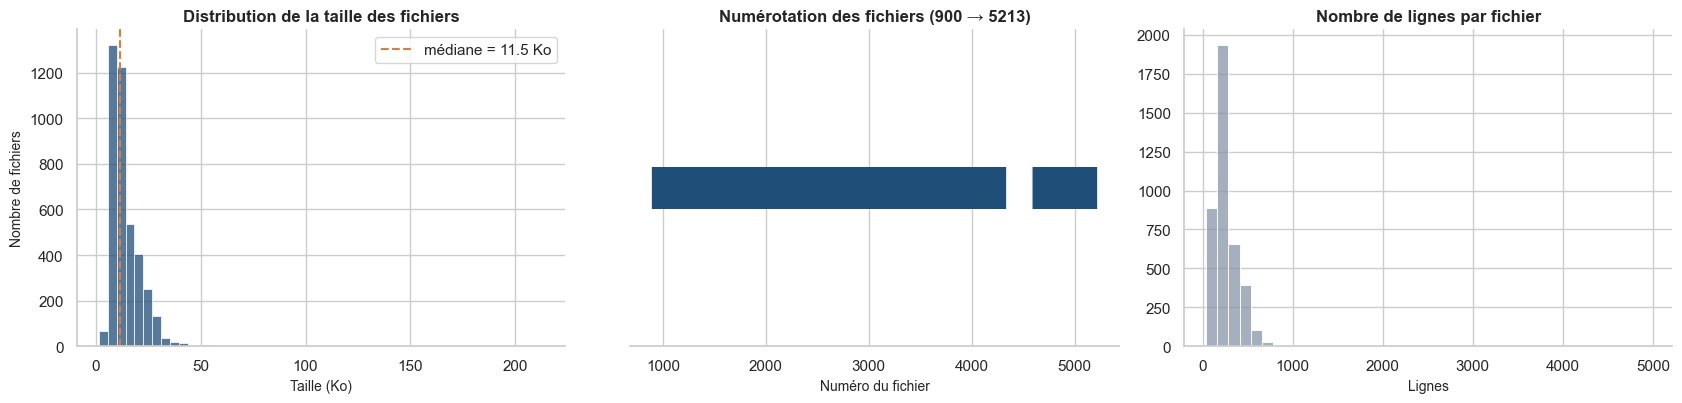

Constat : 278 numéros absents dans l'intervalle [900, 5213] → 6 plages de trous.
→ Le corpus est un SOUS-ENSEMBLE d'un jeu plus large : la numérotation n'a aucune valeur analytique (ne pas l'utiliser comme clé).


,de,à,longueur
2,4329,4599,271
0,3643,3645,3
1,4144,4144,1
3,4626,4626,1
4,4636,4636,1
5,5127,5127,1


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))

sns.histplot(files.taille_o / 1e3, bins=50, color=C["main"], ax=ax[0])
ax[0].axvline(files.taille_o.median() / 1e3, color=C["accent"], ls="--", label=f"médiane = {files.taille_o.median()/1e3:.1f} Ko")
ax[0].set(title="Distribution de la taille des fichiers", xlabel="Taille (Ko)", ylabel="Nombre de fichiers"); ax[0].legend()

nums = files.num.dropna().astype(int).sort_values()
ax[1].scatter(nums.values, np.zeros(len(nums)), marker="|", s=900, color=C["main"], alpha=.35)
ax[1].set(title=f"Numérotation des fichiers ({nums.min()} → {nums.max()})", xlabel="Numéro du fichier", yticks=[]); ax[1].spines["left"].set_visible(False)

sns.histplot(files.n_lignes, bins=40, color=C["grey"], ax=ax[2])
ax[2].set(title="Nombre de lignes par fichier", xlabel="Lignes", ylabel="")
plt.tight_layout(); plt.show()

# trous dans la numérotation
full = set(range(int(nums.min()), int(nums.max()) + 1)); manq = sorted(full - set(nums))
ranges, start = [], None
for a, b in zip(manq, manq[1:] + [None]):
    start = a if start is None else start
    if b != a + 1: ranges.append((start, a)); start = None
gaps = pd.DataFrame(ranges, columns=["de", "à"]).assign(longueur=lambda d: d["à"] - d["de"] + 1).sort_values("longueur", ascending=False)
print(f"Constat : {len(manq)} numéros absents dans l'intervalle [{nums.min()}, {nums.max()}] → {len(ranges)} plages de trous.")
print("→ Le corpus est un SOUS-ENSEMBLE d'un jeu plus large : la numérotation n'a aucune valeur analytique (ne pas l'utiliser comme clé).")
gaps.head(8)

Explication : de 4329 à 4599: 271 fichiers manquants ... 

ca explique les trous dans les fichiers

## A2. Validité XML — contrôle de structure (BF03)
Chaque fichier est soumis à un parsing **strict**. Les erreurs sont **classées par cause** : c'est ce qui permet de choisir une stratégie de réparation adaptée plutôt que d'écarter en bloc.

Fichiers valides   : 3,883 (96.2 %)
Fichiers invalides : 153 (3.8 %)
Racines rencontrées : {'PubmedArticleSet': 3883}


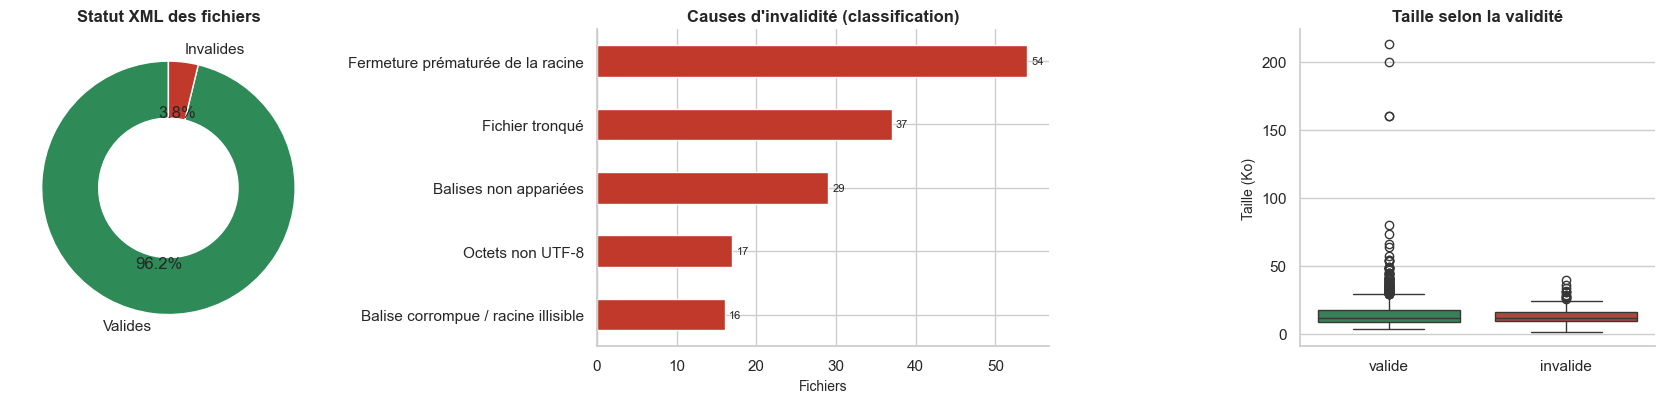

In [5]:
def classify_error(msg: str) -> str:
    m = str(msg)
    rules = [
        ("Fermeture prématurée de la racine", r"Extra content"),
        ("Balises non appariées", r"Opening and ending tag mismatch"),
        ("Fichier tronqué", r"Premature end of data"),
        ("Balise corrompue / racine illisible", r"Start tag expected|StartTag: invalid|expected '>'|not well-formed|Couldn't find end of Start Tag"),
        ("Octets non UTF-8", r"not proper UTF-8|Invalid bytes|codec|Input is not"),
    ]
    for label, rx in rules:
        if re.search(rx, m): return label
    return "Autre"

status = []
for name, b in RAW.items():
    try:
        r = etree.fromstring(b); status.append((name, "valide", "", r.tag))
    except etree.XMLSyntaxError as e:
        status.append((name, "invalide", classify_error(e), None, str(e)[:160]))
    except Exception as e:
        status.append((name, "invalide", classify_error(e), None, str(e)[:160]))
st = pd.DataFrame([dict(fichier=s[0], statut=s[1], cause=s[2], racine=s[3], message=s[4] if len(s) > 4 else "") for s in status]).set_index("fichier")
files = files.join(st)

n_ok, n_ko = (files.statut == "valide").sum(), (files.statut == "invalide").sum()
print(f"Fichiers valides   : {n_ok:,} ({pct(n_ok, len(files))} %)")
print(f"Fichiers invalides : {n_ko:,} ({pct(n_ko, len(files))} %)")
print("Racines rencontrées :", files.racine.value_counts().to_dict())

causes = files[files.statut == "invalide"].cause.value_counts()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.1, 1.4, 1.1]})
ax[0].pie([n_ok, n_ko], labels=["Valides", "Invalides"], colors=[C["ok"], C["bad"]], autopct="%1.1f%%", startangle=90, wedgeprops=dict(width=.45))
ax[0].set_title("Statut XML des fichiers")
causes.sort_values().plot.barh(color=C["bad"], ax=ax[1]); show_bar_labels(ax[1], horizontal=True)
ax[1].set(title="Causes d'invalidité (classification)", xlabel="Fichiers", ylabel="")
sns.boxplot(data=files, x="statut", y=files.taille_o / 1e3, palette={"valide": C["ok"], "invalide": C["bad"]}, ax=ax[2])
ax[2].set(title="Taille selon la validité", xlabel="", ylabel="Taille (Ko)")
plt.tight_layout(); plt.show()

**Hypothèse à vérifier :** les fichiers invalides sont-ils *regroupés* dans certaines plages de numéros (= incident lors de l'export) ou *répartis uniformément* (= bruit aléatoire) ?

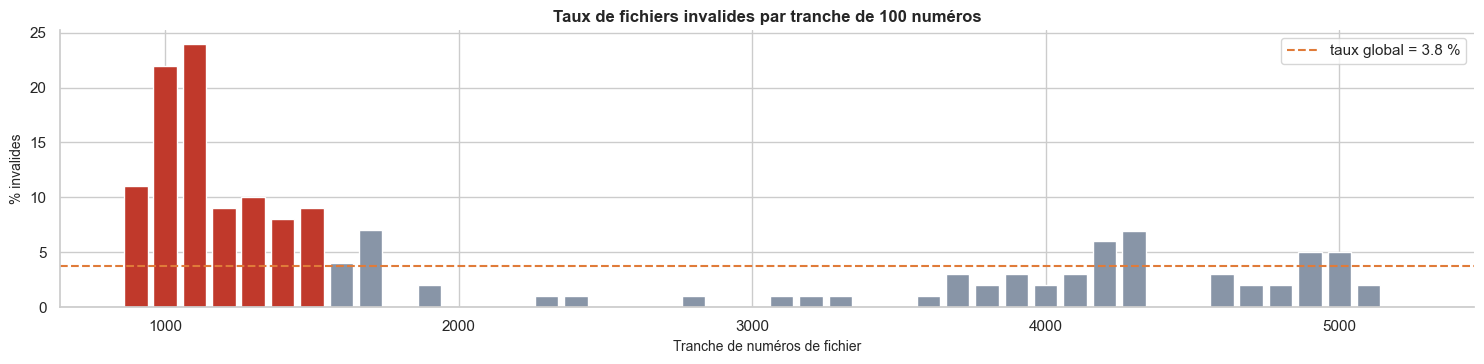

Tranches très au-dessus de la moyenne : [900, 1000, 1100, 1200, 1300, 1400, 1500]


,n,invalides,taux_invalide_%
tranche_100,,,
1100,100,24,24.00
1000,100,22,22.00
900,100,11,11.00
1300,100,10,10.00
1200,100,9,9.00
1500,100,9,9.00


In [6]:
files["tranche_100"] = (files.num // 100 * 100).astype("Int64")
tr = files.groupby("tranche_100").agg(n=("statut", "size"), invalides=("statut", lambda s: (s == "invalide").sum()))
tr["taux_invalide_%"] = 100 * tr.invalides / tr.n

fig, ax = plt.subplots(figsize=(15, 3.8))
ax.bar(tr.index.astype(int), tr["taux_invalide_%"], width=80, color=np.where(tr["taux_invalide_%"] > tr["taux_invalide_%"].mean() * 2, C["bad"], C["grey"]))
ax.axhline(100 * n_ko / len(files), color=C["accent"], ls="--", label=f"taux global = {100*n_ko/len(files):.1f} %")
ax.set(title="Taux de fichiers invalides par tranche de 100 numéros", xlabel="Tranche de numéros de fichier", ylabel="% invalides"); ax.legend()
plt.tight_layout(); plt.show()
hot = tr[tr["taux_invalide_%"] > 2 * 100 * n_ko / len(files)]
print("Tranches très au-dessus de la moyenne :", hot.index.astype(int).tolist() or "aucune (répartition diffuse)")
tr.sort_values("taux_invalide_%", ascending=False).head(6)

Les fichiers invalides ne semblent pas répartis uniformément dans le corpus. Une concentration apparaît entre les numéros 900 et 1599, avec un maximum de 24 % d’invalidité dans la tranche 1100–1199. Cette concentration peut indiquer un problème lors de l’export ou de la génération de cette partie du corpus. Toutefois, la numérotation des fichiers n’a pas de valeur métier ; elle est utilisée uniquement pour détecter cette anomalie. La clé fiable reste le PMID.

## A3. Échelle de récupération des fichiers invalides
Plutôt que d'écarter 100 % des fichiers invalides, on teste une **échelle de réparation** (du plus fidèle au plus tolérant) et on mesure **ce qu'on sauve réellement** :

| Niveau | Technique | Risque |
|---|---|---|
| **L0** | Parsing strict | aucun |
| **L1** | Décodage UTF-8 tolérant (`errors="replace"`) puis parsing strict | caractères remplacés par `�` |
| **L2** | Suppression de la fermeture prématurée de la racine + parsing `recover=True` | article **partiel** |
| **L3** | Irrécupérable par XML → test d'un sauvetage minimal par expression régulière (PMID) | information minimale |

In [7]:
def parse_ladder(b: bytes):
    """Retourne (root|None, niveau, remarque)."""
    try:
        return etree.fromstring(b), "L0 strict", ""
    except etree.XMLSyntaxError:
        pass
    txt = b.decode("utf-8", errors="replace").lstrip("\ufeff")
    n_repl = txt.count("\ufffd")
    try:
        return etree.fromstring(txt.encode("utf-8")), "L1 décodage tolérant", f"{n_repl} caractère(s) remplacé(s)"
    except etree.XMLSyntaxError:
        pass
    txt2 = re.sub(r"</PubmedArticleSet>\s*(?=<)", "", txt, count=1)      # retire une fermeture de racine placée trop tôt
    try:
        root = etree.fromstring(txt2.encode("utf-8"), etree.XMLParser(recover=True, huge_tree=True))
    except Exception:
        root = None
    if root is not None and (root.find(".//MedlineCitation") is not None or root.find(".//PubmedArticle") is not None):
        return root, "L2 réparation + recover", ""
    return None, "L3 irrécupérable (XML)", ""

lad = []
for name, b in RAW.items():
    if files.at[name, "statut"] == "valide": lad.append((name, "L0 strict", "")); continue
    root, lvl, note = parse_ladder(b)
    pm = re.search(rb"<PMID[^>]*>\s*(\d+)\s*</PMID>", b)
    lad.append((name, lvl, note))
ladder = pd.DataFrame(lad, columns=["fichier", "niveau", "remarque"]).set_index("fichier")
files = files.join(ladder)
inv = files[files.statut == "invalide"]
tab = pd.crosstab(inv.cause, inv.niveau, margins=True, margins_name="TOTAL")
tab

niveau,L1 décodage tolérant,L2 réparation + recover,L3 irrécupérable (XML),TOTAL
cause,,,,
Balise corrompue / racine illisible,0,5,11,16
Balises non appariées,0,29,0,29
Fermeture prématurée de la racine,0,53,1,54
Fichier tronqué,0,37,0,37
Octets non UTF-8,17,0,0,17
TOTAL,17,124,12,153


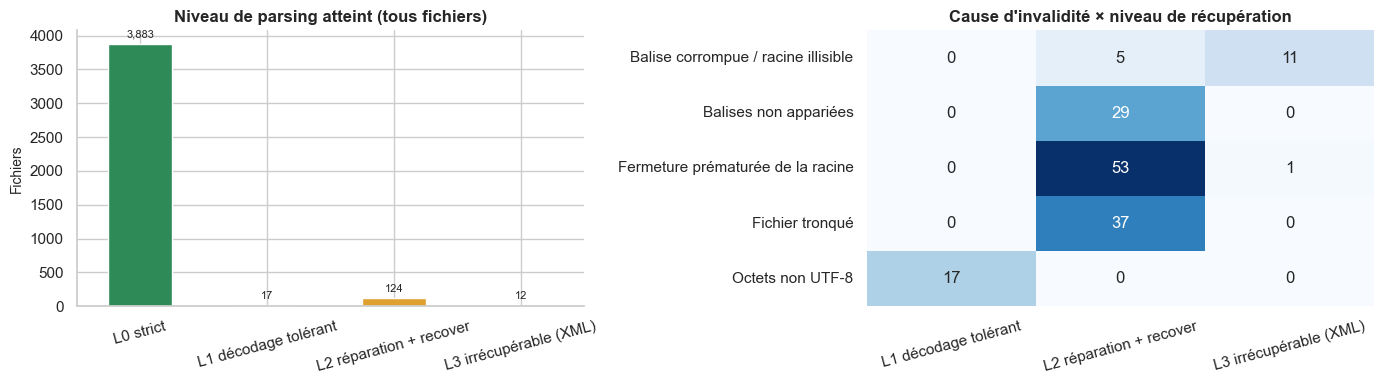

→ 141 / 153 fichiers invalides sont exploitables au moins partiellement.
→ La qualité de ce sauvetage (informations réellement présentes) est mesurée en partie D après extraction.


In [8]:
lvl_counts = files.niveau.value_counts().reindex(["L0 strict", "L1 décodage tolérant", "L2 réparation + recover", "L3 irrécupérable (XML)"]).fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
lvl_counts.plot.bar(color=[C["ok"], C["main"], C["warn"], C["bad"]], ax=ax[0], rot=15); show_bar_labels(ax[0])
ax[0].set(title="Niveau de parsing atteint (tous fichiers)", xlabel="", ylabel="Fichiers")
sns.heatmap(pd.crosstab(inv.cause, inv.niveau), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[1])
ax[1].set(title="Cause d'invalidité × niveau de récupération", xlabel="", ylabel="")
plt.setp(ax[1].get_xticklabels(), rotation=15); plt.tight_layout(); plt.show()
export(files.drop(columns=["sha1"]), "A_inventaire_fichiers")
print(f"→ {int((inv.niveau != 'L3 irrécupérable (XML)').sum())} / {len(inv)} fichiers invalides sont exploitables au moins partiellement.")
print("→ La qualité de ce sauvetage (informations réellement présentes) est mesurée en partie D après extraction.")

## A4. Structure documentaire des fichiers valides
Racine, nombre d'enregistrements par fichier, présence de types d'enregistrements inattendus (`PubmedBookArticle`), instructions de traitement (`<?pmcsd?>`), commentaires XML, DOCTYPE.

In [9]:
struct = []
for name, b in RAW.items():
    if files.at[name, "niveau"] not in ("L0 strict",): continue
    r = etree.fromstring(b)
    kids = Counter(ch.tag for ch in r if isinstance(ch.tag, str))
    struct.append(dict(fichier=name, racine=r.tag, n_PubmedArticle=kids.get("PubmedArticle", 0), n_PubmedBookArticle=kids.get("PubmedBookArticle", 0),
                       autres_enfants=sum(v for k, v in kids.items() if k not in ("PubmedArticle", "PubmedBookArticle")),
                       n_PI=len(list(r.iter(etree.ProcessingInstruction))), n_commentaires=len(list(r.iter(etree.Comment))),
                       doctype=b[:300].find(b"<!DOCTYPE") >= 0, namespaces=len(r.nsmap)))
struct = pd.DataFrame(struct).set_index("fichier")
print("Fichiers valides analysés :", len(struct))
display(pd.Series({
    "Racine unique attendue (PubmedArticleSet)": int((struct.racine == "PubmedArticleSet").sum()),
    "Fichiers à exactement 1 <PubmedArticle>": int((struct.n_PubmedArticle == 1).sum()),
    "Fichiers à ≠ 1 <PubmedArticle>": int((struct.n_PubmedArticle != 1).sum()),
    "Fichiers avec <PubmedBookArticle> (autre type d'enregistrement)": int((struct.n_PubmedBookArticle > 0).sum()),
    "Total d'enregistrements <PubmedArticle>": int(struct.n_PubmedArticle.sum()),
    "Total d'enregistrements <PubmedBookArticle>": int(struct.n_PubmedBookArticle.sum()),
    "Instructions de traitement <?...?>": int(struct.n_PI.sum()),
    "Commentaires XML": int(struct.n_commentaires.sum()),
    "DOCTYPE / DTD déclarée": int(struct.doctype.sum()),
    "Espaces de noms (namespaces)": int(struct.namespaces.sum()),
}, name="valeur").to_frame())
print("\nConstat : le grain physique est « 1 fichier = 1 article » (sauf exceptions ci-dessus) → pas de documents multi-articles à éclater.")
struct[struct.n_PubmedBookArticle > 0]

Fichiers valides analysés : 3883


,valeur
Racine unique attendue (PubmedArticleSet),3883
Fichiers à exactement 1 <PubmedArticle>,3883
Fichiers à ≠ 1 <PubmedArticle>,0
Fichiers avec <PubmedBookArticle> (autre type d'enregistrement),3
Total d'enregistrements <PubmedArticle>,3883
Total d'enregistrements <PubmedBookArticle>,3
Instructions de traitement <?...?>,67
Commentaires XML,0
DOCTYPE / DTD déclarée,0
Espaces de noms (namespaces),0



Constat : le grain physique est « 1 fichier = 1 article » (sauf exceptions ci-dessus) → pas de documents multi-articles à éclater.


,racine,n_PubmedArticle,n_PubmedBookArticle,autres_enfants,n_PI,n_commentaires,doctype,namespaces
fichier,,,,,,,,
3409.xml,PubmedArticleSet,1,1,0,0,0,False,0
4947.xml,PubmedArticleSet,1,1,0,1,0,False,0
5083.xml,PubmedArticleSet,1,1,0,0,0,False,0


---
# PARTIE B — Cartographie de l'arborescence XML (L01)
*On inventorie **tous** les chemins XML présents dans les fichiers valides — sans présupposer lesquels seront utiles.*

Pour chaque chemin on mesure : occurrences, **couverture** (% d'enregistrements où il apparaît), **cardinalité observée** (min/max par enregistrement), présence de texte, attributs.
La cardinalité conditionne directement le modèle : un chemin `0..n` impose une **relation N-N** (sous-dimension), un chemin `0..1` impose de gérer le **NULL**.

In [10]:
def walk_paths(rec):
    cnt, attrs, texts, stack = Counter(), Counter(), Counter(), []
    for ev, el in etree.iterwalk(rec, events=("start", "end")):
        if not isinstance(el.tag, str): continue
        if ev == "start":
            stack.append(el.tag); p = "/".join(stack); cnt[p] += 1
            for a in el.attrib: attrs[(p, a)] += 1
            if el.text and el.text.strip(): texts[p] += 1
        else:
            stack.pop()
    return cnt, attrs, texts

P = {}                      # chemin -> stats
ATTR_VALUES = defaultdict(Counter)
n_rec = Counter()
for name, b in RAW.items():
    if files.at[name, "niveau"] != "L0 strict": continue
    root = etree.fromstring(b)
    for rec in root:
        if not isinstance(rec.tag, str): continue
        n_rec[rec.tag] += 1
        cnt, attrs, texts = walk_paths(rec)
        for p, c in cnt.items():
            s = P.setdefault(p, dict(occ=0, recs=0, max=0, min=10**9, txt=0, attrs=set(), rtype=rec.tag))
            s["occ"] += c; s["recs"] += 1; s["max"] = max(s["max"], c); s["min"] = min(s["min"], c); s["txt"] += texts.get(p, 0)
        for (p, a) in attrs: P[p]["attrs"].add(a)
        for el in rec.iter():
            if isinstance(el.tag, str):
                for a, v in el.attrib.items():
                    k = (el.tag, a)
                    if len(ATTR_VALUES[k]) < 300 or v in ATTR_VALUES[k]: ATTR_VALUES[k][v] += 1

def card(s, nrec):
    full = s["recs"] == nrec
    if s["max"] == 1: return "1..1  obligatoire" if full else "0..1  facultatif"
    return "1..n  répétable (≥1)" if full else "0..n  répétable (facultatif)"

first_idx = {p: i for i, p in enumerate(P)}
def tree_key(p):
    parts = p.split("/")
    return tuple(first_idx["/".join(parts[:k])] for k in range(1, len(parts) + 1))
rows = []
for p in sorted(P, key=tree_key):
    s = P[p]; nrec = n_rec[s["rtype"]]
    rows.append(dict(chemin=p, balise=p.split("/")[-1], profondeur=p.count("/"), type_enreg=s["rtype"],
                     occurrences=s["occ"], enreg_presents=s["recs"], couverture_pct=100 * s["recs"] / nrec,
                     max_par_enreg=s["max"], moy_si_present=s["occ"] / s["recs"], cardinalite=card(s, nrec),
                     texte_pct=100 * s["txt"] / s["occ"], attributs=", ".join(sorted(s["attrs"]))))
paths = pd.DataFrame(rows)
paths_art = paths[paths.type_enreg == "PubmedArticle"].reset_index(drop=True)
export(paths, "B_inventaire_chemins_xml")

print(f"Enregistrements analysés : {dict(n_rec)}")
print(f"Chemins XML distincts    : {len(paths_art)} (PubmedArticle) + {int((paths.type_enreg=='PubmedBookArticle').sum())} (PubmedBookArticle)")
print(f"Profondeur maximale      : {paths_art.profondeur.max()}")
paths_art.cardinalite.value_counts().rename("nb_chemins").to_frame()

Enregistrements analysés : {'PubmedArticle': 3883, 'PubmedBookArticle': 3}
Chemins XML distincts    : 113 (PubmedArticle) + 52 (PubmedBookArticle)
Profondeur maximale      : 6


,nb_chemins
cardinalite,
0..1 facultatif,44
0..n répétable (facultatif),36
1..1 obligatoire,24
1..n répétable (≥1),9


1..1	Une colonne simple, par exemple PMID

0..1	Une colonne pouvant contenir NULL

0..n	Une table séparée si plusieurs valeurs doivent être conservées

1..n	Une table séparée pour gérer les valeurs multiples

## B1. Arbre annoté (couverture % · cardinalité)
Vue « L01 – Analyse des sources » : lecture de la structure d'un coup d'œil. `●` = toujours présent · `○` = facultatif · `×n` = répétable (max observé).

In [11]:
def print_tree(df, max_depth=5, min_cov=0.0):
    out = []
    for r in df.itertuples():
        if r.profondeur > max_depth or r.couverture_pct < min_cov: continue
        mark = "●" if r.couverture_pct >= 99.999 else "○"
        rep = f" ×{r.max_par_enreg}" if r.max_par_enreg > 1 else ""
        att = f"  @{{{r.attributs}}}" if r.attributs else ""
        out.append(f"{'   ' * r.profondeur}{mark} {r.balise}  [{r.couverture_pct:5.1f}%{rep}]{att}")
    print("\n".join(out))
print_tree(paths_art, max_depth=4)

● PubmedArticle  [100.0%]
   ● MedlineCitation  [100.0%]  @{Owner, Status}
      ● PMID  [100.0%]  @{Version}
      ● DateCreated  [100.0%]
         ● Year  [100.0%]
         ● Month  [100.0%]
         ● Day  [100.0%]
      ○ DateCompleted  [ 76.6%]
         ○ Year  [ 76.6%]
         ○ Month  [ 76.6%]
         ○ Day  [ 76.6%]
      ○ DateRevised  [ 55.1%]
         ○ Year  [ 55.1%]
         ○ Month  [ 55.1%]
         ○ Day  [ 55.1%]
      ● Article  [100.0%]  @{PubModel}
         ● Journal  [100.0%]
            ○ ISSN  [ 99.9%]  @{IssnType}
            ● JournalIssue  [100.0%]  @{CitedMedium}
            ● Title  [100.0%]
            ● ISOAbbreviation  [100.0%]
         ● ArticleTitle  [100.0%]
         ● Pagination  [100.0%]
            ● MedlinePgn  [100.0%]
         ○ Abstract  [ 99.7%]
            ○ AbstractText  [ 99.7% ×10]  @{Label, NlmCategory}
            ○ CopyrightInformation  [ 37.6%]
         ○ AuthorList  [ 99.8%]  @{CompleteYN}
            ○ Author  [ 99.8% ×180]  @{Valid

## B2. Vue graphique de la structure

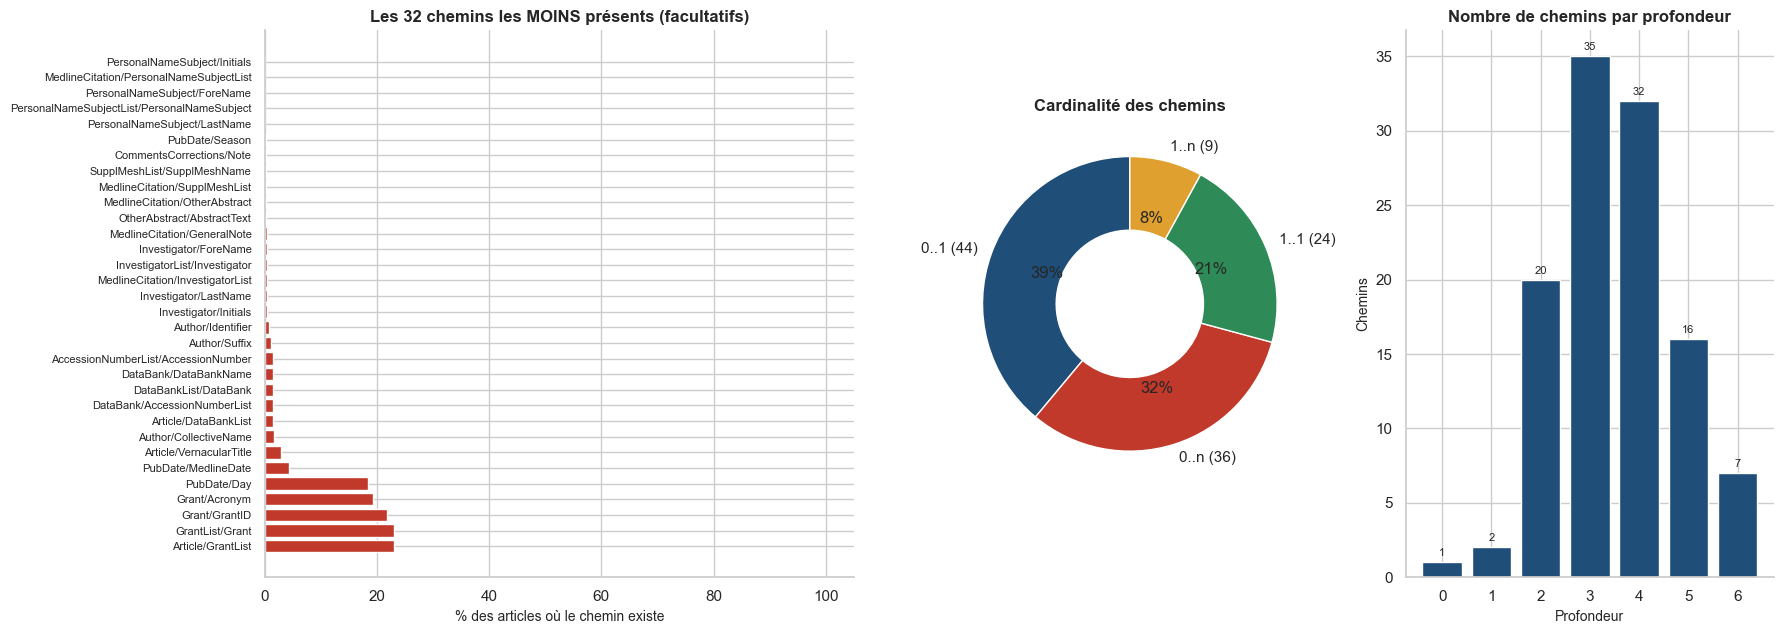

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.6, 1, 1]})

top = paths_art[(paths_art.couverture_pct < 99.999)].sort_values("couverture_pct").head(32).iloc[::-1]
lab = top.chemin.str.split("/").str[-2:].str.join("/")
colors = np.where(top.couverture_pct < 25, C["bad"], np.where(top.couverture_pct < 75, C["warn"], C["ok"]))
ax[0].barh(lab, top.couverture_pct, color=colors)
ax[0].set(title="Les 32 chemins les MOINS présents (facultatifs)", xlabel="% des articles où le chemin existe", xlim=(0, 105))
ax[0].tick_params(axis="y", labelsize=8)

cc = paths_art.cardinalite.value_counts()
CARD_COL = {"1..1": C["ok"], "0..1": C["main"], "1..n": C["warn"], "0..n": C["bad"]}
ax[1].pie(cc, labels=[f"{l.split('  ')[0]} ({v})" for l, v in cc.items()], autopct=lambda v: f"{v:.0f}%", colors=[CARD_COL[l.split("  ")[0]] for l in cc.index], startangle=90, wedgeprops=dict(width=.5))
ax[1].set_title("Cardinalité des chemins")

dd = paths_art.profondeur.value_counts().sort_index()
ax[2].bar(dd.index, dd.values, color=C["main"]); show_bar_labels(ax[2])
ax[2].set(title="Nombre de chemins par profondeur", xlabel="Profondeur", ylabel="Chemins")
plt.tight_layout(); plt.show()

## B3. Chemins répétables (0..n / 1..n) → futures relations N-N (tables de liaison)
Ce sont les relations *un-à-plusieurs* du corpus. Elles imposent, dans le modèle, de **ne pas multiplier les lignes de la table de faits**.

In [13]:
rep = paths_art[paths_art.max_par_enreg > 1].sort_values("occurrences", ascending=False)
rep_view = rep[["chemin", "occurrences", "enreg_presents", "couverture_pct", "max_par_enreg", "moy_si_present"]].head(25)
(rep_view.style
    .bar(subset=["occurrences"], color=C["light"])
    .bar(subset=["couverture_pct"], color="#bfe3c9", vmin=0, vmax=100)
    .format({"couverture_pct": "{:.1f}", "moy_si_present": "{:.2f}", "occurrences": "{:,}"})
    .hide(axis="index"))

#couverture_pct: le pourcentage d'articles dans lesquels un chemin XML est présent.

chemin,occurrences,enreg_presents,couverture_pct,max_par_enreg,moy_si_present
PubmedArticle/MedlineCitation/CommentsCorrectionsList/CommentsCorrections,"49,227",1322,34.0,576,37.24
PubmedArticle/MedlineCitation/CommentsCorrectionsList/CommentsCorrections/RefSource,"49,227",1322,34.0,576,37.24
PubmedArticle/MedlineCitation/CommentsCorrectionsList/CommentsCorrections/PMID,"49,197",1309,33.7,576,37.58
PubmedArticle/MedlineCitation/MeshHeadingList/MeshHeading,"35,778",2608,67.2,33,13.72
PubmedArticle/MedlineCitation/MeshHeadingList/MeshHeading/DescriptorName,"35,778",2608,67.2,33,13.72
PubmedArticle/MedlineCitation/Article/AuthorList/Author,"28,711",3877,99.8,180,7.41
PubmedArticle/MedlineCitation/Article/AuthorList/Author/LastName,"28,640",3873,99.7,180,7.39
PubmedArticle/MedlineCitation/Article/AuthorList/Author/Initials,"28,638",3873,99.7,180,7.39
PubmedArticle/MedlineCitation/Article/AuthorList/Author/ForeName,"28,638",3873,99.7,180,7.39
PubmedArticle/MedlineCitation/MeshHeadingList/MeshHeading/QualifierName,"23,216",2605,67.1,38,8.91


## B4. Inventaire des attributs XML (valeurs réelles)
Les attributs portent souvent l'information la plus *propre* (codes `UI`, drapeaux `MajorTopicYN`, `Status`, `IdType`…). Valeurs distinctes ≤ 12 affichées en clair.

In [14]:
arows = []
for (tag, a), cn in sorted(ATTR_VALUES.items()):
    n = sum(cn.values()); nd = len(cn)
    arows.append(dict(balise=tag, attribut=a, occurrences=n, valeurs_distinctes=f"{nd}{'+' if nd >= 300 else ''}",
                      valeurs=(", ".join(f"{k} ({v})" for k, v in cn.most_common(8)) if nd <= 12 else f"{nd} valeurs · ex. " + ", ".join(list(cn)[:3]))))
attr_df = pd.DataFrame(arows)
export(attr_df, "B_inventaire_attributs")
attr_df.style.hide(axis="index").format({"occurrences": "{:,}"})

balise,attribut,occurrences,valeurs_distinctes,valeurs
AbstractText,Label,"7,390",254,"254 valeurs · ex. BACKGROUND, METHODS, RESULTS"
AbstractText,NlmCategory,"7,421",6,"CONCLUSIONS (1867), METHODS (1811), RESULTS (1686), OBJECTIVE (1106), BACKGROUND (810), UNASSIGNED (141)"
Article,PubModel,"3,883",5,"Print-Electronic (2353), Print (947), Electronic-eCollection (264), Electronic (227), Electronic-Print (92)"
ArticleDate,DateType,"2,936",1,Electronic (2936)
ArticleId,IdType,"11,810",6,"pubmed (3886), doi (3489), pii (2394), pmc (1610), mid (428), bookaccession (3)"
ArticleTitle,book,3,2,"micad (2), mlprobe (1)"
ArticleTitle,part,3,3,"ml339 (1), CA-9 (1), Transferrin-89Zr (1)"
Author,ValidYN,"27,365",2,"Y (27354), N (11)"
AuthorList,CompleteYN,"3,692",1,Y (3692)
AuthorList,Type,3,1,authors (3)


### Constats de structure (calculés)

In [15]:
fac = paths_art[(paths_art.couverture_pct < 99.999)]
print(f"• {len(paths_art)} chemins distincts ; {len(paths_art) - len(fac)} toujours présents, {len(fac)} facultatifs ({pct(len(fac), len(paths_art))} %).")
print(f"• {len(rep)} chemins répétables → autant de relations 1-N / N-N à traiter par une sous-dimension.")
is_leaf = ~paths_art.chemin.apply(lambda p: paths_art.chemin.str.startswith(p + "/").any())
oblig_leaf = paths_art[is_leaf & (paths_art.couverture_pct >= 99.999) & (paths_art.max_par_enreg == 1)]
print(f"• Champs « socle » (feuilles présentes à 100 %, 1 seule fois) : {len(oblig_leaf)} — base des dimensions fiables :")
print("   ", ", ".join(oblig_leaf.chemin.str.replace("PubmedArticle/", "").str.replace("MedlineCitation/", "").tolist()))

• 113 chemins distincts ; 33 toujours présents, 80 facultatifs (70.8 %).
• 45 chemins répétables → autant de relations 1-N / N-N à traiter par une sous-dimension.
• Champs « socle » (feuilles présentes à 100 %, 1 seule fois) : 11 — base des dimensions fiables :
    PMID, DateCreated/Year, DateCreated/Month, DateCreated/Day, Article/Journal/Title, Article/Journal/ISOAbbreviation, Article/ArticleTitle, Article/Pagination/MedlinePgn, MedlineJournalInfo/MedlineTA, MedlineJournalInfo/NlmUniqueID, PubmedData/PublicationStatus


---
# PARTIE C — Extraction brute vers des tables « à plat »
**Aucun nettoyage ici.** On convertit le XML en tables relationnelles *fidèles à la source* (couche « raw/staging ») pour pouvoir mesurer les défauts avec pandas/SQL.

| Table | Grain (1 ligne = …) |
|---|---|
| `art` | un article (PMID) |
| `auteurs` / `investigateurs` | un auteur × article |
| `affils` | une affiliation × auteur × article |
| `mesh` / `mesh_qual` | un descripteur MeSH × article / un qualificatif × descripteur × article |
| `mots_cles` | un mot-clé × article |
| `chimie` | une substance × article |
| `types_pub`, `langues` | un type / une langue × article |
| `grants`, `historique`, `ids_article`, `commentaires`, `banques` | un élément × article |

Clé de jointure : `art_id` = PMID (ou `NOPMID:<fichier>` si le PMID est illisible, pour ne perdre aucune ligne).

In [16]:
def T(el):
    return "".join(el.itertext()) if el is not None else None

def F(el, path):
    if el is None: return None
    x = el.find(path)
    return T(x) if x is not None else None

def E(el, path):
    return el.find(path) if el is not None else None

def EA(el, path):
    return el.findall(path) if el is not None else []

def A(el, a):
    return el.get(a) if el is not None else None

def ymd(el):
    return (F(el, "Year"), F(el, "Month"), F(el, "Day")) if el is not None else (None, None, None)

TABLES = defaultdict(list)

def extract_article(art, fichier, niveau):
    mc = art.find("MedlineCitation")
    if mc is None: mc = art.find(".//MedlineCitation")
    ar = E(mc, "Article")
    if ar is None: ar = art.find(".//Article")
    pd_ = art.find("PubmedData")
    if pd_ is None: pd_ = art.find(".//PubmedData")
    pmid = F(mc, "PMID")
    pmid = pmid.strip() if pmid else None
    aid = pmid or f"NOPMID:{fichier}"
    jr = E(ar, "Journal"); ji = E(jr, "JournalIssue"); pubd = E(ji, "PubDate")
    abst = E(ar, "Abstract"); abst_parts = EA(abst, "AbstractText")
    cr, co, rv = ymd(E(mc, "DateCreated")), ymd(E(mc, "DateCompleted")), ymd(E(mc, "DateRevised"))
    ad = E(ar, "ArticleDate"); adt = ymd(ad)
    mji = E(mc, "MedlineJournalInfo")
    authors = EA(ar, "AuthorList/Author"); invs = EA(mc, "InvestigatorList/Investigator")
    mesh = EA(mc, "MeshHeadingList/MeshHeading"); kws = EA(mc, "KeywordList/Keyword")
    chems = EA(mc, "ChemicalList/Chemical"); grants = EA(ar, "GrantList/Grant")
    comms = EA(mc, "CommentsCorrectionsList/CommentsCorrections")
    hist = EA(pd_, "History/PubMedPubDate"); aids = EA(pd_, "ArticleIdList/ArticleId"); eloc = EA(ar, "ELocationID")
    ids = {A(x, "IdType"): T(x).strip() for x in aids if T(x)}
    doi = next((T(x).strip() for x in eloc if A(x, "EIdType") == "doi" and T(x)), None)
    doi_src = "ELocationID" if doi else None
    if not doi and ids.get("doi"): doi, doi_src = ids["doi"], "ArticleId"
    pii = next((T(x).strip() for x in eloc if A(x, "EIdType") == "pii" and T(x)), None) or ids.get("pii")
    orc = 0
    # ---- tables enfants --------------------------------------------------------------
    for i, au in enumerate(authors, 1):
        affs = [T(x) for x in au.findall("AffiliationInfo/Affiliation")]
        orcid = next((T(x) for x in au.findall("Identifier") if A(x, "Source") == "ORCID"), None)
        orc += orcid is not None
        TABLES["auteurs"].append(dict(art_id=aid, fichier=fichier, rang=i, nom=F(au, "LastName"), prenom=F(au, "ForeName"), initiales=F(au, "Initials"),
                                      suffixe=F(au, "Suffix"), collectif=F(au, "CollectiveName"), valid_yn=A(au, "ValidYN"), n_aff=len(affs), orcid=orcid))
        for j, a_ in enumerate(affs, 1):
            TABLES["affils"].append(dict(art_id=aid, fichier=fichier, rang_auteur=i, rang_aff=j, affiliation=a_))
    for i, au in enumerate(invs, 1):
        TABLES["investigateurs"].append(dict(art_id=aid, fichier=fichier, rang=i, nom=F(au, "LastName"), prenom=F(au, "ForeName"), initiales=F(au, "Initials"),
                                             n_aff=len(au.findall("AffiliationInfo"))))
    for i, mh in enumerate(mesh, 1):
        dn = E(mh, "DescriptorName"); quals = EA(mh, "QualifierName")
        TABLES["mesh"].append(dict(art_id=aid, fichier=fichier, rang=i, descripteur=T(dn), ui=A(dn, "UI"), majeur=A(dn, "MajorTopicYN"), type=A(dn, "Type"), n_qual=len(quals)))
        for q in quals:
            TABLES["mesh_qual"].append(dict(art_id=aid, fichier=fichier, rang_desc=i, descripteur=T(dn), qualificatif=T(q), ui=A(q, "UI"), majeur=A(q, "MajorTopicYN")))
    for i, k in enumerate(kws, 1):
        TABLES["mots_cles"].append(dict(art_id=aid, fichier=fichier, rang=i, mot_cle=T(k), majeur=A(k, "MajorTopicYN"), owner=A(k.getparent(), "Owner")))
    for ch in chems:
        TABLES["chimie"].append(dict(art_id=aid, fichier=fichier, registre=F(ch, "RegistryNumber"), substance=F(ch, "NameOfSubstance"), ui=A(E(ch, "NameOfSubstance"), "UI")))
    for pt in EA(ar, "PublicationTypeList/PublicationType"):
        TABLES["types_pub"].append(dict(art_id=aid, fichier=fichier, type=T(pt), ui=A(pt, "UI")))
    for lg in EA(ar, "Language"):
        TABLES["langues"].append(dict(art_id=aid, fichier=fichier, langue=T(lg)))
    for g in grants:
        TABLES["grants"].append(dict(art_id=aid, fichier=fichier, grant_id=F(g, "GrantID"), acronyme=F(g, "Acronym"), agence=F(g, "Agency"), pays=F(g, "Country")))
    for h in hist:
        TABLES["historique"].append(dict(art_id=aid, fichier=fichier, statut=A(h, "PubStatus"), annee=F(h, "Year"), mois=F(h, "Month"), jour=F(h, "Day"), heure=F(h, "Hour"), minute=F(h, "Minute")))
    for x in aids:
        TABLES["ids_article"].append(dict(art_id=aid, fichier=fichier, type_id=A(x, "IdType"), valeur=T(x)))
    for x in eloc:
        TABLES["elocation"].append(dict(art_id=aid, fichier=fichier, type_id=A(x, "EIdType"), valeur=T(x), valide=A(x, "ValidYN")))
    for cc in comms:
        TABLES["commentaires"].append(dict(art_id=aid, fichier=fichier, type_ref=A(cc, "RefType"), source=F(cc, "RefSource"), pmid_ref=F(cc, "PMID")))
    for db in EA(ar, "DataBankList/DataBank"):
        for acc in db.findall("AccessionNumberList/AccessionNumber"):
            TABLES["banques"].append(dict(art_id=aid, fichier=fichier, banque=F(db, "DataBankName"), accession=T(acc)))
    # ---- ligne article ----------------------------------------------------------------
    labels = [A(x, "Label") for x in abst_parts]
    abstract = "\n".join(((f"{A(x,'Label')}: " if A(x, "Label") else "") + (T(x) or "")) for x in abst_parts) if abst_parts else None
    try:
        h = hashlib.sha1(etree.tostring(art, method="c14n")).hexdigest()
    except Exception:
        h = None
    return dict(
        art_id=aid, pmid=pmid, fichier=fichier, niveau_parse=niveau, pmid_version=A(E(mc, "PMID"), "Version"),
        statut=A(mc, "Status"), owner=A(mc, "Owner"), pub_model=A(ar, "PubModel"),
        cree_a=cr[0], cree_m=cr[1], cree_j=cr[2], complete_a=co[0], complete_m=co[1], complete_j=co[2], revise_a=rv[0], revise_m=rv[1], revise_j=rv[2],
        revue=F(jr, "Title"), revue_abrev_iso=F(jr, "ISOAbbreviation"), issn=F(jr, "ISSN"), issn_type=A(E(jr, "ISSN"), "IssnType"),
        issn_liaison=F(mc, "MedlineJournalInfo/ISSNLinking"), support=A(ji, "CitedMedium"), volume=F(ji, "Volume"), numero=F(ji, "Issue"),
        pub_annee=F(pubd, "Year"), pub_mois=F(pubd, "Month"), pub_jour=F(pubd, "Day"), pub_saison=F(pubd, "Season"), pub_medline_date=F(pubd, "MedlineDate"),
        titre=F(ar, "ArticleTitle"), titre_vernaculaire=F(ar, "VernacularTitle"), pagination=F(ar, "Pagination/MedlinePgn"),
        resume=abstract, resume_n_sections=len(abst_parts), resume_labels="|".join(l for l in labels if l) or None, resume_copyright=F(abst, "CopyrightInformation"),
        autre_resume_n=len(EA(ar, "OtherAbstract")),
        art_date_a=adt[0], art_date_m=adt[1], art_date_j=adt[2], art_date_type=A(ad, "DateType"),
        pays_revue=F(mji, "Country"), medline_ta=F(mji, "MedlineTA"), nlm_id=F(mji, "NlmUniqueID"), statut_pub=F(pd_, "PublicationStatus"),
        sous_ensembles="|".join(T(x) for x in EA(mc, "CitationSubset")) or None,
        doi=doi, doi_source=doi_src, pii=pii, pmc=ids.get("pmc"), mid=ids.get("mid"), id_pubmed_article=ids.get("pubmed"),
        n_auteurs=len(authors), n_collectifs=sum(F(a_, "CollectiveName") is not None for a_ in authors), n_investigateurs=len(invs),
        n_auteurs_invalid=sum(A(a_, "ValidYN") == "N" for a_ in authors), n_aff_total=sum(len(a_.findall("AffiliationInfo")) for a_ in authors),
        n_auteurs_avec_aff=sum(1 for a_ in authors if a_.find("AffiliationInfo") is not None), n_orcid=orc,
        liste_auteurs_complete=A(E(ar, "AuthorList"), "CompleteYN"), liste_auteurs_type=A(E(ar, "AuthorList"), "Type"),
        n_mots_cles=len(kws), n_mesh=len(mesh), n_mesh_majeurs=sum(A(E(m_, "DescriptorName"), "MajorTopicYN") == "Y" for m_ in mesh),
        n_qualificatifs=sum(len(EA(m_, "QualifierName")) for m_ in mesh), n_chimie=len(chems), n_grants=len(grants), n_commentaires=len(comms),
        n_types_pub=len(EA(ar, "PublicationTypeList/PublicationType")), n_langues=len(EA(ar, "Language")), n_historique=len(hist), n_ids=len(aids),
        n_pi=len(list(art.iter(etree.ProcessingInstruction))), a_suppl_mesh=len(EA(mc, "SupplMeshList/SupplMeshName")), a_note=E(mc, "GeneralNote") is not None,
        hash_contenu=h)

def extract_book(bk, fichier):
    bd = E(bk, "BookDocument")
    TABLES["livres"].append(dict(fichier=fichier, pmid=F(bd, "PMID"), titre=F(bd, "ArticleTitle"), titre_livre=F(bd, "Book/BookTitle"),
                                 editeur=F(bd, "Book/Publisher/PublisherName"), annee=F(bd, "Book/PubDate/Year"), n_sections=len(bd.findall(".//Sections/Section")) if bd is not None else 0))

import time
t0 = time.time(); art_rows = []; extr_log = []
for name, b in RAW.items():
    root, lvl, note = (etree.fromstring(b), "L0 strict", "") if files.at[name, "niveau"] == "L0 strict" else parse_ladder(b)
    if root is None:
        pm = re.search(rb"<PMID[^>]*>\s*(\d+)\s*</PMID>", b)
        extr_log.append((name, lvl, "irrécupérable", pm.group(1).decode() if pm else None)); continue
    arts = root.findall(".//PubmedArticle") or ([root] if root.find(".//MedlineCitation") is not None else [])
    for art in arts:
        art_rows.append(extract_article(art, name, lvl))
    for bk in root.findall(".//PubmedBookArticle"):
        extract_book(bk, name)
    extr_log.append((name, lvl, f"{len(arts)} article(s)", None))

art = pd.DataFrame(art_rows)
T_ = {k: pd.DataFrame(v) for k, v in TABLES.items()}
globals().update(T_)
print(f"Extraction terminée en {time.time()-t0:.1f} s")
inv_tables = pd.DataFrame({"lignes": {k: len(v) for k, v in {"art": art, **T_}.items()},
                           "colonnes": {k: v.shape[1] for k, v in {"art": art, **T_}.items()},
                           "articles_distincts": {k: v.art_id.nunique() if "art_id" in v else np.nan for k, v in {"art": art, **T_}.items()}})
inv_tables.sort_values("lignes", ascending=False)

Extraction terminée en 7.2 s


,lignes,colonnes,articles_distincts
commentaires,49970,5,"1,346.00"
mesh,36105,8,"2,631.00"
auteurs,29494,11,"3,960.00"
mesh_qual,23422,7,"2,626.00"
historique,21334,8,"3,962.00"
affils,17469,5,"3,864.00"
mots_cles,12851,6,"2,141.00"
ids_article,12103,4,"3,954.00"
chimie,8261,5,"1,864.00"
types_pub,7923,4,"3,966.00"


In [17]:
# Articles sauvés par niveau et fichiers définitivement perdus
lost = [x for x in extr_log if x[2] == "irrécupérable"]
print("Articles extraits par niveau de parsing :", art.niveau_parse.value_counts().to_dict())
print(f"Fichiers non exploitables par XML : {len(lost)} → PMID retrouvé par expression régulière pour {sum(1 for x in lost if x[3])} d'entre eux")
art_ok = art[art.niveau_parse.isin(["L0 strict"])].copy()          # population de référence (structure 100 % fiable)
art_rec = art[~art.niveau_parse.isin(["L0 strict"])].copy()        # articles réparés (à traiter séparément)
def only_ok(df):
    """Lignes d'une table enfant provenant UNIQUEMENT des fichiers valides (évite de compter les copies réparées)."""
    return df.merge(art_ok[["art_id", "fichier"]], on=["art_id", "fichier"])

print(f"\nPopulation de référence 'art_ok'  : {len(art_ok):,} articles (L0)")
print(f"Population réparée 'art_rec'      : {len(art_rec):,} articles (L1/L2)")

Articles extraits par niveau de parsing : {'L0 strict': 3883, 'L2 réparation + recover': 139, 'L1 décodage tolérant': 17}
Fichiers non exploitables par XML : 12 → PMID retrouvé par expression régulière pour 12 d'entre eux

Population de référence 'art_ok'  : 3,883 articles (L0)
Population réparée 'art_rec'      : 156 articles (L1/L2)


---
# PARTIE D — Profil détaillé des colonnes
*On ne se limite à aucune colonne : les **77 colonnes article** et toutes les tables enfants sont profilées.* Les décisions de conservation viennent **après** (partie I).

## D0. Colonnes dérivées (dates normalisées) — nécessaires aux profils suivants
Les dates PubMed existent sous plusieurs formes (`Year/Month/Day` numériques, mois textuel `Jan`, `MedlineDate` libre type « 2015 Jan-Feb », `Season`). On les convertit **sans écraser** les valeurs brutes.

In [18]:
MONTHS = {m: i for i, m in enumerate(["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], 1)}

def mnum(x):
    if x is None or (isinstance(x, float) and np.isnan(x)) or pd.isna(x): return np.nan
    x = str(x).strip()
    if x.isdigit(): return int(x)
    return MONTHS.get(x[:3].lower(), np.nan)

def to_dt(y, m, d):
    df_ = pd.DataFrame({"year": pd.to_numeric(y, errors="coerce"), "month": m.map(mnum).fillna(1) if m is not None else 1,
                        "day": pd.to_numeric(d, errors="coerce").fillna(1) if d is not None else 1})
    return pd.to_datetime(df_, errors="coerce")

def add_derived(df):
    df = df.copy()
    df["cree_dt"] = to_dt(df.cree_a, df.cree_m, df.cree_j)
    df["complete_dt"] = to_dt(df.complete_a, df.complete_m, df.complete_j)
    df["revise_dt"] = to_dt(df.revise_a, df.revise_m, df.revise_j)
    df["art_dt"] = to_dt(df.art_date_a, df.art_date_m, df.art_date_j)
    df["pub_annee_eff"] = pd.to_numeric(df.pub_annee, errors="coerce").fillna(pd.to_numeric(df.pub_medline_date.str.extract(r"(\d{4})")[0], errors="coerce"))
    df["pub_dt"] = to_dt(df.pub_annee_eff, df.pub_mois, df.pub_jour)
    df["pub_annee_eff"] = df.pub_annee_eff.astype("Int64")
    df["pub_precision"] = np.select(
        [df.pub_annee.notna() & df.pub_mois.notna() & df.pub_jour.notna(), df.pub_annee.notna() & df.pub_mois.notna(),
         df.pub_annee.notna() & df.pub_saison.notna(), df.pub_annee.notna(), df.pub_medline_date.notna()],
        ["Année+Mois+Jour", "Année+Mois", "Année+Saison", "Année seule", "MedlineDate (texte libre)"], default="Aucune")
    df["longueur_titre"] = df.titre.str.len(); df["mots_titre"] = df.titre.str.split().str.len()
    df["longueur_resume"] = df.resume.str.len(); df["mots_resume"] = df.resume.str.split().str.len()
    return df

art = add_derived(art)
art_ok, art_rec = art[art.niveau_parse == "L0 strict"].copy(), art[art.niveau_parse != "L0 strict"].copy()
print("Colonnes dérivées ajoutées :", [c for c in art.columns if c.endswith("_dt") or c in ("pub_annee_eff", "pub_precision", "longueur_titre", "mots_titre", "longueur_resume", "mots_resume")])

Colonnes dérivées ajoutées : ['cree_dt', 'complete_dt', 'revise_dt', 'art_dt', 'pub_annee_eff', 'pub_dt', 'pub_precision', 'longueur_titre', 'mots_titre', 'longueur_resume', 'mots_resume']


## D1. Vue d'ensemble : profil automatique de **toutes** les colonnes de `art`
Pour chaque colonne : type inféré, taux de manquants, valeurs vides (`""`), cardinalité, valeur dominante, longueur des textes. Les barres rouges signalent les colonnes à fort taux de manquants.

In [19]:
GROUPES = {
    "Identification": ["art_id", "pmid", "pmid_version", "fichier", "niveau_parse", "doi", "doi_source", "pii", "pmc", "mid", "id_pubmed_article", "hash_contenu"],
    "Statut & édition": ["statut", "owner", "pub_model", "statut_pub", "sous_ensembles", "support", "a_note"],
    "Dates": ["cree_a", "cree_m", "cree_j", "complete_a", "complete_m", "complete_j", "revise_a", "revise_m", "revise_j", "art_date_a", "art_date_m", "art_date_j",
              "art_date_type", "pub_annee", "pub_mois", "pub_jour", "pub_saison", "pub_medline_date", "cree_dt", "complete_dt", "revise_dt", "art_dt", "pub_dt", "pub_annee_eff", "pub_precision"],
    "Revue": ["revue", "revue_abrev_iso", "issn", "issn_type", "issn_liaison", "volume", "numero", "pays_revue", "medline_ta", "nlm_id", "pagination"],
    "Texte": ["titre", "titre_vernaculaire", "resume", "resume_n_sections", "resume_labels", "resume_copyright", "autre_resume_n", "longueur_titre", "mots_titre", "longueur_resume", "mots_resume"],
    "Auteurs": ["n_auteurs", "n_collectifs", "n_investigateurs", "n_auteurs_invalid", "n_aff_total", "n_auteurs_avec_aff", "n_orcid", "liste_auteurs_complete", "liste_auteurs_type"],
    "Thématique": ["n_mots_cles", "n_mesh", "n_mesh_majeurs", "n_qualificatifs", "n_chimie", "a_suppl_mesh", "n_types_pub", "n_langues"],
    "Autres": ["n_grants", "n_commentaires", "n_historique", "n_ids", "n_pi"],
}
COL2GRP = {c: g for g, cs in GROUPES.items() for c in cs}

def profile(df, groupes=None):
    n = len(df); rows = []
    for c in df.columns:
        s = df[c]
        num = pd.api.types.is_numeric_dtype(s) or pd.api.types.is_datetime64_any_dtype(s)
        vide = int((s.astype("string").str.strip() == "").sum()) if not num else 0
        nn = int(s.notna().sum()) - vide
        vc = s[s.notna()].value_counts().head(1)
        r = dict(colonne=c, groupe=(groupes or {}).get(c, ""), type="date" if pd.api.types.is_datetime64_any_dtype(s) else ("numérique" if num else "texte"),
                 manquants_pct=100 * (n - nn) / n, vides=vide, distincts=int(s.nunique()), unicite_pct=100 * s.nunique() / max(nn, 1),
                 dominant=(str(vc.index[0])[:35] if len(vc) else None), dominant_pct=(100 * vc.iloc[0] / max(nn, 1) if len(vc) else np.nan))
        if num and not pd.api.types.is_datetime64_any_dtype(s):
            r.update(min=s.min(), mediane=s.median(), max=s.max())
        elif pd.api.types.is_datetime64_any_dtype(s):
            r.update(min=str(s.min())[:10], mediane=None, max=str(s.max())[:10])
        else:
            L = s.dropna().astype(str).str.len(); r.update(min=int(L.min()) if len(L) else None, mediane=L.median() if len(L) else None, max=int(L.max()) if len(L) else None)
        rows.append(r)
    return pd.DataFrame(rows).set_index("colonne")

prof_art = profile(art_ok.drop(columns=["hash_contenu", "niveau_parse"]), COL2GRP)
export(prof_art, "D_profil_colonnes_article")
(prof_art.sort_values(["groupe", "manquants_pct"], ascending=[True, False]).style
    .bar(subset=["manquants_pct"], color="#f5b7b1", vmin=0, vmax=100)
    .background_gradient(subset=["unicite_pct"], cmap="Blues", vmin=0, vmax=100)
    .format({"manquants_pct": "{:.1f}", "unicite_pct": "{:.1f}", "dominant_pct": "{:.1f}", "mediane": "{:,.1f}"}, na_rep="—"))

,groupe,type,manquants_pct,vides,distincts,unicite_pct,dominant,dominant_pct,min,mediane,max
colonne,,,,,,,,,,,
liste_auteurs_type,Auteurs,texte,100.0,0,0,0.0,—,—,—,—,—
liste_auteurs_complete,Auteurs,texte,4.9,0,1,0.0,Y,100.0,1,1.0,1
n_auteurs,Auteurs,numérique,0.0,0,47,1.2,5,11.7,0,6.0,180
n_collectifs,Auteurs,numérique,0.0,0,4,0.1,0,98.4,0,0.0,5
n_investigateurs,Auteurs,numérique,0.0,0,17,0.4,0,99.6,0,0.0,803
n_auteurs_invalid,Auteurs,numérique,0.0,0,3,0.1,0,99.8,0,0.0,2
n_aff_total,Auteurs,numérique,0.0,0,46,1.2,1,54.3,0,1.0,180
n_auteurs_avec_aff,Auteurs,numérique,0.0,0,43,1.1,1,54.3,0,1.0,180
n_orcid,Auteurs,numérique,0.0,0,6,0.2,0,99.3,0,0.0,10


In [20]:
print(f"Colonnes : {prof_art.shape[0]} | 100 % renseignées : {(prof_art.manquants_pct == 0).sum()} | "
      f"≥ 50 % manquantes : {(prof_art.manquants_pct >= 50).sum()} | constantes (1 seule valeur) : {(prof_art.distincts <= 1).sum()}")
print("Colonnes constantes (aucune valeur analytique) :", prof_art[prof_art.distincts <= 1].index.tolist())
print("Colonnes quasi-uniques (≥ 95 % de valeurs distinctes → candidats clés / texte libre) :",
      prof_art[(prof_art.unicite_pct >= 95) & (prof_art.manquants_pct < 50)].index.tolist())

#colonnes : 86 => 77 depuis art (partie C) + 11 colonnes dérivées (date partie D0) - 2 colonnes supprimées (hash_contenu, niveau_parse)

Colonnes : 86 | 100 % renseignées : 47 | ≥ 50 % manquantes : 9 | constantes (1 seule valeur) : 6
Colonnes constantes (aucune valeur analytique) : ['pmid_version', 'owner', 'autre_resume_n', 'art_date_type', 'liste_auteurs_complete', 'liste_auteurs_type']
Colonnes quasi-uniques (≥ 95 % de valeurs distinctes → candidats clés / texte libre) : ['art_id', 'pmid', 'fichier', 'titre', 'resume', 'doi', 'pii', 'id_pubmed_article']


1. Les 6 colonnes constantes sont à écarter du Data Warehouse.
Une colonne qui a une seule valeur pour les 3 883 articles n’apporte aucune information. On ne peut ni filtrer, ni grouper, ni comparer avec elle. Exemples confirmés par ton notebook : owner vaut toujours NLM et pmid_version vaut toujours 1.

2. Les 8 colonnes quasi-uniques n’ont pas toutes le même rôle.

| Colonne | Conclusion |
|---|---|
| `pmid`, `art_id` | Clés de l’article : un PMID unique par article. |
| `fichier` | Colonne technique de traçabilité, pas une donnée métier. |
| `id_pubmed_article` | Redondante avec `pmid` (D2 montre 3 883 identiques sur 3 883). |
| `doi`, `pii` | Identifiants secondaires, utiles mais absents pour certains articles. |
| `titre`, `resume` | Texte libre : on ne peut pas grouper dessus, ce sont des attributs de l’article. |

Ce ne sont donc pas des candidats dimension, car une dimension sert à regrouper et ces colonnes sont presque toutes différentes.

3. La qualité est globalement bonne.
47 colonnes sur 86 sont renseignées à 100 %, donc fiables. Les 9 colonnes manquantes à 50 % ou plus sont fragiles. On ne les supprime pas pour autant : la partie E montre qu’un manquant est souvent structurel, c’est-à-dire normal. Exemple : une notice non indexée n’a pas de MeSH.

## D2. Identifiants : PMID, DOI, PMC, ISSN, NLM ID
Un identifiant ne sert de clé que s'il est **présent, unique et bien formé**.

,renseignés,format_valide,format_invalide,couverture_%,validité_%
PMID,3883,3883,0,100.0,100.0
ISSN,3878,3877,1,99.9,100.0
ISSN de liaison,3794,3794,0,97.7,100.0
DOI,3522,3518,4,90.7,99.9
PMC,1610,1610,0,41.5,100.0
NLM Unique ID,3883,3818,65,100.0,98.3


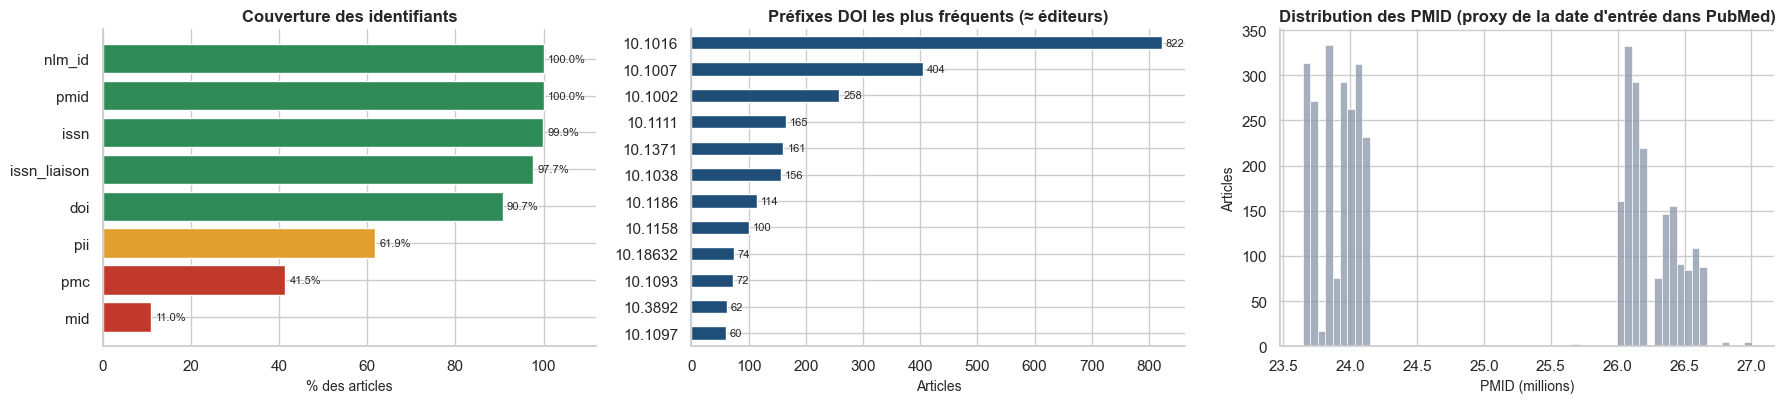

PMID : min = 23,643,526 · max = 27,000,927 · médiane = 24,101,043 · versions : {'1': 3883}
Cohérence PMID ↔ ArticleId[pubmed] : 3,883 identiques / 3,883 comparables
Origine du DOI : {'ELocationID': 3371, None: 361, 'ArticleId': 151}


In [21]:
RX = dict(pmid=r"^\d{1,9}$", issn=r"^\d{4}-\d{3}[\dXx]$", doi=r"^10\.\d{4,9}/\S+$", pmc=r"^PMC\d+$", nlm=r"^\d{6,9}$")
def valid_rate(s, rx):
    s = s.dropna().astype(str).str.strip(); return pd.Series({"renseignés": len(s), "format_valide": int(s.str.match(rx).sum()), "format_invalide": int((~s.str.match(rx)).sum())})

idv = pd.DataFrame({"PMID": valid_rate(art_ok.pmid, RX["pmid"]), "ISSN": valid_rate(art_ok.issn, RX["issn"]), "ISSN de liaison": valid_rate(art_ok.issn_liaison, RX["issn"]),
                    "DOI": valid_rate(art_ok.doi, RX["doi"]), "PMC": valid_rate(art_ok.pmc, RX["pmc"]), "NLM Unique ID": valid_rate(art_ok.nlm_id, RX["nlm"])}).T
idv["couverture_%"] = 100 * idv["renseignés"] / len(art_ok); idv["validité_%"] = 100 * idv.format_valide / idv["renseignés"]
display(idv.style.format({"couverture_%": "{:.1f}", "validité_%": "{:.1f}"}).bar(subset=["couverture_%", "validité_%"], color="#bfe3c9", vmin=0, vmax=100))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
cov = (100 * art_ok[["pmid", "doi", "pmc", "pii", "mid", "issn", "issn_liaison", "nlm_id"]].notna().mean()).sort_values()
ax[0].barh(cov.index, cov.values, color=[C["bad"] if v < 50 else C["warn"] if v < 90 else C["ok"] for v in cov.values]); show_bar_labels(ax[0], "{:.1f}%", horizontal=True)
ax[0].set(title="Couverture des identifiants", xlim=(0, 112), xlabel="% des articles")
pref = art_ok.doi.dropna().str.extract(r"^(10\.\d+)")[0].value_counts().head(12).sort_values()
pref.plot.barh(color=C["main"], ax=ax[1]); show_bar_labels(ax[1], horizontal=True); ax[1].set(title="Préfixes DOI les plus fréquents (≈ éditeurs)", xlabel="Articles", ylabel="")
sns.histplot(pd.to_numeric(art_ok.pmid, errors="coerce") / 1e6, bins=60, color=C["grey"], ax=ax[2])
ax[2].set(title="Distribution des PMID (proxy de la date d'entrée dans PubMed)", xlabel="PMID (millions)", ylabel="Articles")
plt.tight_layout(); plt.show()

pm_num = pd.to_numeric(art_ok.pmid, errors="coerce")
print(f"PMID : min = {pm_num.min():,.0f} · max = {pm_num.max():,.0f} · médiane = {pm_num.median():,.0f} · versions : {art_ok.pmid_version.value_counts().to_dict()}")
print(f"Cohérence PMID ↔ ArticleId[pubmed] : {int((art_ok.pmid == art_ok.id_pubmed_article).sum()):,} identiques / {int(art_ok.id_pubmed_article.notna().sum()):,} comparables")
print(f"Origine du DOI : {art_ok.doi_source.value_counts(dropna=False).to_dict()}")

#le DOI est un identifiant secondaire qui permet de retrouver une publication scientifique, même en dehors de PubMed. (identifiant géré par organisation internationale DOI pas par PubMed)

## D3. Statut éditorial, modèle de publication, support
Ces colonnes de faible cardinalité sont de **bons candidats d'attributs de dimension** (filtres) — sous réserve de comprendre leur sens.

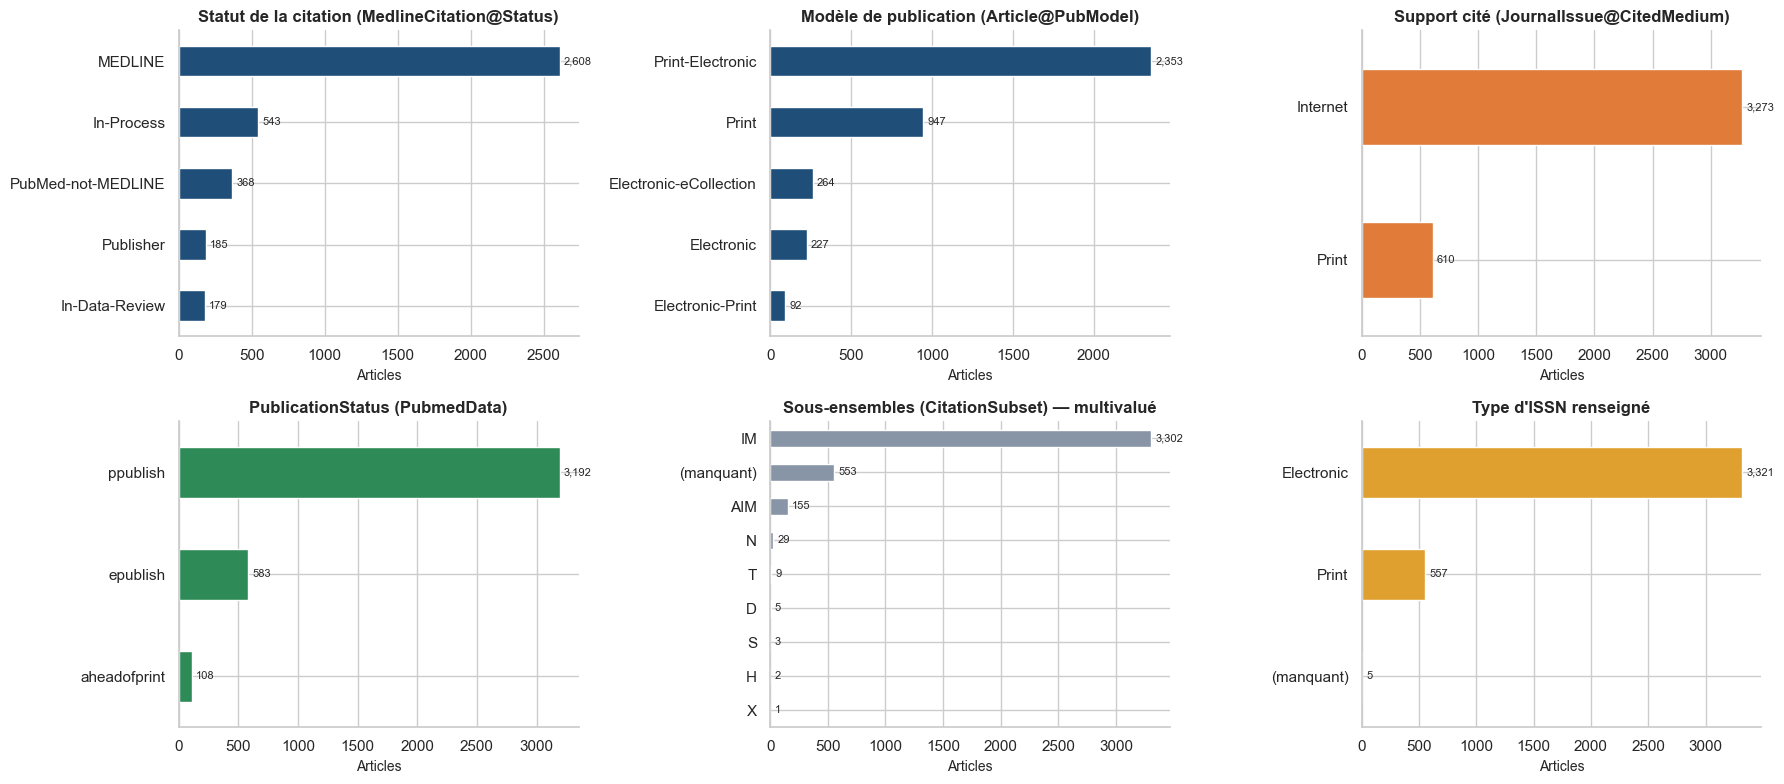

Owner : {'NLM': 3883}
→ Le statut influence la complétude (ex. 'Publisher' = notice non indexée → pas de MeSH) : voir partie E.


In [22]:
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
def vbar(s, a, title, color=C["main"], top=12):
    v = s.fillna("(manquant)").value_counts().head(top).sort_values()
    v.plot.barh(color=color, ax=a); show_bar_labels(a, horizontal=True); a.set(title=title, xlabel="Articles", ylabel="")
vbar(art_ok.statut, ax[0, 0], "Statut de la citation (MedlineCitation@Status)")
vbar(art_ok.pub_model, ax[0, 1], "Modèle de publication (Article@PubModel)")
vbar(art_ok.support, ax[0, 2], "Support cité (JournalIssue@CitedMedium)", C["accent"])
vbar(art_ok.statut_pub, ax[1, 0], "PublicationStatus (PubmedData)", C["ok"])
vbar(art_ok.sous_ensembles.str.split("|").explode(), ax[1, 1], "Sous-ensembles (CitationSubset) — multivalué", C["grey"])
vbar(art_ok.issn_type, ax[1, 2], "Type d'ISSN renseigné", C["warn"])
plt.tight_layout(); plt.show()
print("Owner :", art_ok.owner.value_counts(dropna=False).to_dict())
print("→ Le statut influence la complétude (ex. 'Publisher' = notice non indexée → pas de MeSH) : voir partie E.")

## D4. Les dates — profil approfondi
Une publication a **plusieurs dates aux rôles distincts** (création de la notice, complétion, révision, date d'article électronique, date de publication de fascicule, historique). Choisir *la* date de la dimension Temps est une décision structurante.

,couverture,rôle métier
Date de création (DateCreated),100.0%,Entrée dans la base
Date de complétion (DateCompleted),76.6%,Fin d'indexation MeSH
Date de révision (DateRevised),55.1%,Dernière mise à jour
Date d'article électronique (ArticleDate),75.6%,Mise en ligne de l'article
Date de publication (PubDate : année),100.0%,Fascicule/volume de la revue
PubDate précise au mois,75.5%,Granularité mensuelle disponible


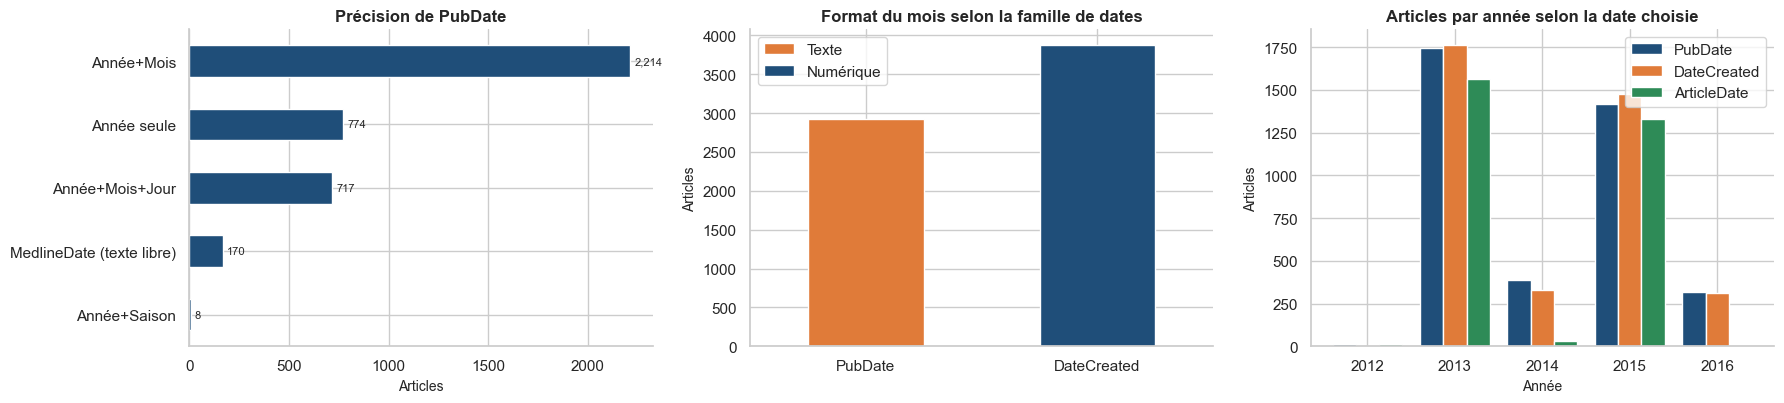

In [23]:
fam = pd.DataFrame({
    "Date de création (DateCreated)": art_ok.cree_dt.notna().mean(), "Date de complétion (DateCompleted)": art_ok.complete_dt.notna().mean(),
    "Date de révision (DateRevised)": art_ok.revise_dt.notna().mean(), "Date d'article électronique (ArticleDate)": art_ok.art_dt.notna().mean(),
    "Date de publication (PubDate : année)": art_ok.pub_annee_eff.notna().mean(), "PubDate précise au mois": art_ok.pub_dt.notna().mean() * (art_ok.pub_mois.notna().mean()),
}, index=["couverture"]).T * 100
fam["rôle métier"] = ["Entrée dans la base", "Fin d'indexation MeSH", "Dernière mise à jour", "Mise en ligne de l'article", "Fascicule/volume de la revue", "Granularité mensuelle disponible"]
display(fam.style.format({"couverture": "{:.1f}%"}).bar(subset=["couverture"], color="#bfe3c9", vmin=0, vmax=100))

prec = art_ok.pub_precision.value_counts()
mois_fmt = art_ok.pub_mois.dropna().map(lambda x: "Numérique (01–12)" if str(x).isdigit() else "Texte (Jan, Feb…)").value_counts()
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
prec.sort_values().plot.barh(color=C["main"], ax=ax[0]); show_bar_labels(ax[0], horizontal=True); ax[0].set(title="Précision de PubDate", xlabel="Articles", ylabel="")
mois_cmp = pd.DataFrame({"PubDate": art_ok.pub_mois.dropna().map(lambda x: "Numérique" if str(x).isdigit() else "Texte"),
                         "DateCreated": art_ok.cree_m.dropna().map(lambda x: "Numérique" if str(x).isdigit() else "Texte")})
pd.concat({k: v.value_counts() for k, v in mois_cmp.items()}, axis=1).fillna(0).T.plot.bar(stacked=True, color=[C["accent"], C["main"]], ax=ax[1], rot=0)
ax[1].set(title="Format du mois selon la famille de dates", ylabel="Articles"); ax[1].legend(title="")
yrs = pd.DataFrame({"PubDate": art_ok.pub_annee_eff.value_counts(), "DateCreated": pd.to_numeric(art_ok.cree_a).value_counts(), "ArticleDate": pd.to_numeric(art_ok.art_date_a).value_counts()}).sort_index()
yrs = yrs[yrs.index >= 2005]; yrs.index = yrs.index.astype(int)
yrs.plot.bar(ax=ax[2], color=[C["main"], C["accent"], C["ok"]], width=.8, rot=0); ax[2].set(title="Articles par année selon la date choisie", xlabel="Année", ylabel="Articles")
plt.tight_layout(); plt.show()

Fenêtre de publication : 2012 → 2016 | médiane 2014 | 5 années distinctes
Répartition par année de PubDate : {2012: '0.3 %', 2013: '44.9 %', 2014: '10.0 %', 2015: '36.6 %', 2016: '8.2 %'}
→ Fenêtre TRÈS ÉTROITE (5 années) et distribution en « dents de scie » : l'axe temporel annuel sera pauvre ; prévoir mois/trimestre dans Dim_Temps.
Articles dont PubDate est un texte libre (MedlineDate) : 170 → exemples : ['2016 Jan-Feb', '2015 Jul-Aug', '2015', '2015 Nov 12-25', '2016 Jan-Feb', '2015 Sep-Oct']
Articles avec saison (Spring…) : 8


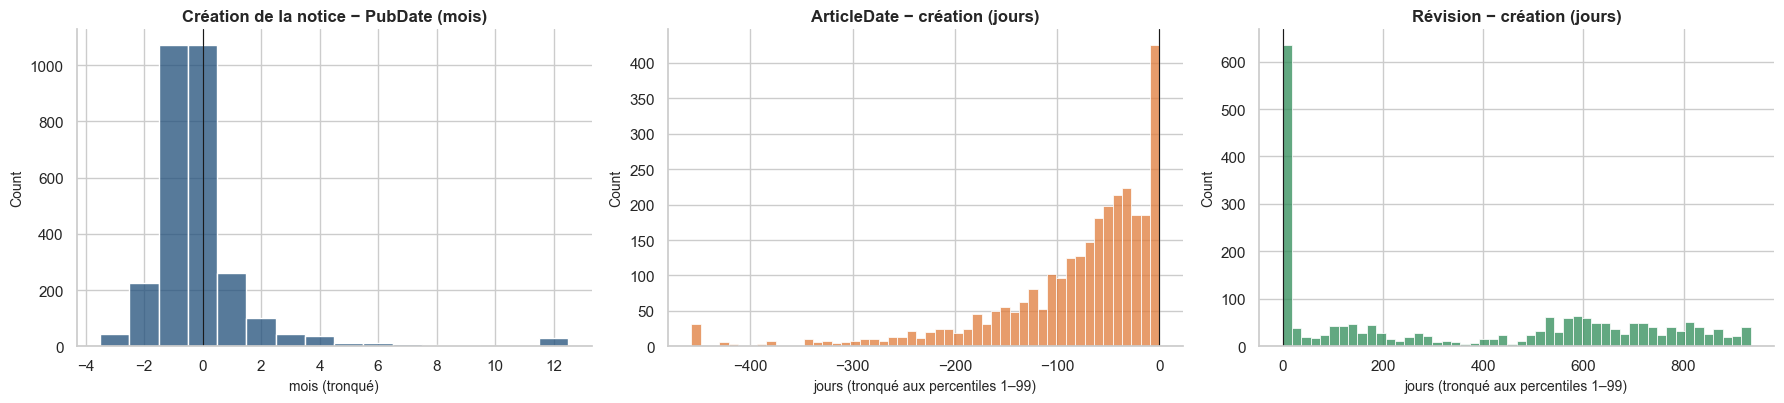

Notice créée AVANT le mois de PubDate : 45.8 % · le MÊME mois : 36.5 % · APRÈS : 17.7 %.


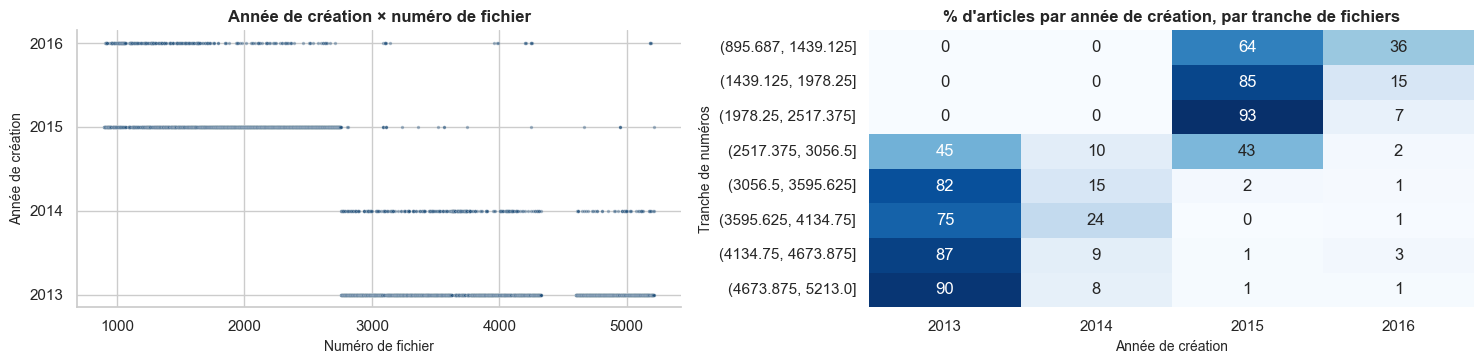

In [24]:
ys = art_ok.pub_annee_eff.dropna().astype(int)
print(f"Fenêtre de publication : {ys.min()} → {ys.max()} | médiane {int(ys.median())} | {ys.nunique()} années distinctes")
yc = ys.value_counts().sort_index()
print("Répartition par année de PubDate :", {int(k): f"{100*v/len(ys):.1f} %" for k, v in yc.items()})
print(f"→ Fenêtre TRÈS ÉTROITE ({ys.nunique()} années) et distribution en « dents de scie » : l'axe temporel annuel sera pauvre ; prévoir mois/trimestre dans Dim_Temps.")
print(f"Articles dont PubDate est un texte libre (MedlineDate) : {art_ok.pub_medline_date.notna().sum()} → exemples : {art_ok.pub_medline_date.dropna().head(6).tolist()}")
print(f"Articles avec saison (Spring…) : {art_ok.pub_saison.notna().sum()}")

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
lag1 = ((pd.to_numeric(art_ok.cree_a) * 12 + art_ok.cree_m.map(mnum)) - (art_ok.pub_annee_eff * 12 + art_ok.pub_mois.map(mnum))).dropna(); lag2 = (art_ok.art_dt - art_ok.cree_dt).dt.days.dropna(); lag3 = (art_ok.revise_dt - art_ok.cree_dt).dt.days.dropna()
for k_, (a, s_, t, col) in enumerate([(ax[0], lag1, "Création de la notice − PubDate (mois)", C["main"]), (ax[1], lag2, "ArticleDate − création (jours)", C["accent"]), (ax[2], lag3, "Révision − création (jours)", C["ok"])]):
    sns.histplot(s_.clip(s_.quantile(.01), s_.quantile(.99)), bins=(range(-12, 14) if k_ == 0 else 50), discrete=(k_ == 0), color=col, ax=a); a.axvline(0, color="k", lw=.8)
    a.set(title=t, xlabel="mois (tronqué)" if k_ == 0 else "jours (tronqué aux percentiles 1–99)")
plt.tight_layout(); plt.show()
print(f"Notice créée AVANT le mois de PubDate : {(lag1 < 0).mean()*100:.1f} % · le MÊME mois : {(lag1 == 0).mean()*100:.1f} % · APRÈS : {(lag1 > 0).mean()*100:.1f} %.")

# --- Hypothèse « effet de lot » : l'année de création dépend-elle du numéro de fichier ? ---
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
tmp = art_ok.assign(num=art_ok.fichier.str.extract(r"(\d+)")[0].astype(int), ca=pd.to_numeric(art_ok.cree_a))
sns.scatterplot(data=tmp, x="num", y="ca", s=6, alpha=.4, color=C["main"], ax=ax[0]); ax[0].set(title="Année de création × numéro de fichier", xlabel="Numéro de fichier", ylabel="Année de création", yticks=sorted(tmp.ca.dropna().unique()))
ct = pd.crosstab(pd.cut(tmp.num, 8), tmp.ca, normalize="index") * 100
sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax[1]); ax[1].set(title="% d'articles par année de création, par tranche de fichiers", xlabel="Année de création", ylabel="Tranche de numéros")
plt.tight_layout(); plt.show()

### Historique (`PubMedPubDate`) — événements datés
Table `historique` : un événement par ligne (`entrez`, `pubmed`, `medline`, `accepted`, `received`, `revised`, `aheadofprint`…). Utile pour calculer des **délais** (réception → acceptation → publication).

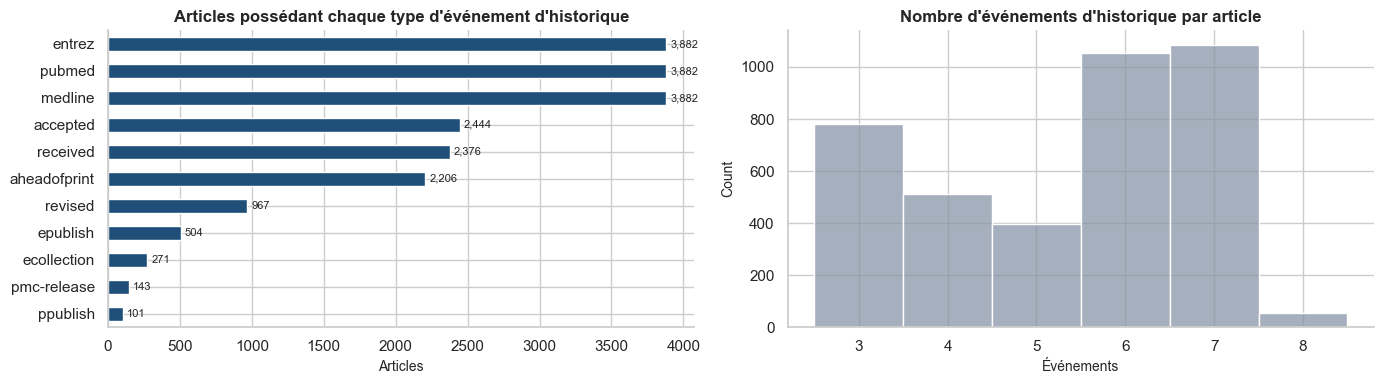

,evenements,articles,couverture_pct
statut,,,
pubmed,3883,3882,99.97
medline,3883,3882,99.97
entrez,3883,3882,99.97
accepted,2444,2444,62.94
received,2376,2376,61.19
aheadofprint,2282,2206,56.81
revised,968,967,24.90
epublish,504,504,12.98
ecollection,271,271,6.98


In [25]:
hist_art = only_ok(historique)
hs = hist_art.groupby("statut").agg(evenements=("art_id", "size"), articles=("art_id", "nunique")).assign(couverture_pct=lambda d: 100 * d.articles / len(art_ok)).sort_values("articles", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
hs.articles.sort_values().plot.barh(color=C["main"], ax=ax[0]); show_bar_labels(ax[0], horizontal=True); ax[0].set(title="Articles possédant chaque type d'événement d'historique", xlabel="Articles", ylabel="")
sns.histplot(art_ok.n_historique, discrete=True, color=C["grey"], ax=ax[1]); ax[1].set(title="Nombre d'événements d'historique par article", xlabel="Événements")
plt.tight_layout(); plt.show()
hs

#Un article a une histoire <history> : il est écrit, envoyé à une revue, accepté, publié en ligne, publié sur papier, indexé dans PubMed... Chacune de ces étapes a une date. Dans le XML, chaque étape est une balise PubMedPubDate, et l’attribut PubStatus dit de quelle étape il s’agit. Un « événement daté » = une étape de la vie de l’article, avec sa date. Exp : <PubMedPubDate PubStatus="received">

## D5. Revues
Une revue est un candidat naturel de **dimension**. On vérifie sa cardinalité, la longueur de sa queue de distribution et la fiabilité de ses attributs (pays, ISSN).

Revues distinctes (titre) : 1,063 | articles par revue : médiane 1, moyenne 3.7, max 157
Revues n'ayant publié qu'UN article dans le corpus : 572 (53.8 %)
Top 10 revues = 17.4 % des articles ; Top 100 = 52.3 %


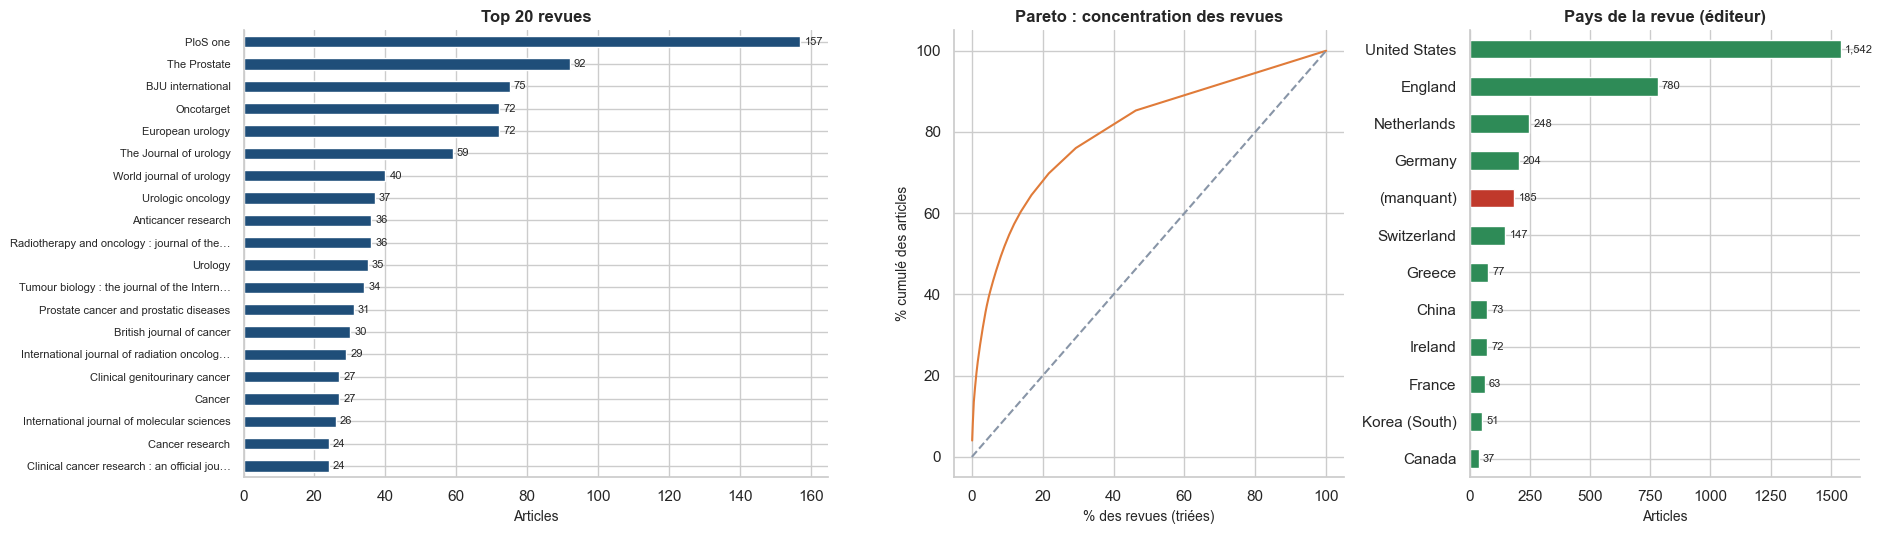

⚠️ « Pays de la revue » = pays de l'ÉDITEUR de la revue, pas pays des auteurs : à ne pas interpréter comme géographie de la recherche.


In [26]:
jr = art_ok.groupby("revue").size().sort_values(ascending=False)
print(f"Revues distinctes (titre) : {len(jr):,} | articles par revue : médiane {int(jr.median())}, moyenne {jr.mean():.1f}, max {jr.max()}")
print(f"Revues n'ayant publié qu'UN article dans le corpus : {(jr == 1).sum():,} ({pct((jr == 1).sum(), len(jr))} %)")
print(f"Top 10 revues = {100*jr.head(10).sum()/jr.sum():.1f} % des articles ; Top 100 = {100*jr.head(100).sum()/jr.sum():.1f} %")

fig, ax = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1.5, 1, 1]})
jr.head(20).sort_values().rename(lambda x: x if len(x) <= 45 else x[:42] + "…").plot.barh(color=C["main"], ax=ax[0]); show_bar_labels(ax[0], horizontal=True); ax[0].set(title="Top 20 revues", xlabel="Articles", ylabel=""); ax[0].tick_params(axis="y", labelsize=8)
cum = jr.cumsum() / jr.sum() * 100
ax[1].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values, color=C["accent"]); ax[1].plot([0, 100], [0, 100], "--", color=C["grey"])
ax[1].set(title="Pareto : concentration des revues", xlabel="% des revues (triées)", ylabel="% cumulé des articles")
pays = art_ok.pays_revue.fillna("(manquant)").value_counts().head(12).sort_values()
pays.plot.barh(color=[C["bad"] if i == "(manquant)" else C["ok"] for i in pays.index], ax=ax[2]); show_bar_labels(ax[2], horizontal=True); ax[2].set(title="Pays de la revue (éditeur)", xlabel="Articles", ylabel="")
plt.tight_layout(); plt.show()
print("⚠️ « Pays de la revue » = pays de l'ÉDITEUR de la revue, pas pays des auteurs : à ne pas interpréter comme géographie de la recherche.")

## D6. Langues et types de publication
Attention aux **variations de casse** et aux **multi-valeurs** (un article peut avoir plusieurs langues et plusieurs types).

Valeurs de langue brutes distinctes : 17 → après normalisation (trim + minuscules) : 15
Langues présentes sous plusieurs graphies de casse : {'eng': ['ENG', 'eng'], 'spa': ['SPA', 'spa']}


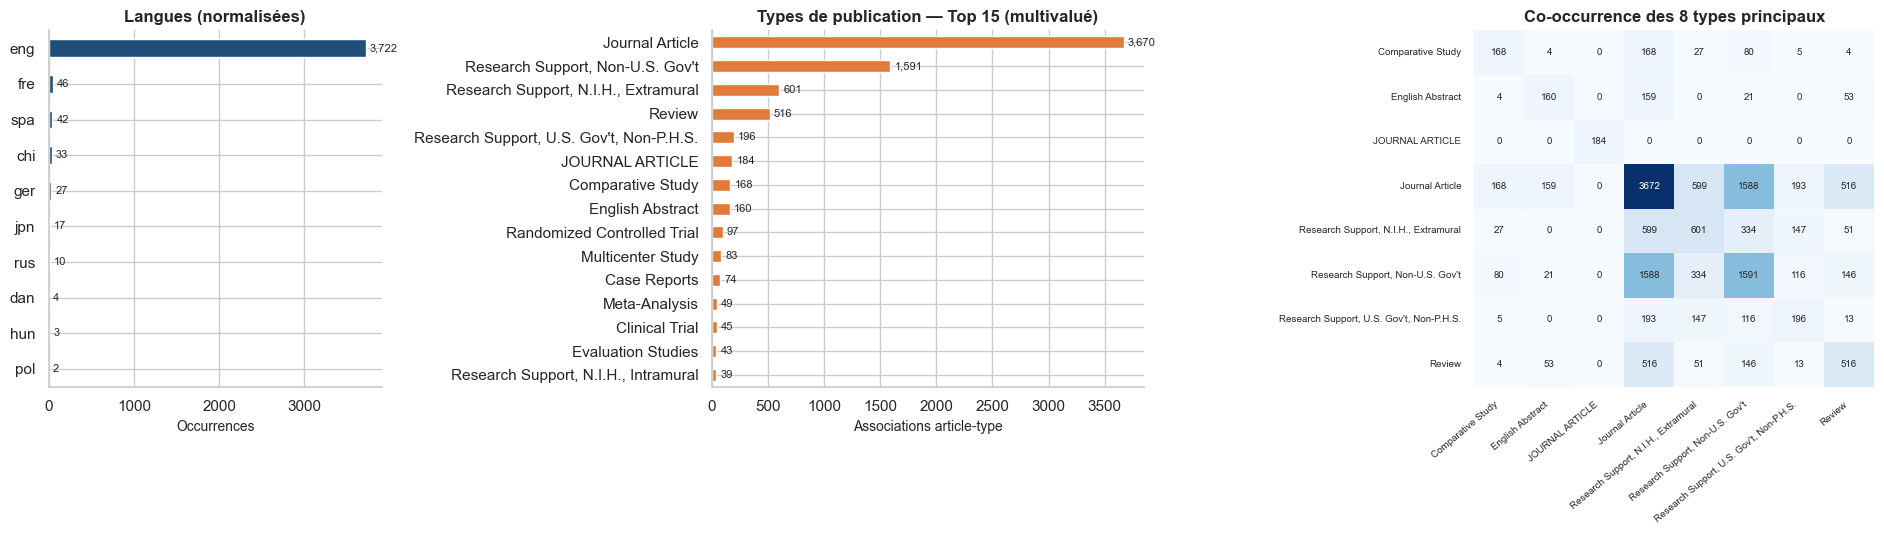

Types de publication par article : {1: 1301, 2: 1646, 3: 661, 4: 220, 5: 43, 6: 12}  → multi-typage = relation N-N (le type n'est PAS un attribut simple de l'article).
Articles multilingues (≥ 2 langues) : 29 (0.7 %)
Part des articles typés « Journal Article » : 94.5 %


In [27]:
lg = only_ok(langues)
lg_raw = lg.langue.value_counts()
lg_norm = lg.langue.str.strip().str.lower().value_counts()
print(f"Valeurs de langue brutes distinctes : {lg_raw.size} → après normalisation (trim + minuscules) : {lg_norm.size}")
casse = lg.groupby(lg.langue.str.lower()).langue.nunique(); casse = casse[casse > 1]
print("Langues présentes sous plusieurs graphies de casse :", {k: sorted(lg[lg.langue.str.lower() == k].langue.unique()) for k in casse.index} or "aucune")

tp = only_ok(types_pub)
top_t = tp.type.value_counts()
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5), gridspec_kw={"width_ratios": [1, 1.3, 1.2]})
lg_norm.head(10).sort_values().plot.barh(color=C["main"], ax=ax[0]); show_bar_labels(ax[0], horizontal=True); ax[0].set(title="Langues (normalisées)", xlabel="Occurrences", ylabel="")
top_t.head(15).sort_values().plot.barh(color=C["accent"], ax=ax[1]); show_bar_labels(ax[1], horizontal=True); ax[1].set(title="Types de publication — Top 15 (multivalué)", xlabel="Associations article-type", ylabel="")
top8 = top_t.head(8).index
M = pd.crosstab(tp[tp.type.isin(top8)].art_id, tp[tp.type.isin(top8)].type); co = M.T.dot(M)
sns.heatmap(co, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[2], annot_kws={"size": 7}); ax[2].set(title="Co-occurrence des 8 types principaux", xlabel="", ylabel="")
plt.setp(ax[2].get_xticklabels(), rotation=40, ha="right", fontsize=7); plt.setp(ax[2].get_yticklabels(), fontsize=7)
plt.tight_layout(); plt.show()
npt = art_ok.n_types_pub.value_counts().sort_index()
print(f"Types de publication par article : {npt.to_dict()}  → multi-typage = relation N-N (le type n'est PAS un attribut simple de l'article).")
print(f"Articles multilingues (≥ 2 langues) : {(art_ok.n_langues >= 2).sum()} ({pct((art_ok.n_langues >= 2).sum(), len(art_ok))} %)")
print(f"Part des articles typés « Journal Article » : {100*tp[tp.type=='Journal Article'].art_id.nunique()/len(art_ok):.1f} %")

## D7. Titres et résumés
Le texte est la colonne la plus riche mais la moins « exploitable » telle quelle : on mesure ici sa **présence, sa longueur, sa structure**.

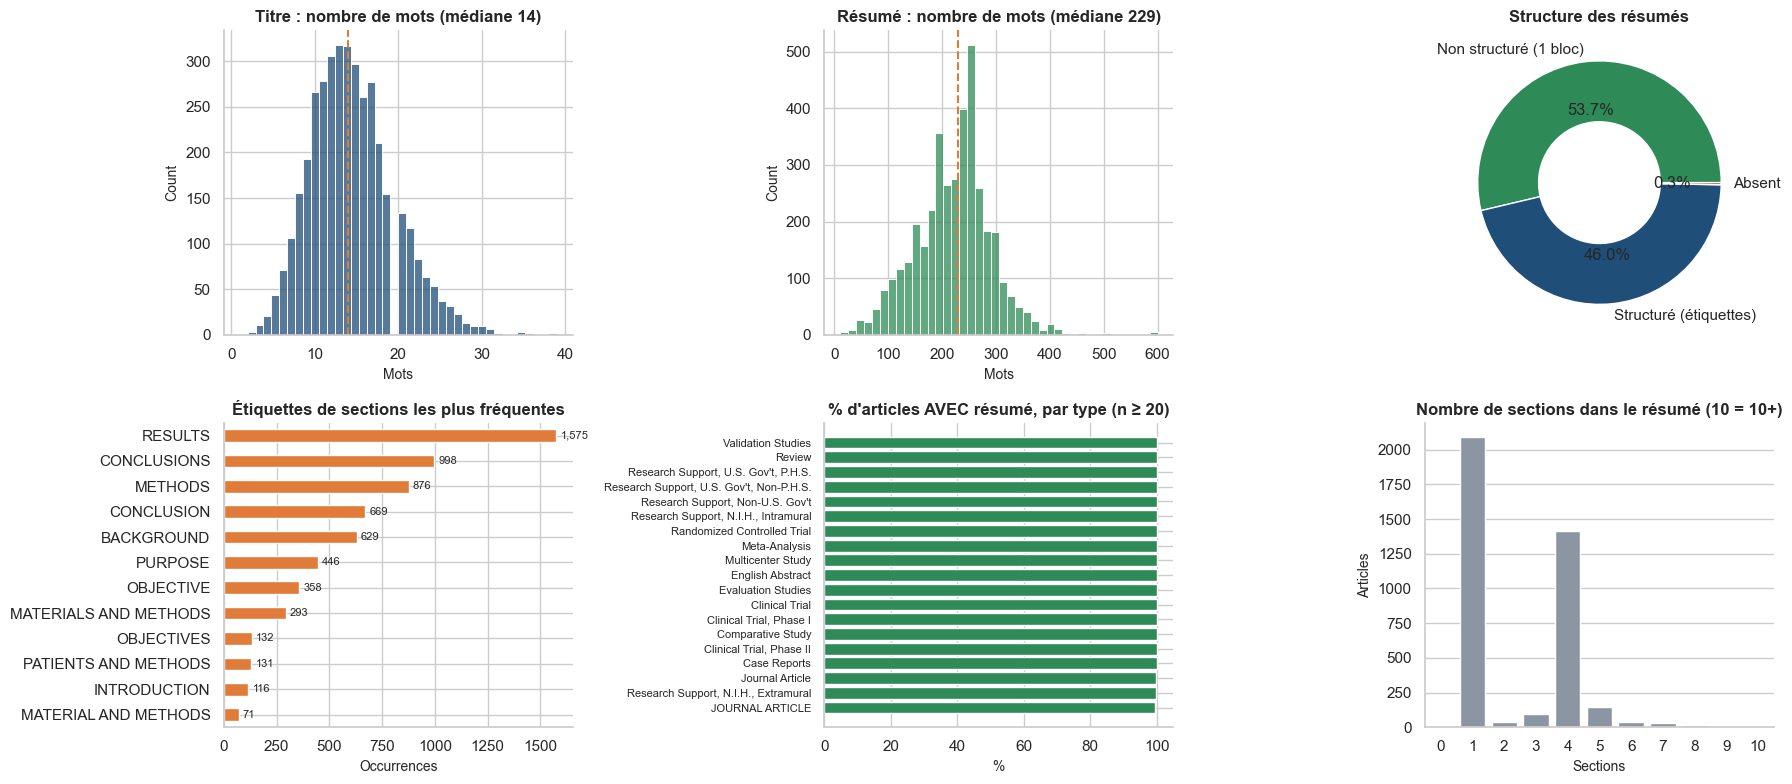

Résumé absent : 11 (0.3 %) · Titre vernaculaire (non anglais) : 112 · mention de copyright : 1461 (37.6 %)
Titres entre crochets (traduits) : 162 · Titres terminés par un point : 97.2 %
→ Types des articles SANS résumé : {'Journal Article': 6, 'Comment': 2, 'Editorial': 2, 'Letter': 2, 'Research Support, N.I.H., Extramural': 1}  (absence très rare → simple NULL, pas de traitement particulier)


In [28]:
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
sns.histplot(art_ok.mots_titre.dropna().clip(upper=60), bins=40, color=C["main"], ax=ax[0, 0]); ax[0, 0].axvline(art_ok.mots_titre.median(), color=C["accent"], ls="--")
ax[0, 0].set(title=f"Titre : nombre de mots (médiane {art_ok.mots_titre.median():.0f})", xlabel="Mots")
sns.histplot(art_ok.mots_resume.dropna().clip(upper=600), bins=40, color=C["ok"], ax=ax[0, 1]); ax[0, 1].axvline(art_ok.mots_resume.median(), color=C["accent"], ls="--")
ax[0, 1].set(title=f"Résumé : nombre de mots (médiane {art_ok.mots_resume.median():.0f})", xlabel="Mots")
struct_res = np.select([art_ok.resume.isna(), art_ok.resume_labels.notna(), art_ok.resume_n_sections >= 1], ["Absent", "Structuré (étiquettes)", "Non structuré (1 bloc)"], "?")
pd.Series(struct_res).value_counts().plot.pie(autopct="%1.1f%%", colors=[C["ok"], C["main"], C["bad"]], wedgeprops=dict(width=.5), ax=ax[0, 2], ylabel="")
ax[0, 2].set_title("Structure des résumés")
lab = art_ok.resume_labels.dropna().str.split("|").explode().str.upper().value_counts().head(12).sort_values()
lab.plot.barh(color=C["accent"], ax=ax[1, 0]); show_bar_labels(ax[1, 0], horizontal=True); ax[1, 0].set(title="Étiquettes de sections les plus fréquentes", xlabel="Occurrences", ylabel="")
tp_ok = only_ok(types_pub).merge(art_ok[["art_id", "fichier", "resume"]], on=["art_id", "fichier"])
ra = tp_ok.groupby("type").agg(n=("art_id", "nunique"), avec_resume=("resume", lambda s: s.notna().mean() * 100)).query("n >= 20").sort_values("avec_resume")
ax[1, 1].barh(ra.index, ra.avec_resume, color=[C["bad"] if v < 50 else C["warn"] if v < 90 else C["ok"] for v in ra.avec_resume]); ax[1, 1].set(title="% d'articles AVEC résumé, par type (n ≥ 20)", xlabel="%", xlim=(0, 105)); ax[1, 1].tick_params(axis="y", labelsize=8)
sns.countplot(x=art_ok.resume_n_sections.clip(upper=10), color=C["grey"], ax=ax[1, 2]); ax[1, 2].set(title="Nombre de sections dans le résumé (10 = 10+)", xlabel="Sections", ylabel="Articles")
plt.tight_layout(); plt.show()
print(f"Résumé absent : {art_ok.resume.isna().sum()} ({pct(art_ok.resume.isna().sum(), len(art_ok))} %) · Titre vernaculaire (non anglais) : {art_ok.titre_vernaculaire.notna().sum()} · mention de copyright : {art_ok.resume_copyright.notna().sum()} ({pct(art_ok.resume_copyright.notna().sum(), len(art_ok))} %)")
print(f"Titres entre crochets (traduits) : {art_ok.titre.str.startswith('[', na=False).sum()} · Titres terminés par un point : {art_ok.titre.str.rstrip().str.endswith('.', na=False).mean()*100:.1f} %")
sans = only_ok(types_pub)[lambda d: d.art_id.isin(art_ok[art_ok.resume.isna()].art_id)].type.value_counts().head(5).to_dict()
print(f"→ Types des articles SANS résumé : {sans}  (absence très rare → simple NULL, pas de traitement particulier)")

## D8. Auteurs
C'est la zone la plus délicate du modèle : **un nom n'est pas un identifiant**. On mesure l'ambiguïté avant de décider de créer une `Dim_Auteur`.

,valeur,% / total
Lignes auteur×article,28711,100.00
Articles sans AuthorList,6,0.00
Auteurs « collectifs » (CollectiveName),71,0.20
Nom de famille manquant (hors collectifs),0,0.00
Prénom manquant,2,0.00
Initiales manquantes,2,0.00
ValidYN = N,11,0.00
Identifiant ORCID présent,53,0.20
Clés (nom|initiales) distinctes,20110,NaN
…dont n'apparaissant qu'une fois,16126,NaN


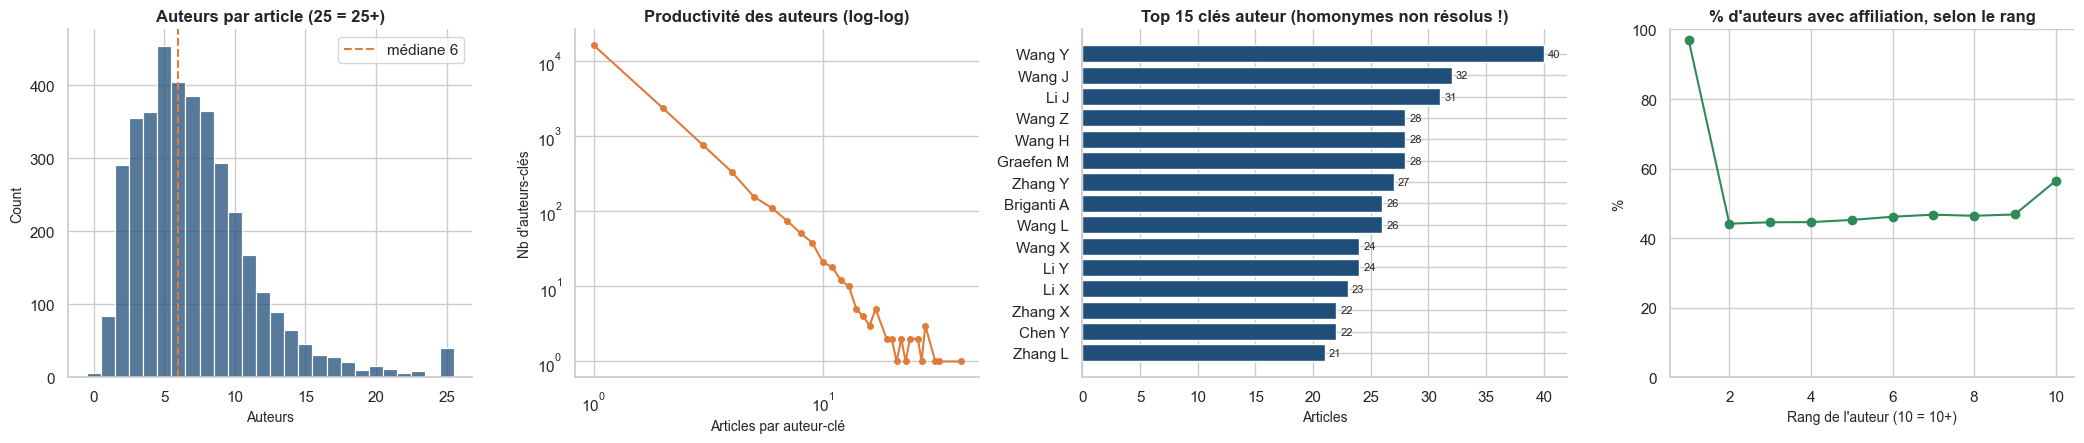

Articles à > 50 auteurs : 10 · maximum : 180 · investigateurs (consortiums) présents dans 17 articles (jusqu'à 803).
→ Conséquence de modélisation : Dim_Auteur ne peut pas reposer sur le nom seul. Piste : clé = (nom, initiales) avec limite documentée, ou ORCID quand il existe (couverture très faible).


In [29]:
au = only_ok(auteurs).copy()
au["cle"] = au.nom.fillna("").str.strip().str.lower() + "|" + au.initiales.fillna("").str.strip().str.upper()
indiv = au[au.collectif.isna()]
prod = indiv.groupby("cle").agg(pubs=("art_id", "nunique"), prenoms=("prenom", lambda s: s.dropna().nunique()), nom=("nom", "first"), initiales=("initiales", "first")).sort_values("pubs", ascending=False)

mt = pd.Series({
    "Lignes auteur×article": len(au), "Articles sans AuthorList": int((art_ok.n_auteurs == 0).sum()),
    "Auteurs « collectifs » (CollectiveName)": int(au.collectif.notna().sum()), "Nom de famille manquant (hors collectifs)": int(indiv.nom.isna().sum()),
    "Prénom manquant": int(indiv.prenom.isna().sum()), "Initiales manquantes": int(indiv.initiales.isna().sum()), "ValidYN = N": int((au.valid_yn == "N").sum()),
    "Identifiant ORCID présent": int(au.orcid.notna().sum()), "Clés (nom|initiales) distinctes": int(prod.shape[0]),
    "…dont n'apparaissant qu'une fois": int((prod.pubs == 1).sum()), "Clés associées à ≥ 2 prénoms différents (homonymes potentiels)": int((prod.prenoms >= 2).sum()),
    "Production maximale d'une clé (articles)": int(prod.pubs.max()),
}).to_frame("valeur"); mt["% / total"] = [pct(v, len(au)) if i < 8 else None for i, v in enumerate(mt.valeur)]
display(mt)

fig, ax = plt.subplots(1, 4, figsize=(21, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.2, 1]})
sns.histplot(art_ok.n_auteurs.clip(upper=25), discrete=True, color=C["main"], ax=ax[0]); ax[0].axvline(art_ok.n_auteurs.median(), color=C["accent"], ls="--", label=f"médiane {art_ok.n_auteurs.median():.0f}")
ax[0].set(title="Auteurs par article (25 = 25+)", xlabel="Auteurs"); ax[0].legend()
dist_prod = prod.pubs.value_counts().sort_index()
ax[1].loglog(dist_prod.index, dist_prod.values, "o-", color=C["accent"], ms=4); ax[1].set(title="Productivité des auteurs (log-log)", xlabel="Articles par auteur-clé", ylabel="Nb d'auteurs-clés")
top_au = prod.head(15).iloc[::-1]
ax[2].barh(top_au.nom.fillna("?") + " " + top_au.initiales.fillna(""), top_au.pubs, color=C["main"]); show_bar_labels(ax[2], horizontal=True); ax[2].set(title="Top 15 clés auteur (homonymes non résolus !)", xlabel="Articles")
rk = au.assign(rang_c=au.rang.clip(upper=10)).groupby("rang_c").n_aff.apply(lambda s: 100 * (s > 0).mean())
ax[3].plot(rk.index, rk.values, "o-", color=C["ok"]); ax[3].set(title="% d'auteurs avec affiliation, selon le rang", xlabel="Rang de l'auteur (10 = 10+)", ylabel="%", ylim=(0, 100))
plt.tight_layout(); plt.show()
print(f"Articles à > 50 auteurs : {(art_ok.n_auteurs > 50).sum()} · maximum : {art_ok.n_auteurs.max()} · investigateurs (consortiums) présents dans {(art_ok.n_investigateurs > 0).sum()} articles (jusqu'à {art_ok.n_investigateurs.max()}).")
print("→ Conséquence de modélisation : Dim_Auteur ne peut pas reposer sur le nom seul. Piste : clé = (nom, initiales) avec limite documentée, ou ORCID quand il existe (couverture très faible).")

#Le rang correspond à la position de l'auteur dans la liste des auteurs d'un article.
#Tu construis la clé avec : Le nom de famille (nom) + Les initiales (initiales).

## D9. Affiliations — faisabilité d'une dimension géographique
Les affiliations sont du **texte libre**. Test réaliste : peut-on en extraire un **pays** de manière fiable par règles simples ?

Affiliations : 16,700 lignes · 9,920 textes distincts (taux de réutilisation = 1.68 lignes par texte) · 3,780 articles couverts (97.3 %) · 15,521 auteurs sur 28,711 ont ≥ 1 affiliation (54.1 %)
Pays extrait par règles simples : 75.7 % des affiliations (50 pays distincts)


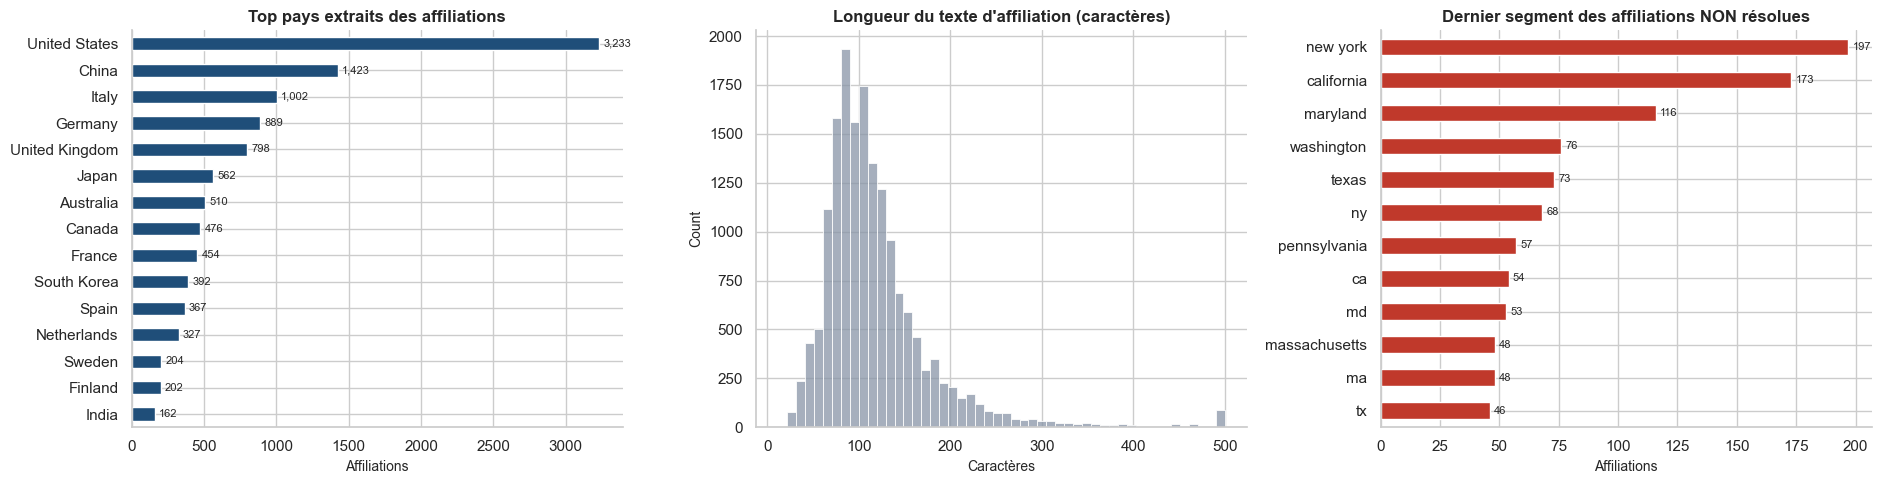

Affiliations contenant une adresse e-mail : 13.3 % · plusieurs institutions séparées par ';' : 9.4 %
→ Dimension géographique FAISABLE mais avec règles d'extraction à documenter ; l'institution (texte) est trop bruitée pour une dimension fiable sans normalisation lourde.


In [30]:
af = only_ok(affils).copy()
print(f"Affiliations : {len(af):,} lignes · {af.affiliation.nunique():,} textes distincts (taux de réutilisation = {len(af)/af.affiliation.nunique():.2f} lignes par texte) · "
      f"{af.art_id.nunique():,} articles couverts ({pct(af.art_id.nunique(), len(art_ok))} %) · {int((au.n_aff > 0).sum()):,} auteurs sur {len(au):,} ont ≥ 1 affiliation ({pct((au.n_aff>0).sum(), len(au))} %)")

COUNTRIES = {"United States": ["usa", "u.s.a", "u.s.a.", "us", "united states", "united states of america", "u.s."], "United Kingdom": ["uk", "u.k.", "united kingdom", "england", "scotland", "wales", "northern ireland", "great britain"],
 "China": ["china", "p.r. china", "pr china", "people's republic of china", "p. r. china", "hong kong", "taiwan", "p.r.china"], "Germany": ["germany", "deutschland"], "France": ["france"], "Italy": ["italy", "italia"], "Spain": ["spain", "españa"],
 "Japan": ["japan"], "Canada": ["canada"], "Australia": ["australia"], "Netherlands": ["the netherlands", "netherlands", "holland"], "Switzerland": ["switzerland"], "Sweden": ["sweden"], "Denmark": ["denmark"], "Norway": ["norway"],
 "Finland": ["finland"], "Belgium": ["belgium"], "Austria": ["austria"], "South Korea": ["korea", "south korea", "republic of korea", "republic of  korea"], "India": ["india"], "Brazil": ["brazil", "brasil"], "Turkey": ["turkey", "türkiye"],
 "Israel": ["israel"], "Greece": ["greece"], "Poland": ["poland"], "Portugal": ["portugal"], "Ireland": ["ireland"], "Iran": ["iran", "islamic republic of iran"], "Egypt": ["egypt"], "Mexico": ["mexico"], "Russia": ["russia", "russian federation"],
 "Singapore": ["singapore"], "Saudi Arabia": ["saudi arabia"], "Czech Republic": ["czech republic", "czechia"], "Hungary": ["hungary"], "Argentina": ["argentina"], "Chile": ["chile"], "South Africa": ["south africa"], "New Zealand": ["new zealand"],
 "Thailand": ["thailand"], "Pakistan": ["pakistan"], "Tunisia": ["tunisia"], "Morocco": ["morocco"], "Lebanon": ["lebanon"], "Malaysia": ["malaysia"], "Romania": ["romania"], "Serbia": ["serbia"], "Croatia": ["croatia"], "Slovenia": ["slovenia"], "Ukraine": ["ukraine"]}
ALIAS = {a: c for c, al in COUNTRIES.items() for a in al}
US_ZIP = re.compile(r"\b[A-Z]{2}\s\d{5}(-\d{4})?\b")

def extract_country(txt):
    if not isinstance(txt, str): return None
    t = re.sub(r"(Electronic address|E-mail|Email)\s*:.*$", "", txt, flags=re.I).strip().rstrip(".; ")
    last = t.split(",")[-1].strip().lower().rstrip(".")
    last = re.sub(r"^\W+|\W+$", "", last)
    if last in ALIAS: return ALIAS[last]
    for a in sorted(ALIAS, key=len, reverse=True):
        if len(a) > 3 and t.lower().endswith(a): return ALIAS[a]
    if US_ZIP.search(t): return "United States"
    return None

af["pays_extrait"] = af.affiliation.map(extract_country)
cov_c = af.pays_extrait.notna().mean() * 100
print(f"Pays extrait par règles simples : {cov_c:.1f} % des affiliations ({af.pays_extrait.nunique()} pays distincts)")
unres = af[af.pays_extrait.isna()].affiliation.str.rstrip(". ").str.split(",").str[-1].str.strip().str.lower().value_counts().head(12)

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
af.pays_extrait.value_counts().head(15).sort_values().plot.barh(color=C["main"], ax=ax[0]); show_bar_labels(ax[0], horizontal=True); ax[0].set(title="Top pays extraits des affiliations", xlabel="Affiliations", ylabel="")
af.affiliation.str.len().clip(upper=500).pipe(lambda s: sns.histplot(s, bins=50, color=C["grey"], ax=ax[1])); ax[1].set(title="Longueur du texte d'affiliation (caractères)", xlabel="Caractères")
unres.sort_values().plot.barh(color=C["bad"], ax=ax[2]); show_bar_labels(ax[2], horizontal=True); ax[2].set(title="Dernier segment des affiliations NON résolues", xlabel="Affiliations", ylabel="")
plt.tight_layout(); plt.show()
print(f"Affiliations contenant une adresse e-mail : {af.affiliation.str.contains('@').mean()*100:.1f} % · plusieurs institutions séparées par ';' : {af.affiliation.str.contains(';').mean()*100:.1f} %")
print("→ Dimension géographique FAISABLE mais avec règles d'extraction à documenter ; l'institution (texte) est trop bruitée pour une dimension fiable sans normalisation lourde.")

## D10. Descripteurs MeSH et qualificatifs
Le MeSH est le **vocabulaire contrôlé** de la NLM : c'est l'axe thématique le plus propre du corpus (codes `UI` stables).

Associations article×descripteur : 35,778 · articles couverts : 2,608 (67.2 %) · descripteurs distincts : 3,924 (codes UI : 3,924)
Cohérence nom↔UI : noms avec >1 UI = 0 · UI avec >1 nom = 0  → relation 1-1 propre
Descripteurs « majeurs » (MajorTopicYN=Y) : 5.3 % des associations · descripteurs géographiques : 362 · 23,216 qualificatifs attachés à 14,855 descripteurs (41.5 % des associations ont ≥ 1 qualificatif)
Descripteurs apparaissant dans un seul article : 1,911 (48.7 %) · Top 20 couvrent 38.0 % des associations


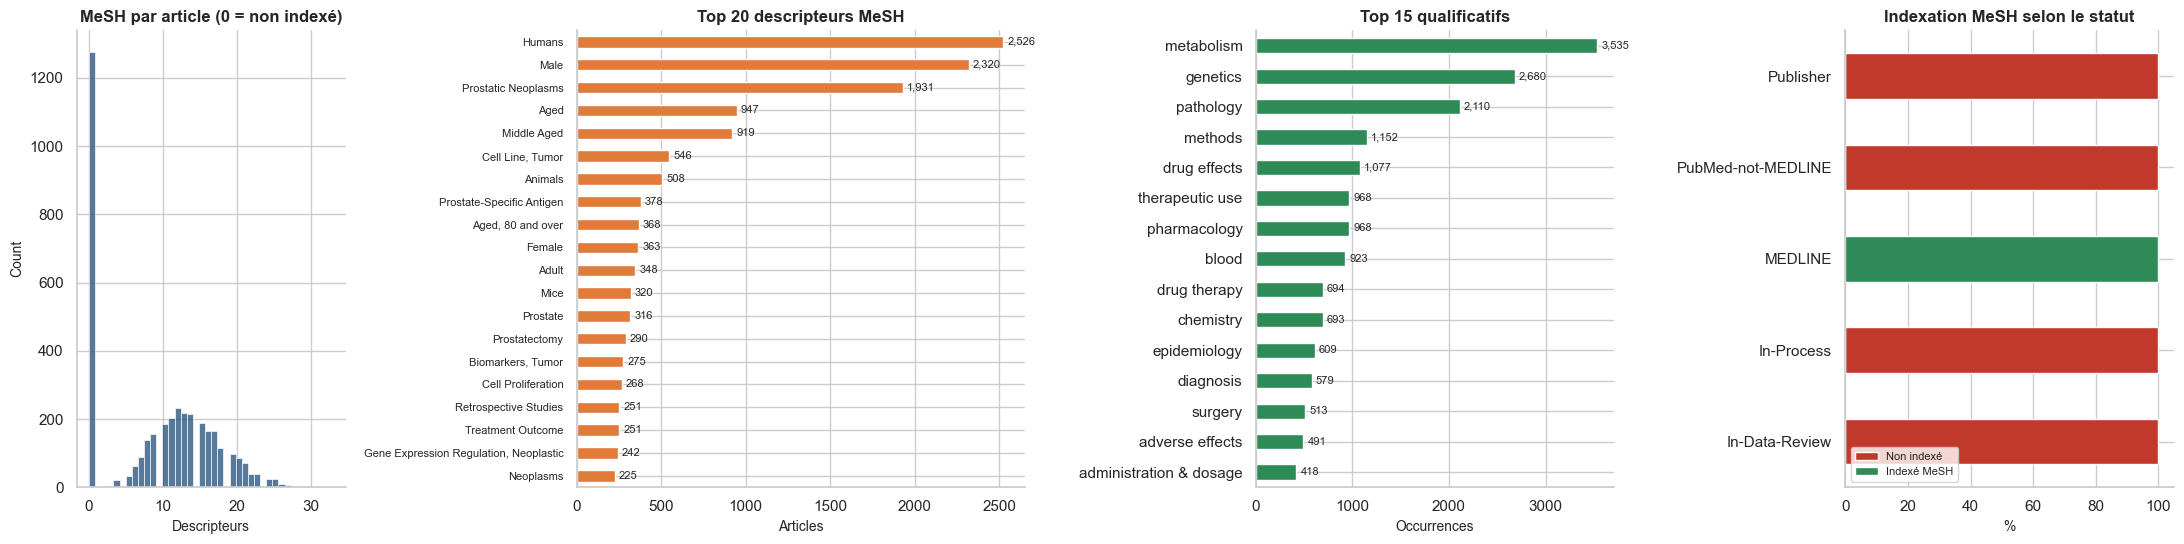

In [31]:
ms = only_ok(mesh); mq = only_ok(mesh_qual)
n_desc = ms.descripteur.nunique(); ui_per_name = ms.groupby("descripteur").ui.nunique(); name_per_ui = ms.groupby("ui").descripteur.nunique()
print(f"Associations article×descripteur : {len(ms):,} · articles couverts : {ms.art_id.nunique():,} ({pct(ms.art_id.nunique(), len(art_ok))} %) · descripteurs distincts : {n_desc:,} (codes UI : {ms.ui.nunique():,})")
print(f"Cohérence nom↔UI : noms avec >1 UI = {(ui_per_name>1).sum()} · UI avec >1 nom = {(name_per_ui>1).sum()}  → {'relation 1-1 propre' if (ui_per_name>1).sum()==0 and (name_per_ui>1).sum()==0 else 'à nettoyer'}")
print(f"Descripteurs « majeurs » (MajorTopicYN=Y) : {pct((ms.majeur=='Y').sum(), len(ms))} % des associations · descripteurs géographiques : {(ms.type=='Geographic').sum()} · {len(mq):,} qualificatifs attachés à {ms.n_qual.gt(0).sum():,} descripteurs ({pct(ms.n_qual.gt(0).sum(), len(ms))} % des associations ont ≥ 1 qualificatif)")
freq = ms.groupby("descripteur").art_id.nunique().sort_values(ascending=False)
print(f"Descripteurs apparaissant dans un seul article : {(freq==1).sum():,} ({pct((freq==1).sum(), len(freq))} %) · Top 20 couvrent {100*freq.head(20).sum()/len(ms):.1f} % des associations")

fig, ax = plt.subplots(1, 4, figsize=(22, 5.6), gridspec_kw={"width_ratios": [.9, 1.5, 1.2, 1.1]})
sns.histplot(art_ok.n_mesh.clip(upper=40), bins=40, color=C["main"], ax=ax[0]); ax[0].set(title="MeSH par article (0 = non indexé)", xlabel="Descripteurs")
freq.head(20).sort_values().rename(lambda x: x if len(x) <= 38 else x[:35] + "…").plot.barh(color=C["accent"], ax=ax[1]); show_bar_labels(ax[1], horizontal=True); ax[1].set(title="Top 20 descripteurs MeSH", xlabel="Articles", ylabel=""); ax[1].tick_params(axis="y", labelsize=8)
mq.qualificatif.value_counts().head(15).sort_values().plot.barh(color=C["ok"], ax=ax[2]); show_bar_labels(ax[2], horizontal=True); ax[2].set(title="Top 15 qualificatifs", xlabel="Occurrences", ylabel="")
ctab = pd.crosstab(art_ok.statut, art_ok.n_mesh > 0, normalize="index") * 100
ctab.rename(columns={True: "Indexé MeSH", False: "Non indexé"}).plot.barh(stacked=True, color=[C["bad"], C["ok"]], ax=ax[3]); ax[3].set(title="Indexation MeSH selon le statut", xlabel="%", ylabel=""); ax[3].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

#Descripteur (Descriptor) : indique le sujet principal ou le thème étudié. => cancer du foie
#Qualificatif (Qualifier) : précise sous quel angle ce sujet est étudié. => chirugie

#Article indexé MeSH : il possède des descripteurs MeSH qui décrivent ses sujets.
#Article non indexé MeSH : il ne possède pas encore ces descripteurs dans son enregistrement.

## D11. Mots-clés (`Keyword`) — vocabulaire **libre**
Contrairement au MeSH, les mots-clés sont saisis par les auteurs : on s'attend à du bruit (casse, pluriels, séparateurs, synonymes).

Associations : 12,360 · articles couverts : 2,069 (53.3 %) · propriétaires : {'NOTNLM': 12360} · MajorTopicYN : {'N': 12360}
Mots-clés distincts : brut = 7,164 → après trim+minuscule = 6,434 (gain de normalisation : 10.2 %)
Mots-clés contenant un séparateur (';' ou ',') = possibles listes collées : 110 · mots-clés d'un seul mot : 43.3 % · apparaissant 1 seule fois : 79.8 %
Mots-clés identiques à un descripteur MeSH du même article : 5.5 % → les deux vocabulaires sont complémentaires


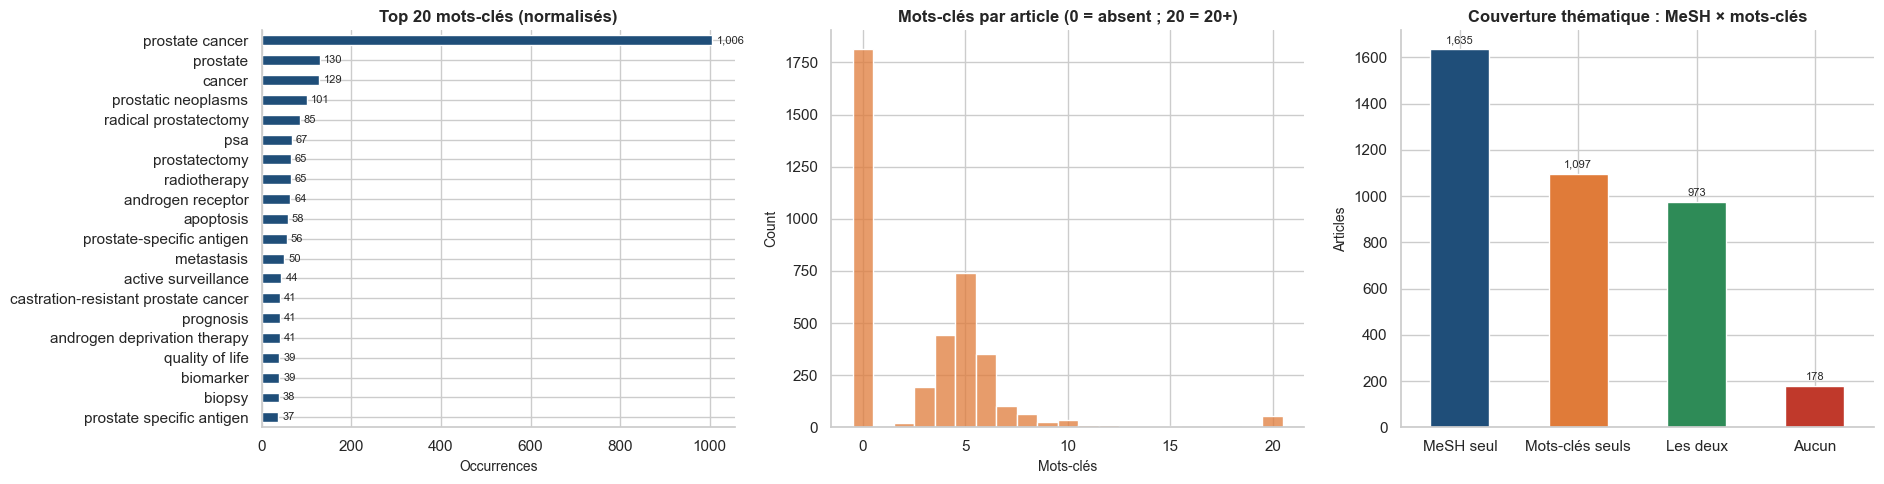

In [32]:
kw = only_ok(mots_cles).copy(); kw["mc_norm"] = kw.mot_cle.str.strip().str.lower()
print(f"Associations : {len(kw):,} · articles couverts : {kw.art_id.nunique():,} ({pct(kw.art_id.nunique(), len(art_ok))} %) · propriétaires : {kw.owner.value_counts().to_dict()} · MajorTopicYN : {kw.majeur.value_counts().to_dict()}")
print(f"Mots-clés distincts : brut = {kw.mot_cle.nunique():,} → après trim+minuscule = {kw.mc_norm.nunique():,} (gain de normalisation : {100*(1-kw.mc_norm.nunique()/kw.mot_cle.nunique()):.1f} %)")
print(f"Mots-clés contenant un séparateur (';' ou ',') = possibles listes collées : {kw.mot_cle.str.contains('[;,]').sum()} · mots-clés d'un seul mot : {(kw.mot_cle.str.split().str.len()==1).mean()*100:.1f} % · apparaissant 1 seule fois : {(kw.mc_norm.value_counts()==1).mean()*100:.1f} %")
# recouvrement MeSH ↔ mots-clés dans un même article
ms_set = ms.assign(m=ms.descripteur.str.lower()).groupby("art_id").m.apply(set)
kw["dans_mesh"] = [m in ms_set.get(a, set()) for a, m in zip(kw.art_id, kw.mc_norm)]
print(f"Mots-clés identiques à un descripteur MeSH du même article : {kw.dans_mesh.mean()*100:.1f} % → les deux vocabulaires sont {'redondants' if kw.dans_mesh.mean() > .5 else 'complémentaires'}")
both = pd.Series({"MeSH seul": ((art_ok.n_mesh > 0) & (art_ok.n_mots_cles == 0)).sum(), "Mots-clés seuls": ((art_ok.n_mesh == 0) & (art_ok.n_mots_cles > 0)).sum(),
                  "Les deux": ((art_ok.n_mesh > 0) & (art_ok.n_mots_cles > 0)).sum(), "Aucun": ((art_ok.n_mesh == 0) & (art_ok.n_mots_cles == 0)).sum()})
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
kw.mc_norm.value_counts().head(20).sort_values().plot.barh(color=C["main"], ax=ax[0]); show_bar_labels(ax[0], horizontal=True); ax[0].set(title="Top 20 mots-clés (normalisés)", xlabel="Occurrences", ylabel="")
sns.histplot(art_ok.n_mots_cles.clip(upper=20), discrete=True, color=C["accent"], ax=ax[1]); ax[1].set(title="Mots-clés par article (0 = absent ; 20 = 20+)", xlabel="Mots-clés")
both.plot.bar(color=[C["main"], C["accent"], C["ok"], C["bad"]], ax=ax[2], rot=0); show_bar_labels(ax[2]); ax[2].set(title="Couverture thématique : MeSH × mots-clés", ylabel="Articles")
plt.tight_layout(); plt.show()

## D12. Substances chimiques, financements, références, banques de données
Tables secondaires : on mesure leur couverture et leur bruit pour savoir si elles méritent une dimension ou doivent être écartées.

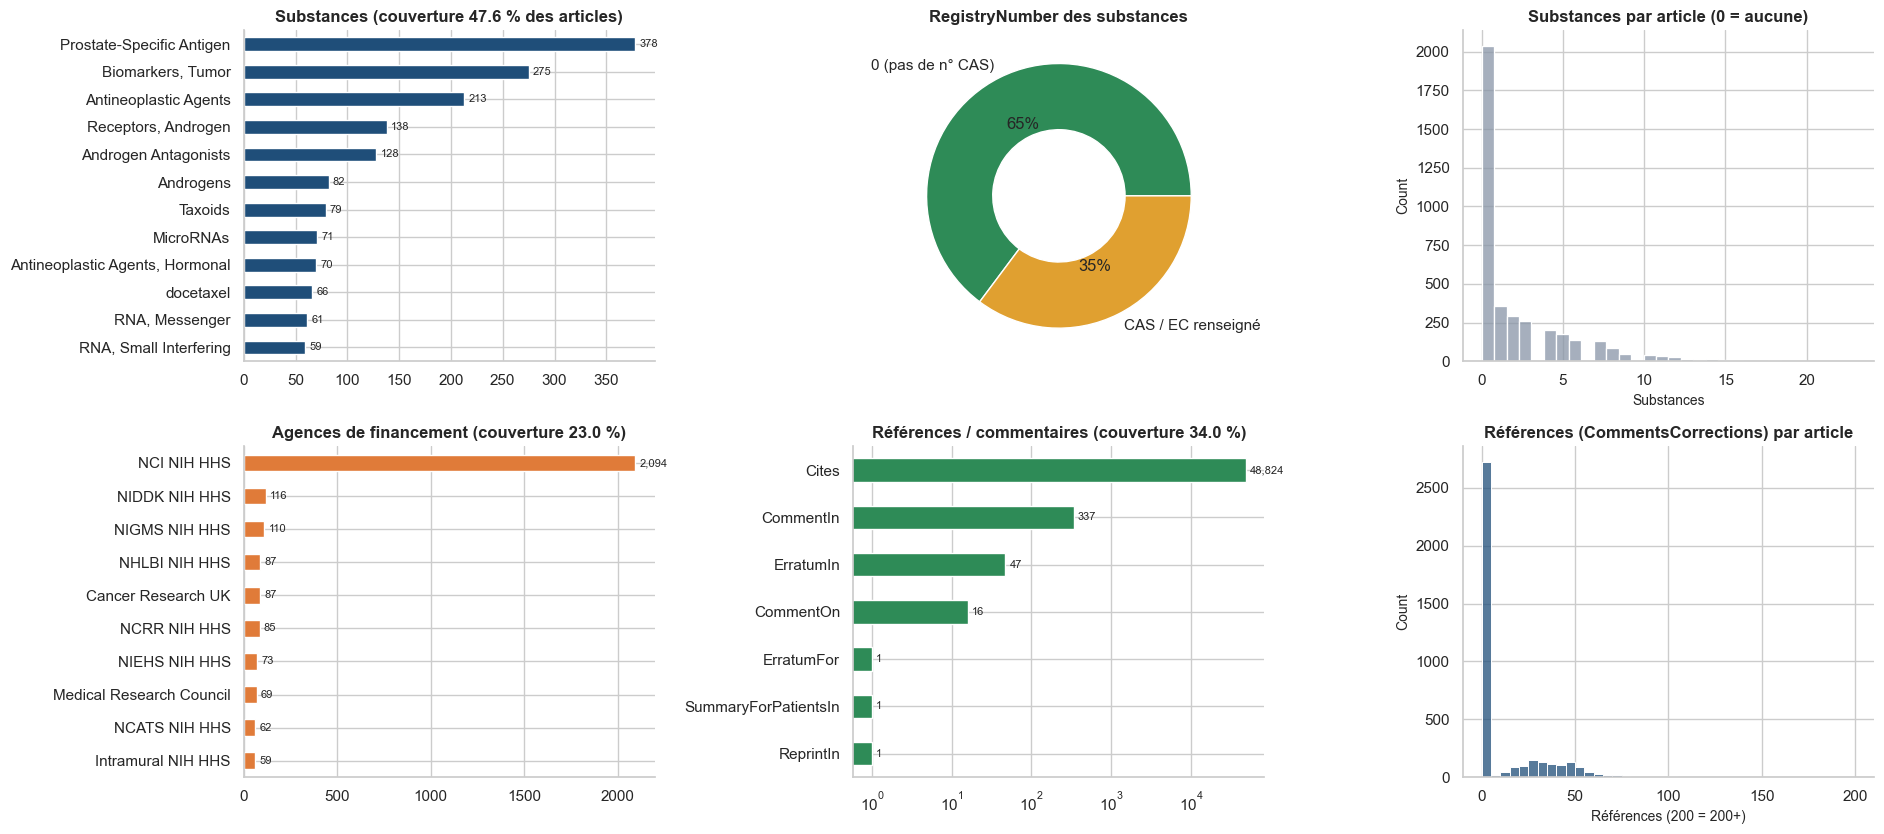

Pays des financeurs : {'United States': 3048, 'United Kingdom': 212, 'Canada': 56, 'Austria': 5, 'International': 2} · GrantID manquant : 3.5 % · Banques de données (GenBank…) : 60 articles
Références 'Cites' = 99.2 % des CommentsCorrections → surtout un graphe de citations (PMID cités), exploitable en analyse de réseau mais hors périmètre minimal.


In [33]:
ch = only_ok(chimie); gr = only_ok(grants); cm = only_ok(commentaires); bk = only_ok(banques)
fig, ax = plt.subplots(2, 3, figsize=(19, 8.5))
ch.substance.value_counts().head(12).sort_values().plot.barh(color=C["main"], ax=ax[0, 0]); show_bar_labels(ax[0, 0], horizontal=True); ax[0, 0].set(title=f"Substances (couverture {pct(ch.art_id.nunique(), len(art_ok))} % des articles)", xlabel="", ylabel="")
rg = ch.registre.fillna("(manquant)").map(lambda x: "0 (pas de n° CAS)" if x == "0" else "(manquant)" if x == "(manquant)" else "CAS / EC renseigné").value_counts()
rg.plot.pie(autopct="%1.0f%%", colors=[C["ok"], C["warn"], C["bad"]][:len(rg)], wedgeprops=dict(width=.5), ax=ax[0, 1], ylabel=""); ax[0, 1].set_title("RegistryNumber des substances")
sns.histplot(art_ok.n_chimie.clip(upper=30), bins=30, color=C["grey"], ax=ax[0, 2]); ax[0, 2].set(title="Substances par article (0 = aucune)", xlabel="Substances")
gr.agence.value_counts().head(10).sort_values().rename(lambda x: str(x)[:40]).plot.barh(color=C["accent"], ax=ax[1, 0]); show_bar_labels(ax[1, 0], horizontal=True); ax[1, 0].set(title=f"Agences de financement (couverture {pct(gr.art_id.nunique(), len(art_ok))} %)", xlabel="", ylabel="")
cm.type_ref.value_counts().sort_values().plot.barh(color=C["ok"], ax=ax[1, 1]); show_bar_labels(ax[1, 1], horizontal=True); ax[1, 1].set(title=f"Références / commentaires (couverture {pct(cm.art_id.nunique(), len(art_ok))} %)", xlabel="", ylabel="")
ax[1, 1].set_xscale("log")
sns.histplot(art_ok.n_commentaires.clip(upper=200), bins=40, color=C["main"], ax=ax[1, 2]); ax[1, 2].set(title="Références (CommentsCorrections) par article", xlabel="Références (200 = 200+)")
plt.tight_layout(); plt.show()
print(f"Pays des financeurs : {gr.pays.value_counts().head(5).to_dict()} · GrantID manquant : {pct(gr.grant_id.isna().sum(), len(gr))} % · Banques de données (GenBank…) : {bk.art_id.nunique()} articles")
print(f"Références 'Cites' = {pct((cm.type_ref=='Cites').sum(), len(cm))} % des CommentsCorrections → surtout un graphe de citations (PMID cités), exploitable en analyse de réseau mais hors périmètre minimal.")

#Substance identifie les substances chimiques ou biologiques mentionnées dans l'article. ecxp: insuline, glucose, chlorure de sodium

---
# PARTIE E — Analyse des valeurs manquantes
Trois questions : **combien** manque-t-il ? **où** (quels champs, quels articles) ? **pourquoi** (absence *structurelle* liée au statut/type, ou *aléatoire*) ?
La réponse conditionne le traitement : on ne remplace pas de la même façon une valeur *inapplicable* et une valeur *perdue*.

## E1. Définition opérationnelle de « manquant » par champ
Un champ est manquant s'il est `NULL`/vide ; pour les champs **multivalués**, s'il compte **0 élément**.

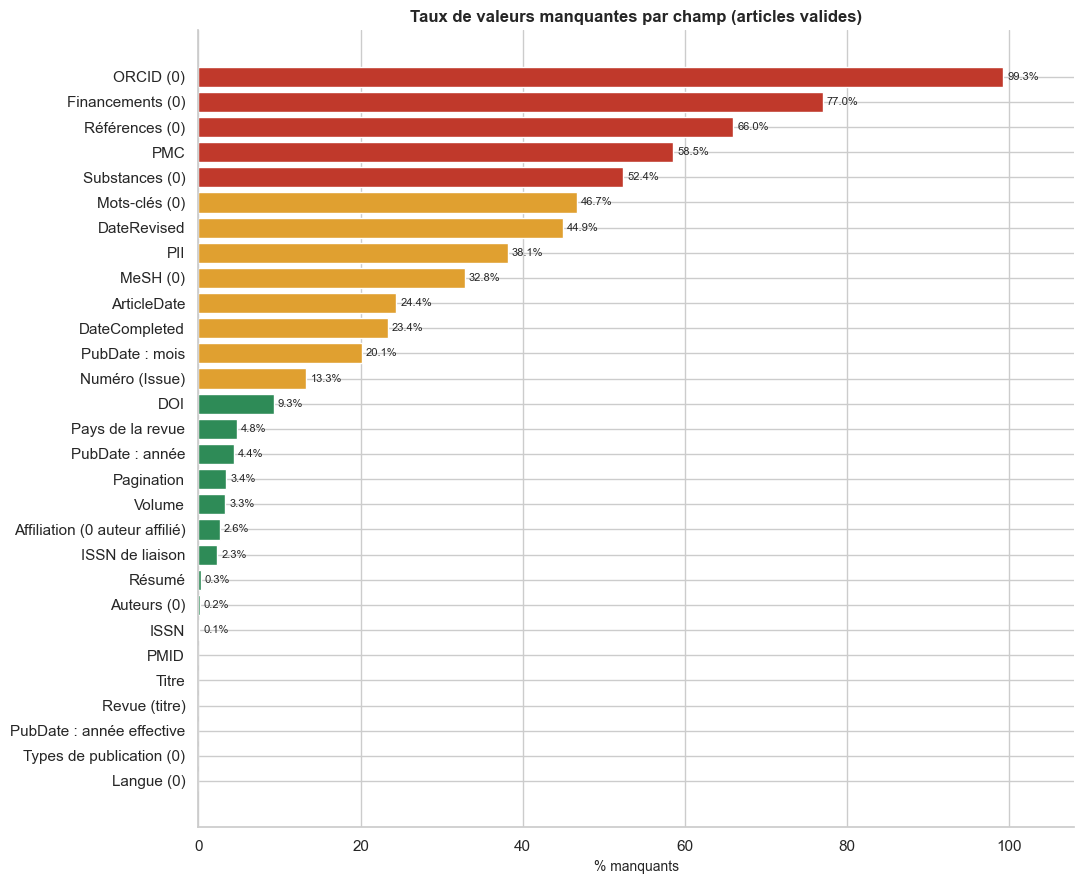

Champs sans aucune valeur manquante : 6 · < 10 % : 10 · 10–50 % : 8 · ≥ 50 % : 5


In [34]:
M = pd.DataFrame({
    "PMID": art_ok.pmid.isna(), "Titre": art_ok.titre.isna() | (art_ok.titre.fillna("x").str.strip() == ""), "Résumé": art_ok.resume.isna(),
    "Auteurs (0)": art_ok.n_auteurs == 0, "Affiliation (0 auteur affilié)": art_ok.n_auteurs_avec_aff == 0, "ORCID (0)": art_ok.n_orcid == 0,
    "Revue (titre)": art_ok.revue.isna(), "ISSN": art_ok.issn.isna(), "ISSN de liaison": art_ok.issn_liaison.isna(), "Pays de la revue": art_ok.pays_revue.isna(),
    "Volume": art_ok.volume.isna(), "Numéro (Issue)": art_ok.numero.isna(), "Pagination": art_ok.pagination.isna() | (art_ok.pagination.fillna("x").str.strip() == ""),
    "PubDate : année": art_ok.pub_annee.isna(), "PubDate : année effective": art_ok.pub_annee_eff.isna(), "PubDate : mois": art_ok.pub_mois.isna() & art_ok.pub_medline_date.isna(),
    "DateCompleted": art_ok.complete_dt.isna(), "DateRevised": art_ok.revise_dt.isna(), "ArticleDate": art_ok.art_dt.isna(),
    "DOI": art_ok.doi.isna(), "PMC": art_ok.pmc.isna(), "PII": art_ok.pii.isna(),
    "Mots-clés (0)": art_ok.n_mots_cles == 0, "MeSH (0)": art_ok.n_mesh == 0, "Substances (0)": art_ok.n_chimie == 0, "Financements (0)": art_ok.n_grants == 0,
    "Références (0)": art_ok.n_commentaires == 0, "Types de publication (0)": art_ok.n_types_pub == 0, "Langue (0)": art_ok.n_langues == 0,
})
miss = (M.mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(miss.index[::-1], miss.values[::-1], color=[C["bad"] if v >= 50 else C["warn"] if v >= 10 else C["ok"] if v > 0 else C["grey"] for v in miss.values[::-1]])
show_bar_labels(ax, "{:.1f}%", horizontal=True); ax.set(title="Taux de valeurs manquantes par champ (articles valides)", xlabel="% manquants", xlim=(0, 108))
plt.tight_layout(); plt.show()
export(miss.rename("manquants_pct").to_frame(), "E_manquants_par_champ")
print(f"Champs sans aucune valeur manquante : {int((miss == 0).sum())} · < 10 % : {int(((miss > 0) & (miss < 10)).sum())} · 10–50 % : {int(((miss >= 10) & (miss < 50)).sum())} · ≥ 50 % : {int((miss >= 50).sum())}")

## E2. Où manque-t-il ? Carte des manquants (échantillon d'articles) et corrélations
*Gauche :* chaque ligne = un article, chaque colonne = un champ (noir = manquant). Les **blocs** révèlent des absences liées entre elles.
*Droite :* corrélation (φ) entre indicateurs de manquants — deux champs absents **ensemble** ont probablement la même cause.

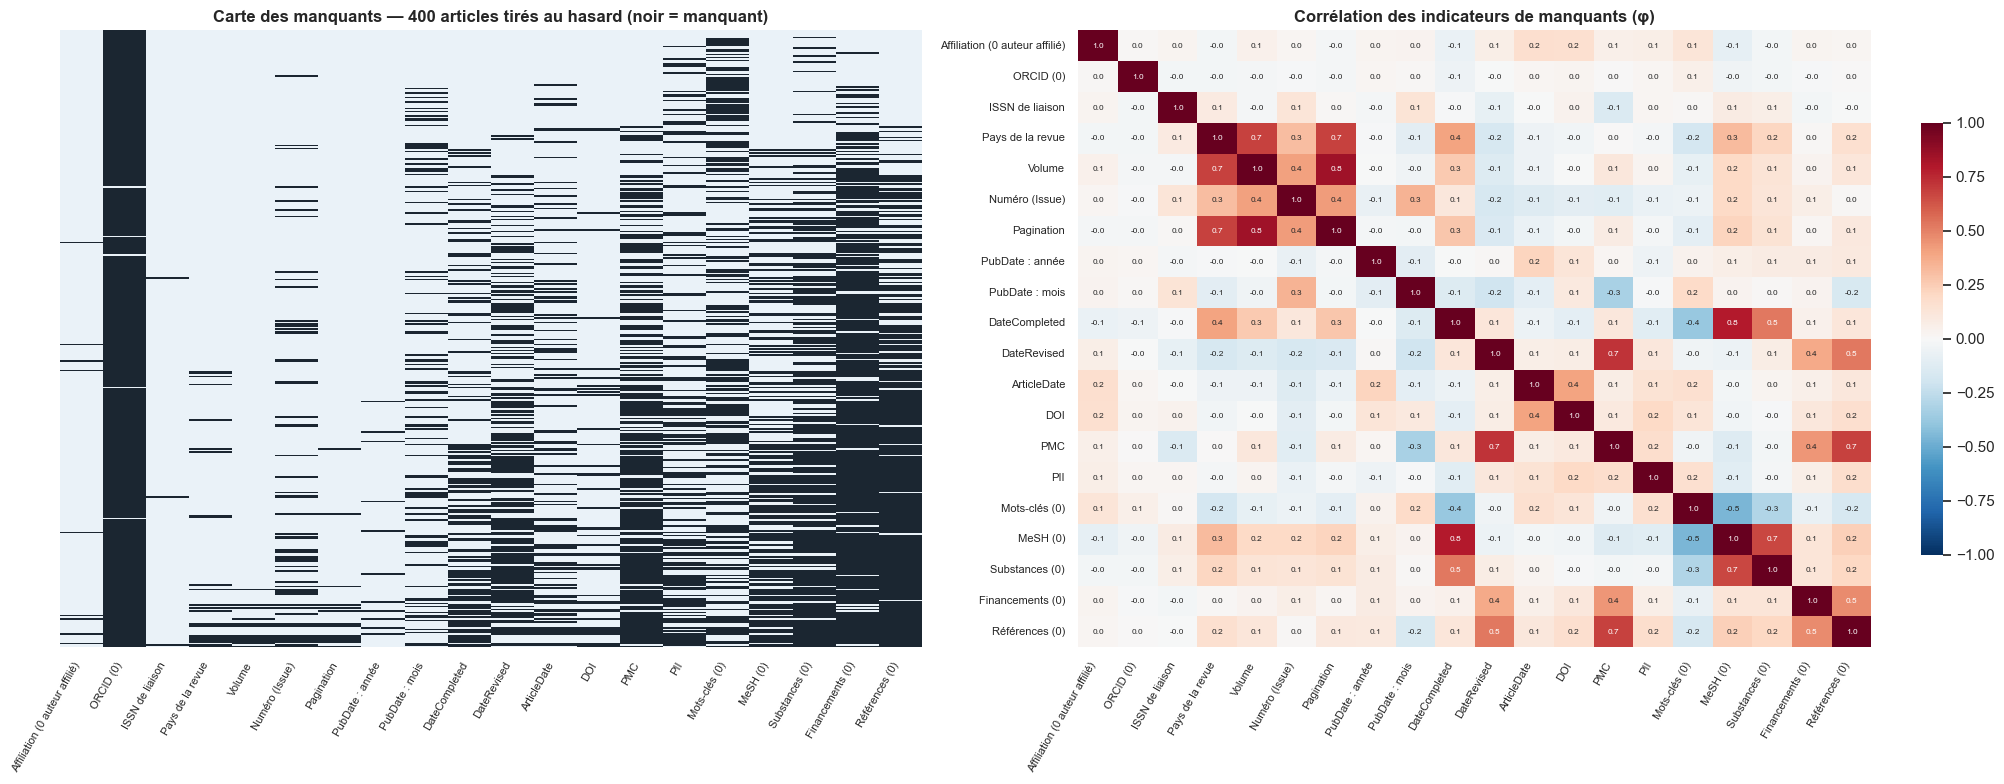

Paires de champs dont l'absence est la plus liée (|φ| élevé) :


phi
Volume           Pagination     0.84
DateCompleted    MeSH (0)       0.79
DateRevised      PMC            0.72
Pays de la revue Volume         0.69
                 Pagination     0.69
PMC              Références (0) 0.68
MeSH (0)         Substances (0) 0.67
DateRevised      Références (0) 0.53

In [35]:
var_cols = [c for c in M.columns if 0.5 < M[c].mean() * 100 < 99.5]
samp = M[var_cols].sample(min(400, len(M)), random_state=7)
samp = samp.loc[samp.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(1, 2, figsize=(21, 8), gridspec_kw={"width_ratios": [1, 1.15]})
sns.heatmap(samp.astype(int), cmap=["#EAF2F8", "#1B2631"], cbar=False, yticklabels=False, ax=ax[0]); ax[0].set(title=f"Carte des manquants — {len(samp)} articles tirés au hasard (noir = manquant)")
plt.setp(ax[0].get_xticklabels(), rotation=60, ha="right", fontsize=8)
corr = M[var_cols].astype(float).corr()
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 6}, ax=ax[1], cbar_kws={"shrink": .7}); ax[1].set(title="Corrélation des indicateurs de manquants (φ)")
plt.setp(ax[1].get_xticklabels(), rotation=60, ha="right", fontsize=8); plt.setp(ax[1].get_yticklabels(), fontsize=8)
plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print("Paires de champs dont l'absence est la plus liée (|φ| élevé) :")
pairs.head(8).rename("phi").to_frame()

## E3. Pourquoi manque-t-il ? Absence **structurelle** ou **aléatoire** ?
Test du χ² d'indépendance entre « champ manquant » et deux variables de contexte (**statut de la citation**, **année de création**), avec la force d'association (V de Cramér). `V ≥ 0,3` ⇒ l'absence **s'explique** par le contexte (structurelle) ; `V < 0,1` ⇒ plutôt aléatoire.

In [36]:
from scipy.stats import chi2_contingency
def cramers(x, y):
    t = pd.crosstab(x, y)
    if t.shape[0] < 2 or t.shape[1] < 2: return np.nan, np.nan
    chi2, p, _, _ = chi2_contingency(t); n = t.values.sum()
    return np.sqrt(chi2 / (n * (min(t.shape) - 1))), p

ctx = {"statut": art_ok.statut, "année de création": art_ok.cree_a, "modèle de publication": art_ok.pub_model}
res = []
for c in M.columns:
    if not (0.5 < M[c].mean() * 100 < 99.5): continue
    r = {"champ": c, "manquants_%": M[c].mean() * 100}
    for k, v in ctx.items():
        V, p = cramers(M[c], v); r[f"V ({k})"] = V
    r["nature"] = "STRUCTURELLE" if max(r[f"V ({k})"] for k in ctx) >= .3 else ("liée au contexte" if max(r[f"V ({k})"] for k in ctx) >= .1 else "plutôt aléatoire / facultative")
    res.append(r)
mech = pd.DataFrame(res).set_index("champ").sort_values("V (statut)", ascending=False)
export(mech, "E_nature_des_manquants")
(mech.style.background_gradient(subset=[c for c in mech.columns if c.startswith("V (")], cmap="OrRd", vmin=0, vmax=.8)
     .bar(subset=["manquants_%"], color="#f5b7b1", vmin=0, vmax=100).format({"manquants_%": "{:.1f}", **{c: "{:.2f}" for c in mech.columns if c.startswith("V (")}}))

#1.00: association forte
#0.30: association modérée
#0.10: association faible

#Cette fonction calcule le V de Cramér, une mesure statistique qui permet d'évaluer l'association entre deux variables catégorielles.
# Dans ton cas, on compare :
# - L'absence ou la présence d'une information.
# - Une variable de contexte, comme le statut de l'article.

,manquants_%,V (statut),V (année de création),V (modèle de publication),nature
champ,,,,,
MeSH (0),32.8,1.00,0.64,0.15,STRUCTURELLE
DateCompleted,23.4,1.00,0.66,0.19,STRUCTURELLE
Pays de la revue,4.8,1.00,0.20,0.11,STRUCTURELLE
Volume,3.3,0.69,0.16,0.09,STRUCTURELLE
Pagination,3.4,0.69,0.17,0.10,STRUCTURELLE
Substances (0),52.4,0.67,0.42,0.08,STRUCTURELLE
Mots-clés (0),46.7,0.46,0.41,0.28,STRUCTURELLE
PMC,58.5,0.38,0.16,0.42,STRUCTURELLE
DateRevised,44.9,0.37,0.17,0.30,STRUCTURELLE


Est-ce que les valeurs manquantes dans les données sont dues au hasard, ou sont-elles liées au statut de l'article, à son année de création ou à son modèle de publication ?

C'est une analyse de la nature des données manquantes (Missing Data Analysis).

Par exemple, si les articles MEDLINE possèdent presque toujours des termes MeSH, mais que les articles Publisher n'en possèdent pas, alors l'absence de MeSH dépend du statut de l'article. Elle n'est donc pas aléatoire.

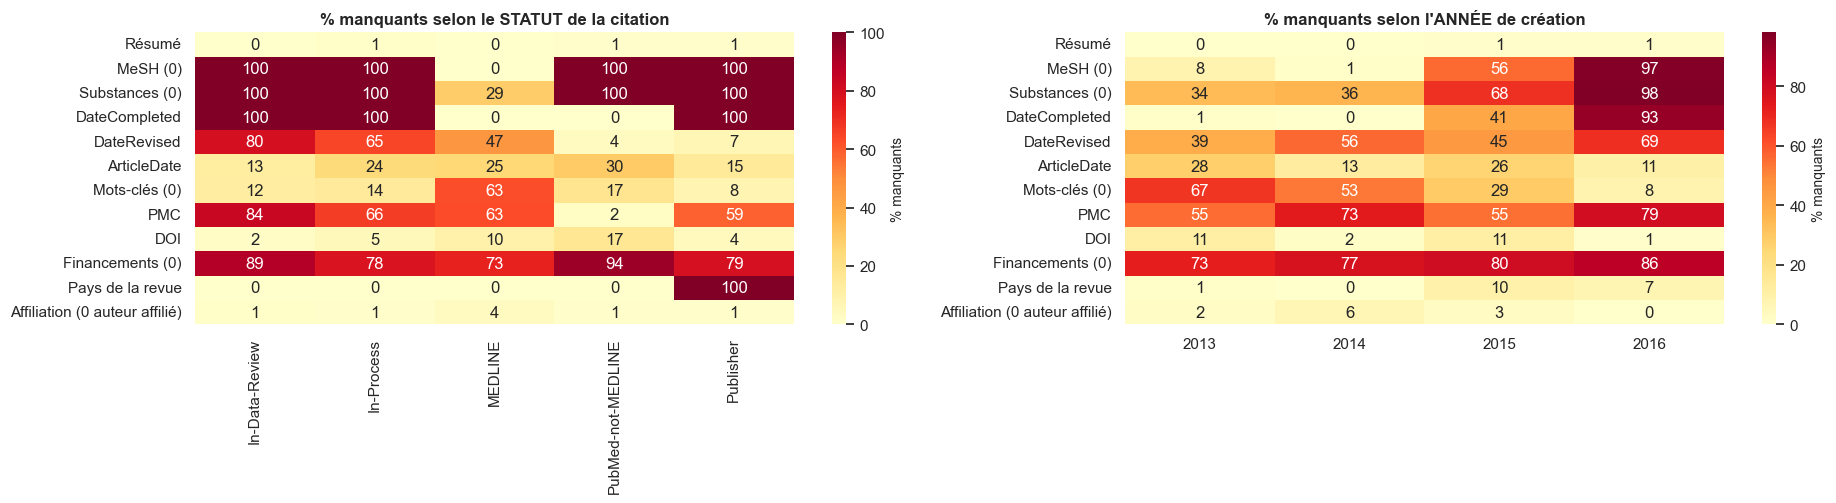

Lecture : un champ presque entièrement manquant pour UN statut (ex. MeSH pour 'Publisher') est inapplicable, pas perdu → on le laissera NULL / « Non indexé », sans imputation.


In [37]:
sel = ["Résumé", "MeSH (0)", "Substances (0)", "DateCompleted", "DateRevised", "ArticleDate", "Mots-clés (0)", "PMC", "DOI", "Financements (0)", "Pays de la revue", "Affiliation (0 auteur affilié)"]
sel = [c for c in sel if c in M.columns]
fig, ax = plt.subplots(1, 2, figsize=(19, 5.2))
sns.heatmap(M[sel].groupby(art_ok.statut).mean().T * 100, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "% manquants"}, ax=ax[0]); ax[0].set(title="% manquants selon le STATUT de la citation", xlabel="", ylabel="")
sns.heatmap(M[sel].groupby(art_ok.cree_a).mean().T * 100, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "% manquants"}, ax=ax[1]); ax[1].set(title="% manquants selon l'ANNÉE de création", xlabel="", ylabel="")
plt.tight_layout(); plt.show()
print("Lecture : un champ presque entièrement manquant pour UN statut (ex. MeSH pour 'Publisher') est inapplicable, pas perdu → on le laissera NULL / « Non indexé », sans imputation.")

## E4. Faux « présents » : placeholders et valeurs vides déguisées
Une valeur peut être **présente mais vide de sens** (`N/A`, `-`, `none`…) ; elle échappe aux contrôles `IS NULL`.

In [38]:
PLACEHOLDERS = {"", "n/a", "na", "none", "null", "nil", "-", "--", ".", "?", "unknown", "not available", "not applicable", "tbd", "nan", "[]", "()"}
def placeholder_scan(df, cols, label):
    out = []
    for c in cols:
        s = df[c].dropna().astype(str).str.strip().str.lower()
        n = int(s.isin(PLACEHOLDERS).sum()); ws = int((df[c].dropna().astype(str).str.strip() != df[c].dropna().astype(str)).sum())
        out.append(dict(table=label, colonne=c, valeurs_placeholder=n, espaces_en_trop=ws, total=len(s)))
    return out
scan = (placeholder_scan(art_ok, ["titre", "resume", "revue", "volume", "numero", "pagination", "pays_revue", "doi", "issn", "pmc", "medline_ta"], "art") +
        placeholder_scan(au, ["nom", "prenom", "initiales", "suffixe"], "auteurs") + placeholder_scan(af, ["affiliation"], "affils") +
        placeholder_scan(kw, ["mot_cle"], "mots_cles") + placeholder_scan(ms, ["descripteur"], "mesh") + placeholder_scan(ch, ["substance", "registre"], "chimie"))
scan = pd.DataFrame(scan); scan["pct"] = 100 * (scan.valeurs_placeholder) / scan.total
print(f"Colonnes scannées : {len(scan)} · colonnes avec placeholders : {(scan.valeurs_placeholder > 0).sum()} · colonnes avec espaces superflus : {(scan.espaces_en_trop > 0).sum()}")
scan[(scan.valeurs_placeholder > 0) | (scan.espaces_en_trop > 0)].sort_values("valeurs_placeholder", ascending=False).reset_index(drop=True)

#placeholder : valeur par défaut ou générique qui n'apporte pas d'information utile. Exemples : "n/a", "unknown", "null", "none", etc.


Colonnes scannées : 20 · colonnes avec placeholders : 5 · colonnes avec espaces superflus : 1


,table,colonne,valeurs_placeholder,espaces_en_trop,total,pct
0,art,pagination,132,0,3883,3.40
1,auteurs,initiales,22,0,28638,0.08
2,auteurs,prenom,11,0,28638,0.04
3,auteurs,nom,7,0,28640,0.02
4,art,issn,1,0,3878,0.03
5,affils,affiliation,0,1,16700,0.00


## E5. Complétude **par article** et qualité des articles réparés
Score = part des champs « cœur » renseignés. Il sert à (i) repérer les notices pauvres, (ii) **vérifier que le sauvetage des fichiers corrompus n'introduit pas de biais**.

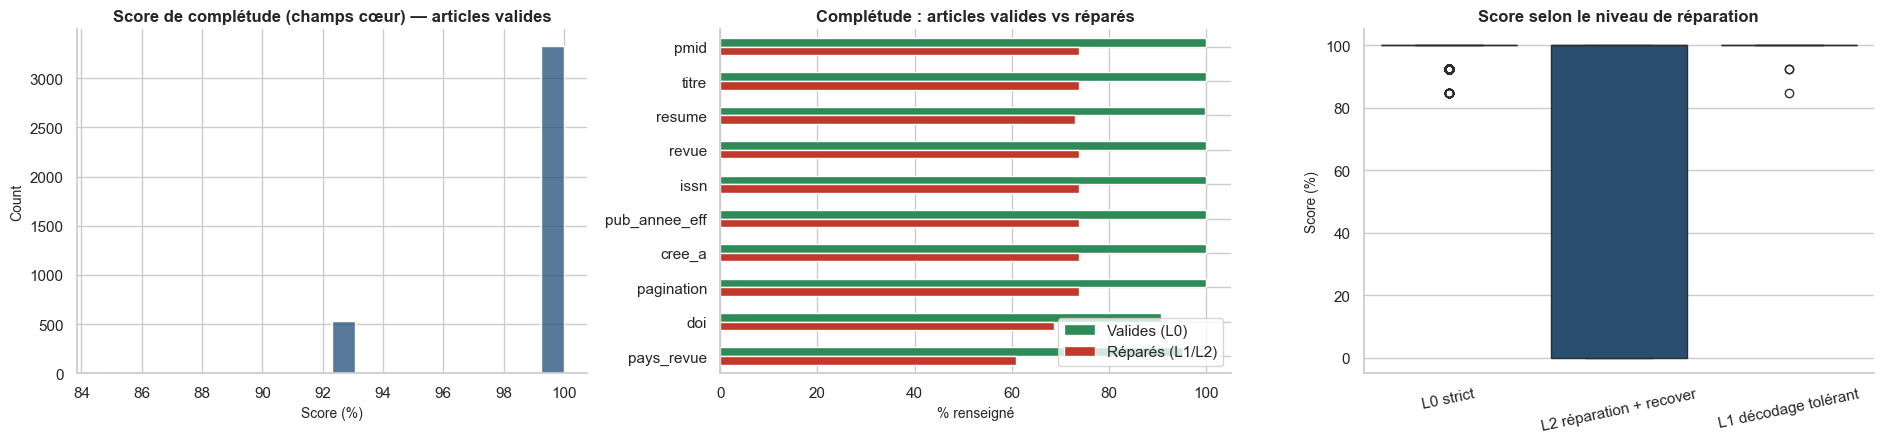

Score moyen : valides = 98.9 % · réparés = 72.1 %
Articles réparés ayant un titre ET un PMID : 115 / 156 · avec un résumé : 114 · avec des auteurs : 114
→ Les notices réparées sont nettement plus pauvres (troncature) : elles ne doivent PAS être mélangées aux statistiques de complétude des notices intactes.


,art_id,fichier,niveau_parse,score_completude
857,NOPMID:1745.xml,1745.xml,L2 réparation + recover,0.00
585,NOPMID:1473.xml,1473.xml,L2 réparation + recover,0.00
515,NOPMID:1405.xml,1405.xml,L2 réparation + recover,0.00
522,NOPMID:1411.xml,1411.xml,L2 réparation + recover,0.00
501,NOPMID:1392.xml,1392.xml,L2 réparation + recover,0.00
527,NOPMID:1415.xml,1415.xml,L2 réparation + recover,0.00
491,NOPMID:1384.xml,1384.xml,L2 réparation + recover,0.00
503,NOPMID:1393.xml,1393.xml,L2 réparation + recover,0.00


In [39]:
CORE = ["pmid", "titre", "resume", "revue", "issn", "pub_annee_eff", "cree_a", "pagination", "doi", "pays_revue"]
CORE_N = ["n_auteurs", "n_types_pub", "n_langues"]
def score(df):
    return (df[CORE].notna().sum(axis=1) + (df[CORE_N] > 0).sum(axis=1)) / (len(CORE) + len(CORE_N)) * 100
art["score_completude"] = score(art); art_ok = art[art.niveau_parse == "L0 strict"].copy(); art_rec = art[art.niveau_parse != "L0 strict"].copy()
fig, ax = plt.subplots(1, 3, figsize=(19, 4.6))
sns.histplot(art_ok.score_completude, bins=20, color=C["main"], ax=ax[0]); ax[0].set(title="Score de complétude (champs cœur) — articles valides", xlabel="Score (%)")
cmp_ = pd.DataFrame({"Valides (L0)": art_ok[CORE].notna().mean() * 100, "Réparés (L1/L2)": art_rec[CORE].notna().mean() * 100})
cmp_.plot.barh(ax=ax[1], color=[C["ok"], C["bad"]]); ax[1].set(title="Complétude : articles valides vs réparés", xlabel="% renseigné"); ax[1].invert_yaxis()
sns.boxplot(data=art, x="niveau_parse", y="score_completude", palette=[C["ok"], C["main"], C["bad"]][:art.niveau_parse.nunique()], ax=ax[2]); ax[2].set(title="Score selon le niveau de réparation", xlabel="", ylabel="Score (%)")
plt.setp(ax[2].get_xticklabels(), rotation=12); plt.tight_layout(); plt.show()
print(f"Score moyen : valides = {art_ok.score_completude.mean():.1f} % · réparés = {art_rec.score_completude.mean():.1f} %")
print(f"Articles réparés ayant un titre ET un PMID : {(art_rec.titre.notna() & art_rec.pmid.notna()).sum()} / {len(art_rec)} · avec un résumé : {art_rec.resume.notna().sum()} · avec des auteurs : {(art_rec.n_auteurs > 0).sum()}")
print("→ Les notices réparées sont nettement plus pauvres (troncature) : elles ne doivent PAS être mélangées aux statistiques de complétude des notices intactes.")
art[["art_id", "fichier", "niveau_parse", "score_completude"]].sort_values("score_completude").head(8)

pour graphique 3 :
L2 réparation + recover
C'est la boîte la plus grande.

Cela signifie que les scores sont beaucoup plus dispersés.

Autrement dit, les articles L2 n'ont pas tous le même niveau de complétude :
- Certains ont un score proche de 100 %.
- D'autres ont des scores beaucoup plus faibles.

La réparation XML ne garantit donc pas que tous les champs de l'article soient récupérés.

---
# PARTIE F — Doublons
Quatre niveaux, du plus grossier au plus fin : **fichiers**, **articles (PMID)**, **quasi-doublons** (même article sous un autre identifiant), **doublons internes** (auteurs/mots-clés répétés dans une même notice).

## F1. Doublons de PMID entre fichiers

Articles extraits (toutes sources) : 4,039 · PMID distincts : 3,967 · lignes en surplus : 31
PMID présents plusieurs fois : 31 (tailles de groupe : {2: 31})
Doublons entre fichiers VALIDES uniquement : 1 PMID · impliquant au moins un fichier RÉPARÉ : 30 PMID
PMID manquants (identifiés par nom de fichier) : 41


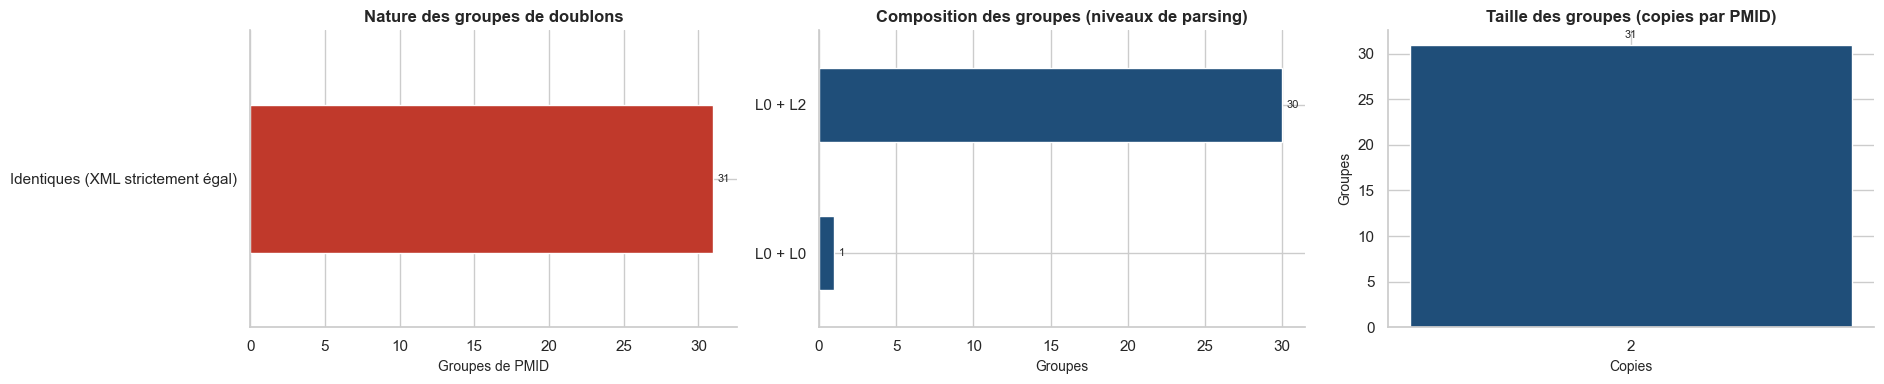

Constat clé : {'Identiques (XML strictement égal)': 31}
→ 30 des 31 PMID dupliqués impliquent une copie issue d'un fichier CORROMPU puis réparé : ces fichiers invalides sont en grande partie des RE-COPIES d'articles déjà présents.
→ Les 156 articles réparés se répartissent ainsi : 30 doublons d'un article valide · 41 sans PMID lisible · 85 articles NOUVEAUX récupérés.


,pmid,fichier,niveau_parse,statut,revise_a,revise_m,revise_j,n_auteurs,resume_n_sections,score_completude
3753,23718580,4928.xml,L0 strict,MEDLINE,None,None,None,4,4,100.00
3756,23718580,4931.xml,L2 réparation + recover,MEDLINE,None,None,None,4,4,100.00
1531,26078842,2420.xml,L0 strict,MEDLINE,2015,06,18,4,4,100.00
1532,26078842,2421.xml,L2 réparation + recover,MEDLINE,2015,06,18,4,4,100.00
1036,26165617,1924.xml,L2 réparation + recover,MEDLINE,None,None,None,6,1,100.00
1053,26165617,1941.xml,L0 strict,MEDLINE,None,None,None,6,1,100.00
1024,26169123,1912.xml,L0 strict,MEDLINE,None,None,None,5,1,100.00
1025,26169123,1913.xml,L2 réparation + recover,MEDLINE,None,None,None,5,1,100.00
858,26206503,1746.xml,L2 réparation + recover,MEDLINE,None,None,None,6,1,100.00
863,26206503,1751.xml,L0 strict,MEDLINE,None,None,None,6,1,100.00


In [40]:
dup_mask = art.art_id.duplicated(keep=False) & art.pmid.notna()
dups = art[dup_mask].sort_values(["pmid", "fichier"])
g = dups.groupby("pmid")
print(f"Articles extraits (toutes sources) : {len(art):,} · PMID distincts : {art.pmid.nunique():,} · lignes en surplus : {len(art) - art.pmid.nunique() - art.pmid.isna().sum():,}")
print(f"PMID présents plusieurs fois : {g.ngroups} (tailles de groupe : {g.size().value_counts().sort_index().to_dict()})")
print(f"Doublons entre fichiers VALIDES uniquement : {art_ok[art_ok.pmid.duplicated(keep=False)].pmid.nunique()} PMID · impliquant au moins un fichier RÉPARÉ : {dups.groupby('pmid').niveau_parse.apply(lambda s: (s != 'L0 strict').any()).sum()} PMID")
print(f"PMID manquants (identifiés par nom de fichier) : {art.pmid.isna().sum()}")

RAWCOLS = [c for c in art.columns if c not in ("art_id", "fichier", "niveau_parse", "hash_contenu", "score_completude", "pmid") and not c.endswith("_dt")
           and c not in ("longueur_titre", "mots_titre", "longueur_resume", "mots_resume", "pub_precision")]
def groupe_type(d):
    if d.hash_contenu.notna().all() and d.hash_contenu.nunique() == 1: return "Identiques (XML strictement égal)"
    if all(d[c].astype(str).nunique() == 1 for c in RAWCOLS): return "Identiques sur tous les champs extraits"
    return "Divergents (au moins un champ diffère)"
gt = g.apply(groupe_type).value_counts()
comp = dups.groupby("pmid").niveau_parse.apply(lambda s: " + ".join(sorted(s.str[:2]))).value_counts()
fig, ax = plt.subplots(1, 3, figsize=(19, 4))
gt.sort_values().plot.barh(color=[C["bad"], C["warn"], C["ok"]][:len(gt)], ax=ax[0]); show_bar_labels(ax[0], horizontal=True); ax[0].set(title="Nature des groupes de doublons", xlabel="Groupes de PMID", ylabel="")
comp.sort_values().plot.barh(color=C["main"], ax=ax[1]); show_bar_labels(ax[1], horizontal=True); ax[1].set(title="Composition des groupes (niveaux de parsing)", xlabel="Groupes", ylabel="")
sizes = g.size().value_counts().sort_index(); ax[2].bar(sizes.index.astype(str), sizes.values, color=C["main"]); show_bar_labels(ax[2]); ax[2].set(title="Taille des groupes (copies par PMID)", xlabel="Copies", ylabel="Groupes")
plt.tight_layout(); plt.show()
print("Constat clé :", gt.to_dict())
n_rep_dup = dups.groupby("pmid").niveau_parse.apply(lambda s: (s != "L0 strict").any()).sum()
print(f"→ {n_rep_dup} des {g.ngroups} PMID dupliqués impliquent une copie issue d'un fichier CORROMPU puis réparé : ces fichiers invalides sont en grande partie des RE-COPIES d'articles déjà présents.")
print(f"→ Les {len(art_rec)} articles réparés se répartissent ainsi : {n_rep_dup} doublons d'un article valide · {int(art_rec.pmid.isna().sum())} sans PMID lisible · {len(art_rec) - n_rep_dup - int(art_rec.pmid.isna().sum())} articles NOUVEAUX récupérés.")
dups[["pmid", "fichier", "niveau_parse", "statut", "revise_a", "revise_m", "revise_j", "n_auteurs", "resume_n_sections", "score_completude"]].head(12)

Quelle copie est gardée ?

Le notebook propose une règle de priorité, qu’il appelle « proposition, testable » :

la copie structurellement intacte (L0 avant L1, avant L2) ;
sinon la DateRevised la plus récente ;
sinon la notice la plus complète ;
sinon le plus petit numéro de fichier.

### Quels champs diffèrent entre copies d'un même PMID ?
Si les copies divergent, il faut une **règle de survie** (quelle copie garder ?). On mesure *quels champs* changent pour la définir objectivement.

In [41]:
diffs = Counter(); diffs_vv = Counter()
for pm, d in g:
    for c in RAWCOLS:
        if d[c].astype(str).nunique() > 1:
            diffs[c] += 1
            if (d.niveau_parse == "L0 strict").all(): diffs_vv[c] += 1
dd = pd.DataFrame({"groupes_où_diffère": pd.Series(diffs), "dont_copies_toutes_valides": pd.Series(diffs_vv)}).fillna(0).astype(int).sort_values("groupes_où_diffère", ascending=False)
print(f"Champs qui diffèrent entre copies : {len(dd)} sur {len(RAWCOLS)}")
dd.head(15)

Champs qui diffèrent entre copies : 0 sur 73


,groupes_où_diffère,dont_copies_toutes_valides


### Règle de dédoublonnage (proposition, testable)
Ordre de priorité : **1)** copie structurellement intacte (L0 > L1 > L2) → **2)** `DateRevised` la plus récente → **3)** notice la plus complète → **4)** plus petit numéro de fichier (déterministe, ⇒ ETL **reproductible**).

In [42]:
LVL = {"L0 strict": 0, "L1 décodage tolérant": 1, "L2 réparation + recover": 2}
def dedup(df):
    d = df.copy(); d["_lvl"] = d.niveau_parse.map(LVL); d["_rev"] = d.revise_dt.fillna(pd.Timestamp("1900-01-01")); d["_num"] = d.fichier.str.extract(r"(\d+)")[0].astype(int)
    d = d.sort_values(["pmid", "_lvl", "_rev", "score_completude", "_num"], ascending=[True, True, False, False, True], na_position="last")
    keep = d.drop_duplicates("art_id", keep="first")
    return keep.drop(columns=["_lvl", "_rev", "_num"]), d[d.duplicated("art_id", keep="first")]
art_dedup, art_dropped = dedup(art)
print(f"Avant : {len(art):,} lignes → après dédoublonnage : {len(art_dedup):,} articles uniques ({len(art_dropped)} copies écartées, tracées dans 'F_doublons_ecartes.csv').")
export(art_dropped[["art_id", "fichier", "niveau_parse", "statut", "score_completude"]].set_index("art_id"), "F_doublons_ecartes")
assert art_dedup.art_id.is_unique

Avant : 4,039 lignes → après dédoublonnage : 4,008 articles uniques (31 copies écartées, tracées dans 'F_doublons_ecartes.csv').


## F2. Quasi-doublons : le même article sous des identifiants différents ?
Un PMID distinct n'empêche pas un doublon éditorial (correctif, republication, double indexation).

In [43]:
norm = lambda s: s.str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
base = art_dedup.assign(titre_norm=norm(art_dedup.titre.fillna("")))
t_dup = base[(base.titre_norm != "") & base.titre_norm.duplicated(keep=False)].sort_values("titre_norm")
doi_dup = base[base.doi.notna() & base.doi.str.lower().duplicated(keep=False)].sort_values("doi")
tjy = base[(base.titre_norm != "") & base.duplicated(["titre_norm", "revue", "pub_annee_eff"], keep=False)]
same_j = t_dup.groupby("titre_norm").revue.nunique().gt(1).mean() * 100 if len(t_dup) else 0
print(f"Titres normalisés partagés par ≥ 2 PMID : {t_dup.titre_norm.nunique()} titres ({len(t_dup)} notices) — revues DIFFÉRENTES dans {same_j:.0f} % des cas")
print("   → homonymes éditoriaux ou version traduite/originale d'un même titre : ce ne sont PAS des doublons à supprimer (l'identité reste le PMID).")
print(f"DOI partagés par ≥ 2 PMID : {doi_dup.doi.str.lower().nunique()} DOI ({len(doi_dup)} notices)")
print(f"Même (titre, revue, année) pour des PMID distincts : {tjy.titre_norm.nunique()} cas")
# Notices SANS PMID lisible (articles réparés) : sont-elles déjà présentes sous un autre fichier ?
nop = base[base.pmid.isna() & (base.titre_norm != "")]
connus = set(base[base.pmid.notna()].titre_norm)
doi_connus = set(base[base.pmid.notna() & base.doi.notna()].doi.str.lower())
m_titre = nop.titre_norm.isin(connus); m_doi = nop.doi.str.lower().isin(doi_connus)
print(f"Notices sans PMID : {base.pmid.isna().sum()} · avec titre exploitable : {len(nop)} · retrouvées via titre : {int(m_titre.sum())} · via DOI : {int(m_doi.sum())} · via l'un OU l'autre : {int((m_titre | m_doi).sum())}")
print("→ Ces notices ne pourront pas être dédoublonnées par PMID : règle de rattachement (titre normalisé / DOI) à décider à l'étape nettoyage.")
t_dup[["pmid", "titre", "revue", "pub_annee_eff", "n_auteurs"]].head(10)

Titres normalisés partagés par ≥ 2 PMID : 3 titres (6 notices) — revues DIFFÉRENTES dans 100 % des cas
   → homonymes éditoriaux ou version traduite/originale d'un même titre : ce ne sont PAS des doublons à supprimer (l'identité reste le PMID).
DOI partagés par ≥ 2 PMID : 0 DOI (0 notices)
Même (titre, revue, année) pour des PMID distincts : 0 cas
Notices sans PMID : 41 · avec titre exploitable : 0 · retrouvées via titre : 0 · via DOI : 0 · via l'un OU l'autre : 0
→ Ces notices ne pourront pas être dédoublonnées par PMID : règle de rattachement (titre normalisé / DOI) à décider à l'étape nettoyage.


,pmid,titre,revue,pub_annee_eff,n_auteurs
2650,24070500,Exposure to toxic environmental agents.,Fertility and sterility,2013,1
3219,24084567,Exposure to toxic environmental agents.,Obstetrics and gynecology,2013,1
3864,23695158,[Management of prostate cancer in the elderly].,Der Urologe. Ausg. A,2013,6
70,26614864,Management of Prostate Cancer in the Elderly.,Clinics in geriatric medicine,2016,3
3343,23821844,[Osteoporosis in men].,Revue me´dicale suisse,2013,2
2352,24019112,Osteoporosis in men.,Nature reviews. Endocrinology,2013,2


## F3. Doublons **internes** à une notice (relations N-N à déduper)
Un même auteur, mot-clé ou descripteur répété dans une seule notice fausserait les décomptes (*« nombre d'auteurs »*, *« publications par mot-clé »*).

on compare des infos dans mm article pas dans 2 articles differents.

=> Détecter des informations répétées dans les tables enfants d'un même article.

In [44]:
def intra(df, keycols, label):
    d = df.copy()
    for c in keycols: d[c] = d[c].astype("string").str.strip().str.lower()
    dm = d.duplicated(["art_id"] + keycols, keep=False)
    return dict(table=label, lignes=len(d), lignes_en_double=int(dm.sum()), surplus_a_retirer=int(d.duplicated(["art_id"] + keycols).sum()), articles_concernes=int(d[dm].art_id.nunique()))
def only_keep(df):
    return df.merge(art_dedup[["art_id", "fichier"]], on=["art_id", "fichier"])
f3 = pd.DataFrame([
    intra(only_keep(auteurs), ["nom", "prenom", "initiales"], "auteurs (nom+prénom+initiales)"),
    intra(only_keep(mots_cles), ["mot_cle"], "mots_cles (insensible à la casse)"),
    intra(only_keep(mesh), ["ui"], "mesh (par UI)"),
    intra(only_keep(chimie), ["ui", "substance"], "chimie"),
    intra(only_keep(types_pub), ["type"], "types_pub"), intra(only_keep(langues), ["langue"], "langues"),
    intra(only_keep(ids_article), ["type_id", "valeur"], "ids_article"),
    intra(only_keep(grants), ["grant_id", "agence"], "grants"), intra(only_keep(commentaires), ["type_ref", "pmid_ref"], "commentaires (même réf. citée 2×)"),
    intra(only_keep(affils).assign(k=lambda d: d.rang_auteur.astype(str)), ["k", "affiliation"], "affils (même auteur, même texte)"),
]).set_index("table"); f3["% lignes en double"] = 100 * f3.lignes_en_double / f3.lignes
export(f3, "F_doublons_internes")
f3.style.bar(subset=["% lignes en double"], color="#f5b7b1", vmin=0, vmax=max(5, f3["% lignes en double"].max())).format({"% lignes en double": "{:.2f}", "lignes": "{:,}"})

,lignes,lignes_en_double,surplus_a_retirer,articles_concernes,% lignes en double
table,,,,,
auteurs (nom+prénom+initiales),"29,336",19,11,8,0.06
mots_cles (insensible à la casse),"12,707",50,25,20,0.39
mesh (par UI),"36,034",0,0,0,0.00
chimie,"8,254",0,0,0,0.00
types_pub,"7,874",0,0,0,0.00
langues,"3,995",0,0,0,0.00
ids_article,"12,016",0,0,0,0.00
grants,"3,354",292,146,107,8.71
commentaires (même réf. citée 2×),"49,952",2,1,1,0.00


**Analyse des doublons internes**

L'analyse des doublons internes montre que la majorité des tables secondaires ne présentent aucune duplication selon les critères de comparaison définis. Quelques doublons sont détectés dans les tables `auteurs`, `mots_cles`, `commentaires` et `affils`, mais leur proportion reste très faible.

En revanche, la table `grants` présente un taux de lignes en double de 8,71 %, avec 292 lignes concernées réparties sur 107 articles, dont 146 lignes supplémentaires.

Ces résultats indiquent que les duplications internes restent globalement limitées, mais que la table `grants` mérite une attention particulière lors de la phase de nettoyage afin d'éviter la répétition des mêmes associations article-financement.

In [45]:
# Focus : l'affiliation textuelle est massivement répétée d'un auteur à l'autre → atout (dimension réutilisable) et risque (ne pas compter 2× l'institution)
aff_reuse = af.groupby("art_id").agg(lignes=("affiliation", "size"), distinctes=("affiliation", "nunique"))
print(f"Dans un même article, {100*(1-aff_reuse.distinctes.sum()/aff_reuse.lignes.sum()):.1f} % des lignes d'affiliation répètent un texte déjà vu dans cette notice.")
print(f"Au niveau du corpus : {af.affiliation.nunique():,} textes distincts pour {len(af):,} lignes → dimension Affiliation ~ {100*af.affiliation.nunique()/len(af):.0f} % de la taille de la table des affiliations (auteur × affiliation).")

Dans un même article, 38.8 % des lignes d'affiliation répètent un texte déjà vu dans cette notice.
Au niveau du corpus : 9,920 textes distincts pour 16,700 lignes → dimension Affiliation ~ 59 % de la taille de la table des affiliations (auteur × affiliation).


---
# PARTIE G — Cohérence, validité des formats et anomalies
Un champ peut être **présent et unique** mais **faux** : mauvais format, date impossible, texte corrompu. On teste des **règles explicites** et on tient un **registre d'anomalies** (alimentera le livrable L03 « Règles de nettoyage »).

## G1. Validité des formats (expressions régulières)

L'objectif est de vérifier si les valeurs respectent les formats attendus : PMID numérique, DOI correctement écrit, ISSN valide, mois compris entre 1 et 12, année cohérente, date calendaire possible, etc.

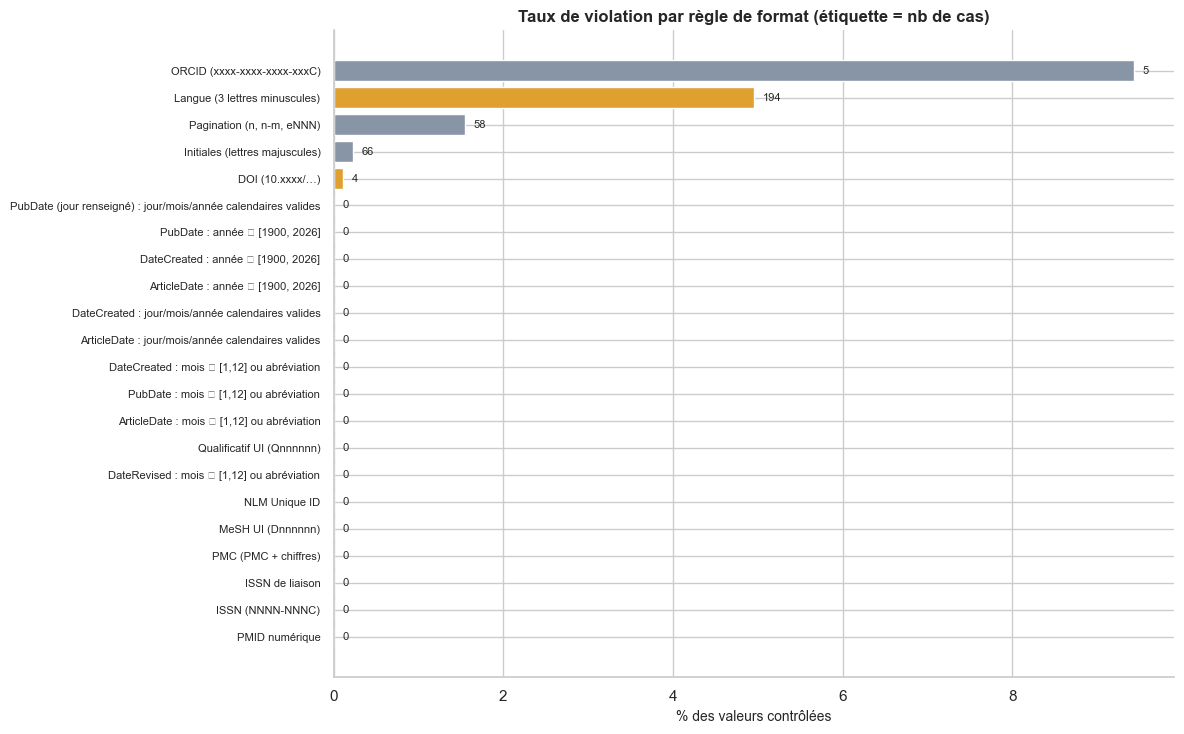

22 règles testées · 5 avec au moins une violation · 327 violations au total.


,règle,contrôlés,violations,pct,gravité,exemples
0,ORCID (xxxx-xxxx-xxxx-xxxC),53,5,9.43,mineure,0000000252229857 | 0000000171236123 | 0000000328943345
1,Langue (3 lettres minuscules),3912,194,4.96,majeure,ENG | ENG | ENG
2,"Pagination (n, n-m, eNNN)",3751,58,1.55,mineure,36-42.e1-2 | 119.e11-8 | 119.e1-9
3,Initiales (lettres majuscules),28638,66,0.23,mineure,Á | Á | Ø
4,DOI (10.xxxx/…),3522,4,0.11,majeure,DOI:10.11817/j.issn.1672-7347. | DOI:10.11817/j.issn.1672-7347. | 10.231/JIM.000000000...


In [46]:
ANOM = []
def note(domaine, anomalie, n, total, gravite, traitement):
    if n > 0: ANOM.append(dict(domaine=domaine, anomalie=anomalie, volume=int(n), base=int(total), pct=100 * n / max(total, 1), gravité=gravite, traitement_proposé=traitement))

def rx_rule(label, series, rx, gravite, traitement, ignore_case=False):
    s = series.dropna().astype(str).str.strip(); s = s[s != ""]
    bad = ~s.str.match(rx, case=not ignore_case)
    note("Format", f"{label} au format invalide", bad.sum(), len(s), gravite, traitement)
    return dict(règle=label, contrôlés=len(s), violations=int(bad.sum()), pct=100 * bad.sum() / max(len(s), 1), gravité=gravite, exemples=" | ".join(s[bad].head(3).str[:30]))

def month_rule(label, s):
    v = s.dropna().map(mnum); bad = v.isna() | (v < 1) | (v > 12)
    note("Date", f"{label} : mois invalide", bad.sum(), len(v), "majeure", "Convertir (Jan→1) ; sinon NULL")
    return dict(règle=f"{label} : mois ∈ [1,12] ou abréviation", contrôlés=len(v), violations=int(bad.sum()), pct=100 * bad.sum() / max(len(v), 1), gravité="majeure", exemples=" | ".join(s.dropna()[bad.values].head(3).astype(str)))

def year_rule(label, s):
    v = pd.to_numeric(s, errors="coerce").dropna(); bad = (v < 1900) | (v > 2026)
    note("Date", f"{label} : année hors [1900, 2026]", bad.sum(), len(v), "critique", "Rejeter la date (NULL) et journaliser")
    return dict(règle=f"{label} : année ∈ [1900, 2026]", contrôlés=len(v), violations=int(bad.sum()), pct=100 * bad.sum() / max(len(v), 1), gravité="critique", exemples=" | ".join(v[bad].head(3).astype(int).astype(str)))

def calendar_rule(label, y, m, d):
    mask = y.notna() & m.notna() & d.notna(); dt = to_dt(y[mask], m[mask], d[mask]); bad = dt.isna()
    note("Date", f"{label} : date calendaire impossible", bad.sum(), mask.sum(), "critique", "Rejeter la date (NULL) et journaliser")
    return dict(règle=f"{label} : jour/mois/année calendaires valides", contrôlés=int(mask.sum()), violations=int(bad.sum()), pct=100 * bad.sum() / max(mask.sum(), 1), gravité="critique", exemples="")

rules = [
    rx_rule("PMID numérique", art_ok.pmid, r"^\d{1,9}$", "critique", "Rejeter l'article"),
    rx_rule("DOI (10.xxxx/…)", art_ok.doi, r"^10\.\d{4,9}/\S+$", "majeure", "Mettre à NULL, conserver la valeur brute en staging"),
    rx_rule("ISSN (NNNN-NNNC)", art_ok.issn, r"^\d{4}-\d{3}[\dXx]$", "majeure", "NULL si invalide"), rx_rule("ISSN de liaison", art_ok.issn_liaison, r"^\d{4}-\d{3}[\dXx]$", "majeure", "NULL si invalide"),
    rx_rule("PMC (PMC + chiffres)", art_ok.pmc, r"^PMC\d+$", "mineure", "NULL si invalide"), rx_rule("NLM Unique ID", art_ok.nlm_id, r"^\d{6,9}R?$", "majeure", "Clé de revue : vérifier"),
    rx_rule("ORCID (xxxx-xxxx-xxxx-xxxC)", au.orcid, r"^(https?://orcid\.org/)?\d{4}-\d{4}-\d{4}-\d{3}[\dXx]$", "mineure", "Normaliser en retirant l'URL"),
    rx_rule("MeSH UI (Dnnnnnn)", ms.ui, r"^D\d{6,9}$", "majeure", "Vérifier les descripteurs « C… » (supplémentaires)"), rx_rule("Qualificatif UI (Qnnnnnn)", mq.ui, r"^Q\d{6}$", "majeure", "NULL si invalide"),
    rx_rule("Langue (3 lettres minuscules)", lg.langue, r"^[a-z]{3}$", "majeure", "Mettre en minuscules + trim"),
    rx_rule("Initiales (lettres majuscules)", au.initiales, r"^[A-Z]{1,6}$", "mineure", "Majuscules ; accents/minuscules à examiner"),
    rx_rule("Pagination (n, n-m, eNNN)", art_ok.pagination, r"^[A-Za-z]{0,3}\d+([\-–][A-Za-z]{0,3}\d+)?(, ?[A-Za-z]{0,3}\d+([\-–][A-Za-z]{0,3}\d+)?)*$", "mineure", "Conserver brut ; ne pas parser"),
    month_rule("PubDate", art_ok.pub_mois), month_rule("DateCreated", art_ok.cree_m), month_rule("DateRevised", art_ok.revise_m), month_rule("ArticleDate", art_ok.art_date_m),
    year_rule("PubDate", art_ok.pub_annee_eff), year_rule("DateCreated", art_ok.cree_a), year_rule("ArticleDate", art_ok.art_date_a),
    calendar_rule("DateCreated", art_ok.cree_a, art_ok.cree_m, art_ok.cree_j), calendar_rule("ArticleDate", art_ok.art_date_a, art_ok.art_date_m, art_ok.art_date_j),
    calendar_rule("PubDate (jour renseigné)", art_ok.pub_annee, art_ok.pub_mois, art_ok.pub_jour),
]
rules = pd.DataFrame(rules)
fig, ax = plt.subplots(figsize=(12, 7.5))
rr = rules.sort_values("pct")
ax.barh(rr.règle, rr.pct, color=rr.gravité.map({"critique": C["bad"], "majeure": C["warn"], "mineure": C["grey"]}))
for i, (p, v) in enumerate(zip(rr.pct, rr.violations)): ax.text(p + .1, i, f"{v}", va="center", fontsize=8)
ax.set(title="Taux de violation par règle de format (étiquette = nb de cas)", xlabel="% des valeurs contrôlées"); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()
print(f"{len(rules)} règles testées · {(rules.violations > 0).sum()} avec au moins une violation · {int(rules.violations.sum()):,} violations au total.")
export(rules.set_index("règle"), "G_validite_formats")
rules[rules.violations > 0].sort_values("pct", ascending=False).reset_index(drop=True)

## G2. Cohérence temporelle et logique inter-champs

In [47]:
TODAY = pd.Timestamp.today().normalize()
def temporal(label, mask_base, mask_viol, gravite, traitement):
    n, N = int((mask_base & mask_viol).sum()), int(mask_base.sum()); note("Cohérence temporelle", label, n, N, gravite, traitement)
    return dict(règle=label, contrôlés=N, violations=n, pct=100 * n / max(N, 1), gravité=gravite)

H = only_ok(historique).assign(dt=lambda d: to_dt(d.annee, d.mois, d.jour)).pivot_table(index="art_id", columns="statut", values="dt", aggfunc="min")
a = art_ok.set_index("art_id").join(H, how="left")
both = lambda x, y: a[x].notna() & a[y].notna()
tr_rules = pd.DataFrame([
    temporal("DateCompleted < DateCreated", both("complete_dt", "cree_dt"), a.complete_dt < a.cree_dt, "majeure", "Conserver, signaler"),
    temporal("DateRevised < DateCreated", both("revise_dt", "cree_dt"), a.revise_dt < a.cree_dt, "majeure", "Conserver, signaler"),
    temporal("DateRevised < DateCompleted", both("revise_dt", "complete_dt"), a.revise_dt < a.complete_dt, "mineure", "Conserver, signaler"),
    temporal("ArticleDate postérieure de > 60 j à DateCreated", both("art_dt", "cree_dt"), (a.art_dt - a.cree_dt).dt.days > 60, "mineure", "Information (publication en ligne tardive)"),
    temporal("PubDate postérieure de > 12 mois à DateCreated", both("pub_dt", "cree_dt"), (a.pub_dt - a.cree_dt).dt.days > 365, "mineure", "Information (fascicule différé)"),
    temporal("Historique : received > accepted", both("received", "accepted"), a.received > a.accepted, "majeure", "NULL sur la date en cause"),
    temporal("Historique : accepted > entrez", both("accepted", "entrez"), a.accepted > a.entrez, "mineure", "Information"),
    temporal("Historique : entrez > medline", both("entrez", "medline"), a.entrez > a.medline, "mineure", "Information"),
    temporal("Dates dans le futur (> aujourd'hui)", a.pub_dt.notna(), a.pub_dt > TODAY, "majeure", "NULL"),
]).set_index("règle")
display(tr_rules.style.format({"pct": "{:.2f}"}).bar(subset=["pct"], color="#f5b7b1", vmin=0, vmax=max(5, tr_rules.pct.max())))
rho = a[["cree_dt"]].assign(pmid=pd.to_numeric(a.pmid, errors="coerce"), t=lambda d: d.cree_dt.astype("int64") // 10**9).dropna()[["pmid", "t"]].corr(method="spearman").iloc[0, 1]
print(f"Corrélation de rang PMID ↔ date de création de la notice : ρ = {rho:.3f}  (un PMID croissant suit l'ordre d'entrée dans PubMed → sanity-check réussi si ρ proche de 1)")

,contrôlés,violations,pct,gravité
règle,,,,
DateCompleted < DateCreated,2976,0,0.00,majeure
DateRevised < DateCreated,2138,0,0.00,majeure
DateRevised < DateCompleted,1739,183,10.52,mineure
ArticleDate postérieure de > 60 j à DateCreated,2936,0,0.00,mineure
PubDate postérieure de > 12 mois à DateCreated,3883,0,0.00,mineure
Historique : received > accepted,2339,0,0.00,majeure
Historique : accepted > entrez,2444,1,0.04,mineure
Historique : entrez > medline,3883,21,0.54,mineure
Dates dans le futur (> aujourd'hui),3883,0,0.00,majeure


Corrélation de rang PMID ↔ date de création de la notice : ρ = 0.899  (un PMID croissant suit l'ordre d'entrée dans PubMed → sanity-check réussi si ρ proche de 1)


## G3. Propreté du texte : espaces, encodage, HTML, casse
Les colonnes textuelles alimenteront des dimensions : un espace en trop ou un accent corrompu crée un **faux membre** de dimension.

détecter les anomalies présentes dans les textes : espaces inutiles, caractères mal encodés, balises HTML, entités HTML, caractères invisibles, etc.

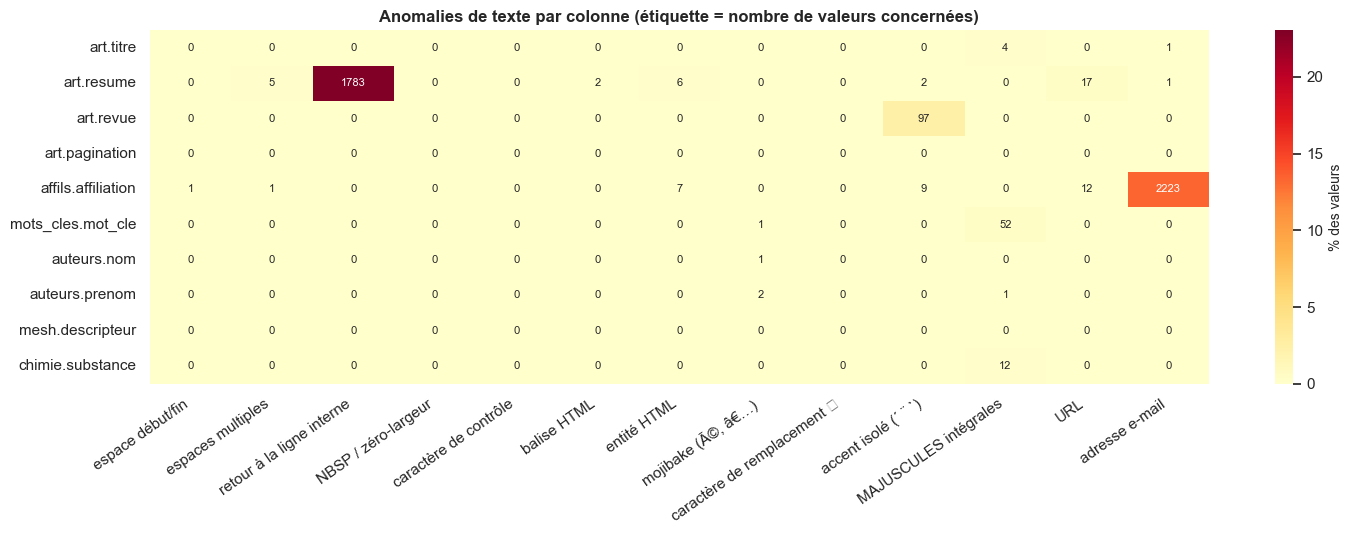

Exemples d'accents isolés (journaux) : ['Contemporary oncology (Poznan´, Poland)', 'Strahlentherapie und Onkologie : Organ der Deutschen Ro¨ntgengesellschaft ... [et al]', 'Reports of practical oncology and radiotherapy : journal of Greatpoland Cancer Center in Poznan´ and Polish Society of Radiation Oncology', 'Cancer radiothe´rapie : journal de la Socie´te´ franc¸aise de radiothe´rapie oncologique', "Progre`s en urologie : journal de l'Association franc¸aise d'urologie et de la Socie´te´ franc¸aise d'urologie"]
Caractère de remplacement '�' dans les articles RÉPARÉS (L1) : titres 1 · résumés 8


,valeurs,avec_≥1_anomalie_%
colonne,,
art.titre,3883,0.13
art.resume,3872,46.46
art.revue,3883,2.50
art.pagination,3883,0.00
affils.affiliation,16700,13.47
mots_cles.mot_cle,12360,0.43
auteurs.nom,28640,0.00
auteurs.prenom,28638,0.01
mesh.descripteur,35778,0.00


In [48]:
TEXT = {"art.titre": art_ok.titre, "art.resume": art_ok.resume, "art.revue": art_ok.revue, "art.pagination": art_ok.pagination, "affils.affiliation": af.affiliation,
        "mots_cles.mot_cle": kw.mot_cle, "auteurs.nom": au.nom, "auteurs.prenom": au.prenom, "mesh.descripteur": ms.descripteur, "chimie.substance": ch.substance}
FLAGS = {
    "espace début/fin": lambda s: s != s.str.strip(), "espaces multiples": lambda s: s.str.contains(r"[ \t]{2,}", regex=True),
    "retour à la ligne interne": lambda s: s.str.contains(r"[\r\n]", regex=True), "NBSP / zéro-largeur": lambda s: s.str.contains("[\u00a0\u200b\u200c\u200d\ufeff]", regex=True),
    "caractère de contrôle": lambda s: s.str.contains(r"[\x00-\x08\x0b\x0c\x0e-\x1f]", regex=True), "balise HTML": lambda s: s.str.contains(r"</?[A-Za-z][^>]*>", regex=True),
    "entité HTML": lambda s: s.str.contains(r"&(?:amp|lt|gt|quot|apos|#\d+);", regex=True), "mojibake (Ã©, â€…)": lambda s: s.str.contains("Ã.|Â.|â€|ï¿½", regex=True),
    "caractère de remplacement �": lambda s: s.str.contains("\ufffd", regex=False), "accent isolé (´ ¨ `)": lambda s: s.str.contains(r"[´¨`]", regex=True),
    "MAJUSCULES intégrales": lambda s: (s.str.len() > 8) & (s == s.str.upper()) & s.str.contains(r"[A-Z]", regex=True), "URL": lambda s: s.str.contains(r"https?://|www\.", regex=True),
    "adresse e-mail": lambda s: s.str.contains(r"\S+@\S+\.\S+", regex=True),
}
cnt = pd.DataFrame({k: {f: int(fn(v.dropna().astype(str)).sum()) for f, fn in FLAGS.items()} for k, v in TEXT.items()}).T
pctm = pd.DataFrame({k: {f: 100 * cnt.at[k, f] / max(v.notna().sum(), 1) for f in FLAGS} for k, v in TEXT.items()}).T
fig, ax = plt.subplots(figsize=(15, 5.5))
sns.heatmap(pctm, annot=cnt.values, fmt="d", cmap="YlOrRd", vmin=0, vmax=max(10, pctm.values.max() / 2), cbar_kws={"label": "% des valeurs"}, annot_kws={"size": 8}, ax=ax)
ax.set(title="Anomalies de texte par colonne (étiquette = nombre de valeurs concernées)"); plt.setp(ax.get_xticklabels(), rotation=35, ha="right"); plt.tight_layout(); plt.show()
export(cnt, "G_anomalies_texte")
for col, series in TEXT.items():
    for f in ["espace début/fin", "balise HTML", "entité HTML", "mojibake (Ã©, â€…)", "caractère de remplacement �", "accent isolé (´ ¨ `)", "espaces multiples", "retour à la ligne interne"]:
        n = cnt.at[col, f]
        if n:
            note("Texte", f"{col} : {f}", n, series.notna().sum(), "majeure" if f in ("mojibake (Ã©, â€…)", "caractère de remplacement �", "entité HTML") else "mineure",
                 {"espace début/fin": "TRIM", "espaces multiples": "Réduire à 1 espace", "balise HTML": "Retirer/échapper les balises (<i>, <sub>…) ; garder version brute",
                  "entité HTML": "Décoder (html.unescape)", "accent isolé (´ ¨ `)": "Examiner : accents mal encodés (ex. 'me´dicale')",
                  "mojibake (Ã©, â€…)": "Ré-encoder ou signaler", "caractère de remplacement �": "Signaler ; provenance : fichiers réparés L1", "retour à la ligne interne": "Remplacer par espace"}[f])
print("Exemples d'accents isolés (journaux) :", art_ok.revue[art_ok.revue.str.contains(r"[´¨`]", na=False)].drop_duplicates().head(5).tolist())
print(f"Caractère de remplacement '�' dans les articles RÉPARÉS (L1) : titres {int(art_rec.titre.str.contains(chr(0xfffd), na=False).sum())} · résumés {int(art_rec.resume.str.contains(chr(0xfffd), na=False).sum())}")
pd.DataFrame({"colonne": cnt.index, "valeurs": [int(v.notna().sum()) for v in TEXT.values()], "avec_≥1_anomalie_%": [100 * (pd.concat([fn(v.dropna().astype(str)) for fn in FLAGS.values()], axis=1).any(axis=1)).mean() for v in TEXT.values()]}).set_index("colonne")

## G4. Variantes d'écriture : une même entité, plusieurs graphies
Ce sont les anomalies qui **fragmentent** une dimension (la même revue comptée deux fois). On mesure le gain potentiel d'une normalisation (casse, accents, ponctuation, espaces).

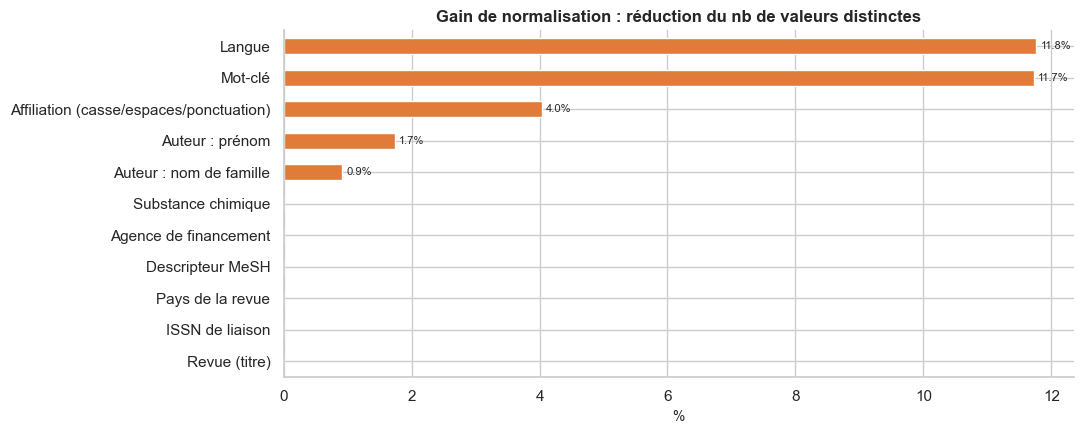

,valeurs_distinctes_brutes,après_normalisation,fusions,clés_à_graphies_multiples,gain_pct
entité,,,,,
Revue (titre),1071,1071,0,0,0.0
ISSN de liaison,1034,1034,0,0,0.0
Pays de la revue,52,52,0,0,0.0
Auteur : nom de famille,13984,13856,128,125,0.9
Auteur : prénom,12483,12266,217,212,1.7
Mot-clé,7164,6324,840,730,11.7
Descripteur MeSH,3924,3924,0,0,0.0
Affiliation (casse/espaces/ponctuation),9920,9520,400,354,4.0
Substance chimique,2583,2583,0,0,0.0


In [49]:
def fold(x):
    if not isinstance(x, str): return None
    x = "".join(c for c in unicodedata.normalize("NFKD", x.lower()) if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]+", " ", x).strip()

def gain(series, label, key=fold):
    raw = series.dropna().astype(str).str.strip(); k = raw.map(key)
    grp = pd.DataFrame({"raw": raw, "k": k}).groupby("k").raw.nunique()
    return dict(entité=label, valeurs_distinctes_brutes=raw.nunique(), après_normalisation=k.nunique(), fusions=raw.nunique() - k.nunique(), clés_à_graphies_multiples=int((grp > 1).sum()),
                gain_pct=100 * (1 - k.nunique() / max(raw.nunique(), 1)))
aff_key = lambda x: re.sub(r"\s+", " ", re.sub(r"(Electronic address|E-mail)\s*:.*$", "", x, flags=re.I)).strip().rstrip(".; ").lower()
var = pd.DataFrame([
    gain(art_dedup.revue, "Revue (titre)"), gain(art_dedup.issn_liaison, "ISSN de liaison"), gain(art_dedup.pays_revue, "Pays de la revue"),
    gain(au.nom, "Auteur : nom de famille"), gain(au.prenom, "Auteur : prénom"), gain(kw.mot_cle, "Mot-clé"), gain(ms.descripteur, "Descripteur MeSH"),
    gain(af.affiliation, "Affiliation (casse/espaces/ponctuation)", key=aff_key), gain(ch.substance, "Substance chimique"), gain(gr.agence, "Agence de financement"), gain(lg.langue, "Langue", key=lambda x: x.strip().lower()),
]).set_index("entité")
note("Variantes", "Revues à graphies multiples (même titre normalisé)", var.at["Revue (titre)", "clés_à_graphies_multiples"], var.at["Revue (titre)", "valeurs_distinctes_brutes"], "majeure", "Clé de dimension = NlmUniqueID (pas le titre)")
note("Variantes", "Mots-clés à graphies multiples", var.at["Mot-clé", "clés_à_graphies_multiples"], var.at["Mot-clé", "valeurs_distinctes_brutes"], "majeure", "Normaliser (trim, minuscule) avant création de Dim_MotCle")
note("Variantes", "Affiliations à graphies multiples", var.at["Affiliation (casse/espaces/ponctuation)", "clés_à_graphies_multiples"], var.at["Affiliation (casse/espaces/ponctuation)", "valeurs_distinctes_brutes"], "mineure", "Normaliser le texte ; géographie par extraction de pays")
export(var, "G_variantes_ecriture")
fig, ax = plt.subplots(figsize=(11, 4.5))
var.gain_pct.sort_values().plot.barh(color=C["accent"], ax=ax); show_bar_labels(ax, "{:.1f}%", horizontal=True); ax.set(title="Gain de normalisation : réduction du nb de valeurs distinctes", xlabel="%", ylabel="")
plt.tight_layout(); plt.show()
var.style.format({"gain_pct": "{:.1f}"}).bar(subset=["gain_pct"], color="#fad7a0", vmin=0, vmax=max(10, var.gain_pct.max()))

## G5. Valeurs extrêmes (outliers) sur les mesures de comptage

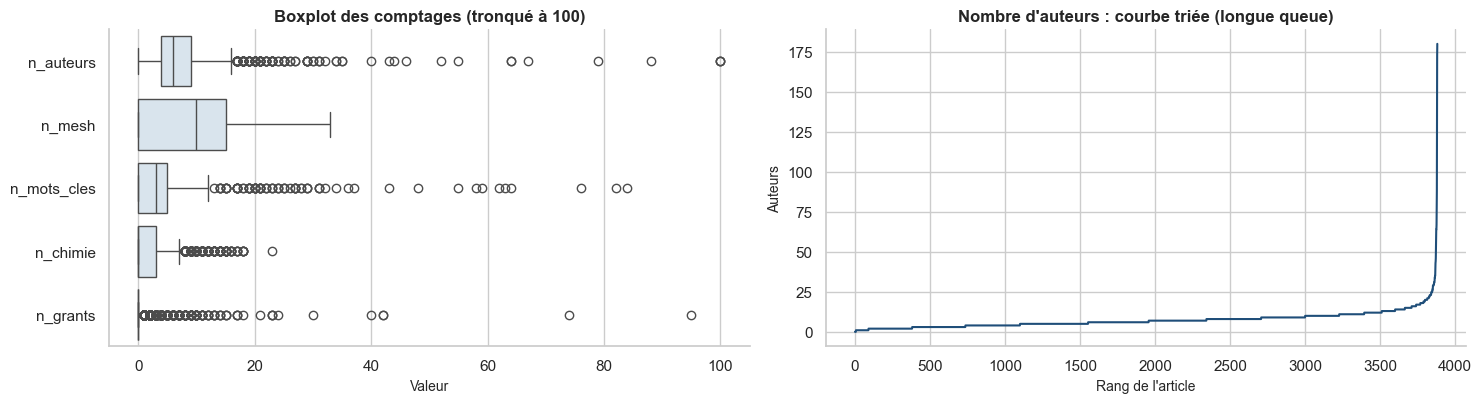

,mean,50%,95%,99%,max,seuil_outlier(Q3+3·IQR),nb_outliers,%_outliers
n_auteurs,7.4,6.0,15.0,25.0,180.0,24.0,40.0,1.0
n_aff_total,4.3,1.0,14.0,25.0,180.0,21.0,62.0,1.6
n_mots_cles,3.2,3.0,8.0,22.0,84.0,20.0,47.0,1.2
n_mesh,9.2,10.0,21.0,25.0,33.0,60.0,0.0,0.0
n_qualificatifs,6.0,5.0,18.0,23.2,38.0,40.0,0.0,0.0
n_chimie,2.1,0.0,9.0,13.2,23.0,12.0,52.0,1.3
n_grants,0.9,0.0,5.0,10.0,95.0,0.0,893.0,23.0
n_commentaires,12.7,0.0,54.0,103.2,576.0,88.0,55.0,1.4
n_types_pub,2.0,2.0,4.0,5.0,6.0,5.0,12.0,0.3
n_historique,5.3,6.0,7.0,8.0,8.0,16.0,0.0,0.0


In [50]:
numcols = ["n_auteurs", "n_aff_total", "n_mots_cles", "n_mesh", "n_qualificatifs", "n_chimie", "n_grants", "n_commentaires", "n_types_pub", "n_historique", "mots_titre", "mots_resume"]
q = art_ok[numcols].describe(percentiles=[.5, .95, .99]).T[["mean", "50%", "95%", "99%", "max"]]
Q1, Q3 = art_ok[numcols].quantile(.25), art_ok[numcols].quantile(.75)
q["seuil_outlier(Q3+3·IQR)"] = Q3 + 3 * (Q3 - Q1); q["nb_outliers"] = [(art_ok[c] > q.at[c, "seuil_outlier(Q3+3·IQR)"]).sum() for c in numcols]
q["%_outliers"] = 100 * q.nb_outliers / len(art_ok)
note("Valeurs extrêmes", "Articles à très grand nombre d'auteurs (> Q3+3·IQR)", q.at["n_auteurs", "nb_outliers"], len(art_ok), "mineure", "Conserver ; attention aux moyennes (utiliser la médiane)")
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
sns.boxplot(data=art_ok[["n_auteurs", "n_mesh", "n_mots_cles", "n_chimie", "n_grants"]].clip(upper=100), orient="h", color=C["light"], ax=ax[0]); ax[0].set(title="Boxplot des comptages (tronqué à 100)", xlabel="Valeur")
x = art_ok.n_auteurs.sort_values().reset_index(drop=True); ax[1].plot(x.values, color=C["main"]); ax[1].set(title="Nombre d'auteurs : courbe triée (longue queue)", xlabel="Rang de l'article", ylabel="Auteurs")
plt.tight_layout(); plt.show()
q.style.format("{:,.1f}")

---
# PARTIE H — Lecture « modélisation » : cardinalités, volumes, dépendances, thématique
*Ici on prépare la conception du Data Warehouse sans la figer.*

## H1. Le risque du double comptage — chiffré
Si l'on joint naïvement l'article à ses auteurs, mots-clés et descripteurs, **chaque publication est répétée** autant de fois qu'il y a de combinaisons. On quantifie cette inflation : c'est l'argument central du choix « 1 ligne de fait = 1 publication + sous-dimensions (relations N-N) ».

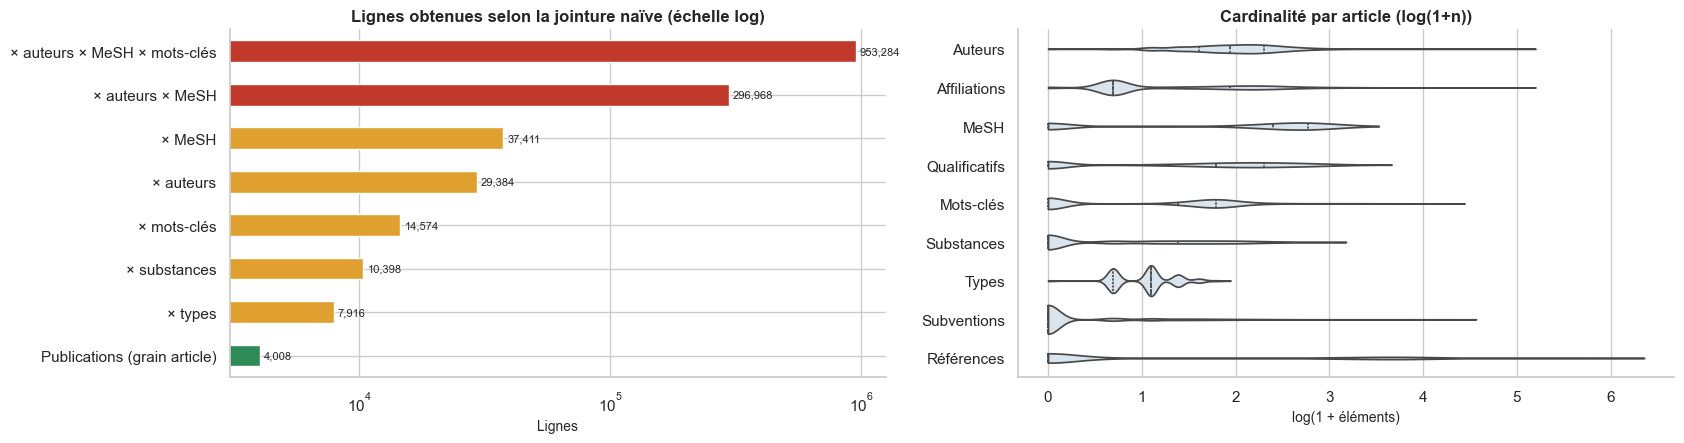

→ Un COUNT(*) sur la jointure article×auteur×MeSH×mot-clé annoncerait 953,284 « publications » au lieu de 4,008 (×238).


,lignes obtenues,facteur de gonflement
Publications (grain article),"4,008",1.0×
× auteurs,"29,384",7.3×
× MeSH,"37,411",9.3×
× mots-clés,"14,574",3.6×
× types,"7,916",2.0×
× substances,"10,398",2.6×
× auteurs × MeSH,"296,968",74.1×
× auteurs × MeSH × mots-clés,"953,284",237.8×


In [51]:
A_ = art_dedup
atoms = {"auteurs": A_.n_auteurs, "MeSH": A_.n_mesh, "mots-clés": A_.n_mots_cles, "types": A_.n_types_pub, "substances": A_.n_chimie}
infl = {"Publications (grain article)": len(A_)}
for k, v in atoms.items(): infl[f"× {k}"] = int(v.clip(lower=1).sum())
infl["× auteurs × MeSH"] = int((atoms["auteurs"].clip(lower=1) * atoms["MeSH"].clip(lower=1)).sum())
infl["× auteurs × MeSH × mots-clés"] = int((atoms["auteurs"].clip(lower=1) * atoms["MeSH"].clip(lower=1) * atoms["mots-clés"].clip(lower=1)).sum())
inf = pd.Series(infl); inf_df = pd.DataFrame({"lignes obtenues": inf, "facteur de gonflement": inf / len(A_)})
fig, ax = plt.subplots(1, 2, figsize=(17, 4.6))
inf.sort_values().plot.barh(color=[C["ok"] if i.startswith("Publications") else C["warn"] if i.count("×") == 1 else C["bad"] for i in inf.sort_values().index], ax=ax[0]); show_bar_labels(ax[0], horizontal=True); ax[0].set_xscale("log")
ax[0].set(title="Lignes obtenues selon la jointure naïve (échelle log)", xlabel="Lignes", ylabel="")
card = pd.DataFrame({"Auteurs": A_.n_auteurs, "Affiliations": A_.n_aff_total, "MeSH": A_.n_mesh, "Qualificatifs": A_.n_qualificatifs, "Mots-clés": A_.n_mots_cles, "Substances": A_.n_chimie, "Types": A_.n_types_pub, "Subventions": A_.n_grants, "Références": A_.n_commentaires})
sns.violinplot(data=np.log1p(card), orient="h", color=C["light"], inner="quartile", cut=0, ax=ax[1]); ax[1].set(title="Cardinalité par article (log(1+n))", xlabel="log(1 + éléments)")
plt.tight_layout(); plt.show()
print(f"→ Un COUNT(*) sur la jointure article×auteur×MeSH×mot-clé annoncerait {inf.iloc[-1]:,.0f} « publications » au lieu de {len(A_):,} (×{inf.iloc[-1]/len(A_):,.0f}).")
inf_df.style.format({"lignes obtenues": "{:,.0f}", "facteur de gonflement": "{:.1f}×"})

Conclusion : Une publication peut être liée à plusieurs auteurs, mots-clés, MeSH, etc. Si on joint toutes ces tables directement, on multiplie les lignes artificiellement : on obtient 953 284 lignes au lieu de 4 008 publications, soit un gonflement ×238.

À quoi ça va servir pour les prochaines étapes ?
1. Conception du Data Warehouse : définir le grain de Fact_Publication : une ligne = une publication.
2. Modélisation : créer des tables de liaison pour gérer les relations plusieurs-à-plusieurs (publications ↔ auteurs, MeSH, mots-clés…).
3. Requêtes et analyses : éviter le double comptage et obtenir des indicateurs fiables, sans gonfler artificiellement le nombre de publications.

À retenir : cette analyse justifie les choix de modélisation de ton Data Warehouse et permet de garantir la fiabilité des statistiques.

## H2. Volumes prévisionnels : dimensions candidates et sous-dimensions
Estimation de la taille de chaque futur objet du Data Warehouse (sur articles dédoublonnés).

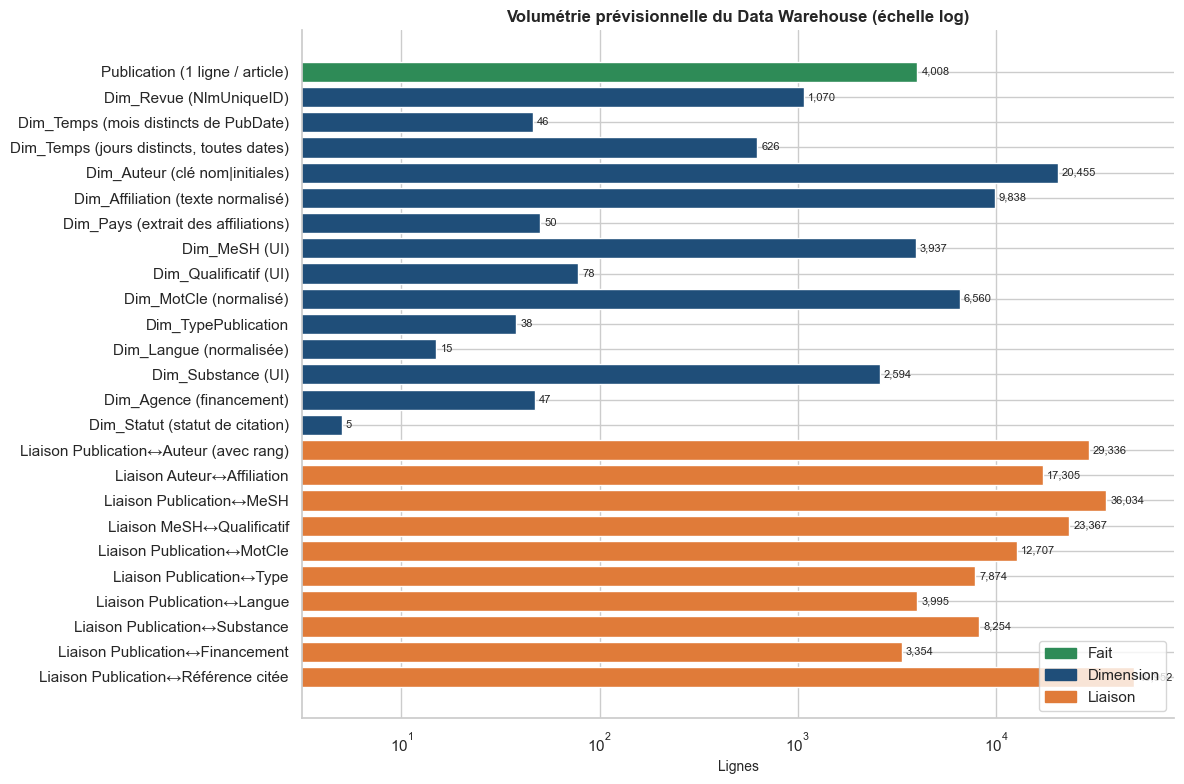

nature,objet,lignes,ratio_vs_publications
Fait,Publication (1 ligne / article),"4,008",1.00
Dimension,Dim_Revue (NlmUniqueID),"1,070",0.27
Dimension,Dim_Temps (mois distincts de PubDate),46,0.01
Dimension,"Dim_Temps (jours distincts, toutes dates)",626,0.16
Dimension,Dim_Auteur (clé nom|initiales),"20,455",5.10
Dimension,Dim_Affiliation (texte normalisé),"9,838",2.45
Dimension,Dim_Pays (extrait des affiliations),50,0.01
Dimension,Dim_MeSH (UI),"3,937",0.98
Dimension,Dim_Qualificatif (UI),78,0.02
Dimension,Dim_MotCle (normalisé),"6,560",1.64


In [62]:
K = lambda df: only_keep(df)
vol = pd.DataFrame([
    ("Fait", "Publication (1 ligne / article)", len(A_)),
    ("Dimension", "Dim_Revue (NlmUniqueID)", A_.nlm_id.nunique()), ("Dimension", "Dim_Temps (mois distincts de PubDate)", A_.pub_dt.dt.to_period("M").nunique()),
    ("Dimension", "Dim_Temps (jours distincts, toutes dates)", pd.concat([A_.cree_dt, A_.pub_dt]).nunique()),
    ("Dimension", "Dim_Auteur (clé nom|initiales)", (K(auteurs).assign(c=lambda d: d.nom.fillna("").str.lower() + "|" + d.initiales.fillna("")).c.nunique())),
    ("Dimension", "Dim_Affiliation (texte normalisé)", K(affils).affiliation.map(aff_key).nunique()), ("Dimension", "Dim_Pays (extrait des affiliations)", K(affils).affiliation.map(extract_country).nunique()),
    ("Dimension", "Dim_MeSH (UI)", K(mesh).ui.nunique()), ("Dimension", "Dim_Qualificatif (UI)", K(mesh_qual).ui.nunique()), ("Dimension", "Dim_MotCle (normalisé)", K(mots_cles).mot_cle.str.strip().str.lower().nunique()),
    ("Dimension", "Dim_TypePublication", K(types_pub).type.nunique()), ("Dimension", "Dim_Langue (normalisée)", K(langues).langue.str.lower().nunique()),
    ("Dimension", "Dim_Substance (UI)", K(chimie).ui.nunique()), ("Dimension", "Dim_Agence (financement)", K(grants).agence.nunique()),
    ("Dimension", "Dim_Statut (statut de citation)", A_.statut.nunique()),
    ("Liaison", "Liaison Publication↔Auteur (avec rang)", len(K(auteurs))), ("Liaison", "Liaison Auteur↔Affiliation", len(K(affils))), ("Liaison", "Liaison Publication↔MeSH", len(K(mesh))),
    ("Liaison", "Liaison MeSH↔Qualificatif", len(K(mesh_qual))), ("Liaison", "Liaison Publication↔MotCle", len(K(mots_cles))), ("Liaison", "Liaison Publication↔Type", len(K(types_pub))),
    ("Liaison", "Liaison Publication↔Langue", len(K(langues))), ("Liaison", "Liaison Publication↔Substance", len(K(chimie))), ("Liaison", "Liaison Publication↔Financement", len(K(grants))),
    ("Liaison", "Liaison Publication↔Référence citée", len(K(commentaires))),
], columns=["nature", "objet", "lignes"])
vol["ratio_vs_publications"] = vol.lignes / len(A_)
fig, ax = plt.subplots(figsize=(12, 8))
vv = vol.iloc[::-1]
ax.barh(vv.objet, vv.lignes, color=vv.nature.map({"Fait": C["ok"], "Dimension": C["main"], "Liaison": C["accent"]})); ax.set_xscale("log"); show_bar_labels(ax, horizontal=True)
ax.set(title="Volumétrie prévisionnelle du Data Warehouse (échelle log)", xlabel="Lignes")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=C["ok"], label="Fait"), Patch(color=C["main"], label="Dimension"), Patch(color=C["accent"], label="Liaison")], loc="lower right"); plt.tight_layout(); plt.show()
export(vol.set_index("objet"), "H_volumetrie_previsionnelle")
vol.style.format({"lignes": "{:,}", "ratio_vs_publications": "{:.2f}"}).hide(axis="index")

## H3. Dépendances fonctionnelles (DF) : quels attributs sont rattachables à quelle clé ?
Une DF `X → Y` signifie « chaque valeur de X détermine une seule valeur de Y ». C'est **ce qui autorise** à ranger `Y` comme attribut d'une dimension dont la clé est `X` (et à éviter les incohérences). On teste les DF candidates sur les données.

ce code vérifie les dépendances fonctionnelles entre les attributs d'une mm table(dimension) pour choisir des clés fiables(clés primaires) et construire correctement les dimensions du Data Warehouse.

In [53]:
def fd(df, X, Y, label=None):
    d = df[[X, Y]].dropna(); g_ = d.groupby(X)[Y].nunique(); viol = g_[g_ > 1]
    ex = d[d[X].isin(viol.index[:1])].drop_duplicates().head(3)[Y].astype(str).str[:35].tolist() if len(viol) else []
    return dict(DF=label or f"{X} → {Y}", déterminants=int(g_.shape[0]), violations=int(len(viol)), pct_violation=100 * len(viol) / max(g_.shape[0], 1),
                verdict="✅ DF valide" if len(viol) == 0 else ("⚠️ quasi-valide" if len(viol) / max(g_.shape[0], 1) < .02 else "❌ non valide"), exemple=" | ".join(ex))
J = A_.copy()
J["mois_pub"] = J.pub_dt.dt.to_period("M").astype(str)
fds = pd.DataFrame([
    fd(J, "nlm_id", "revue", "NlmUniqueID → Titre de la revue"), fd(J, "nlm_id", "issn_liaison", "NlmUniqueID → ISSN de liaison"), fd(J, "nlm_id", "pays_revue", "NlmUniqueID → Pays de la revue"),
    fd(J, "nlm_id", "medline_ta", "NlmUniqueID → Abréviation MedlineTA"), fd(J, "issn_liaison", "nlm_id", "ISSN de liaison → NlmUniqueID"), fd(J, "issn", "nlm_id", "ISSN → NlmUniqueID"),
    fd(J, "revue", "nlm_id", "Titre de la revue → NlmUniqueID"), fd(J, "revue", "pays_revue", "Titre de la revue → Pays"), fd(J, "medline_ta", "nlm_id", "MedlineTA → NlmUniqueID"),
    fd(K(mesh), "ui", "descripteur", "MeSH UI → Descripteur"), fd(K(mesh), "descripteur", "ui", "Descripteur → MeSH UI"), fd(K(chimie), "ui", "substance", "Substance UI → Nom"),
    fd(K(chimie), "substance", "registre", "Substance → N° de registre"), fd(K(mesh_qual), "ui", "qualificatif", "Qualificatif UI → Libellé"),
    fd(K(types_pub), "ui", "type", "Type UI → Libellé du type"), fd(K(grants), "agence", "pays", "Agence → Pays du financeur"),
]).set_index("DF")
export(fds, "H_dependances_fonctionnelles")
print("Lecture : une DF valide justifie un attribut de dimension ; une DF violée interdit de choisir X comme clé naturelle (ex. le titre de revue).")
fds.style.format({"pct_violation": "{:.2f}"})

Lecture : une DF valide justifie un attribut de dimension ; une DF violée interdit de choisir X comme clé naturelle (ex. le titre de revue).


,déterminants,violations,pct_violation,verdict,exemple
DF,,,,,
NlmUniqueID → Titre de la revue,1070,1,0.09,⚠️ quasi-valide,Actas urologicas espan~olas | Actas urologicas espanolas
NlmUniqueID → ISSN de liaison,1034,0,0.00,✅ DF valide,
NlmUniqueID → Pays de la revue,1018,2,0.20,⚠️ quasi-valide,United States | England
NlmUniqueID → Abréviation MedlineTA,1070,0,0.00,✅ DF valide,
ISSN de liaison → NlmUniqueID,1034,0,0.00,✅ DF valide,
ISSN → NlmUniqueID,1071,0,0.00,✅ DF valide,
Titre de la revue → NlmUniqueID,1071,0,0.00,✅ DF valide,
Titre de la revue → Pays,1018,2,0.20,⚠️ quasi-valide,United States | England
MedlineTA → NlmUniqueID,1070,0,0.00,✅ DF valide,


In [54]:
bad_j = fd(J, "revue", "nlm_id")["violations"]; bad_id = fd(J, "nlm_id", "revue")["violations"]
print(f"Revue : titres reliés à plusieurs NlmUniqueID = {bad_j} · NlmUniqueID portant plusieurs variantes de titre = {bad_id} → clé naturelle recommandée : NlmUniqueID (le titre reste un attribut).")
manq_pays = J.pays_revue.isna(); recup = J[manq_pays].nlm_id.isin(J[J.pays_revue.notna()].nlm_id)
print(f"Pays de revue manquant : {int(manq_pays.sum())} articles dont {int(recup.sum())} ({pct(recup.sum(), manq_pays.sum())} %) RÉCUPÉRABLES grâce à la DF NlmUniqueID → Pays (autre article de la même revue).")
viol_ex = []
for X, Y, TB in [("ui", "descripteur", mesh), ("ui", "type", types_pub)]:
    d_ = only_keep(TB)[[X, Y]].dropna().drop_duplicates(); v_ = d_.groupby(X)[Y].nunique(); viol_ex.append(d_[d_[X].isin(v_[v_ > 1].index)].assign(df=f"{X}→{Y}"))
print("Violations de DF détaillées (texte altéré ou casse différente) :"); display(pd.concat(viol_ex))
ex = J.groupby("nlm_id").revue.nunique(); ex = ex[ex > 1].index[:3]
J[J.nlm_id.isin(ex)][["nlm_id", "revue", "issn", "issn_liaison", "pays_revue"]].drop_duplicates().sort_values("nlm_id").head(8)

Revue : titres reliés à plusieurs NlmUniqueID = 0 · NlmUniqueID portant plusieurs variantes de titre = 1 → clé naturelle recommandée : NlmUniqueID (le titre reste un attribut).
Pays de revue manquant : 239 articles dont 106 (44.4 %) RÉCUPÉRABLES grâce à la DF NlmUniqueID → Pays (autre article de la même revue).
Violations de DF détaillées (texte altéré ou casse différente) :


,ui,descripteur,df,type
398,D020022,Genetic Predisposition to Disease,ui→descripteur,NaN
28336,D020022,Genetic Predisposition to Dise the American College of Medical Genetics,ui→descripteur,NaN
6,,NaN,ui→type,JOURNAL ARTICLE
161,,NaN,ui→type,REVIEW


,nlm_id,revue,issn,issn_liaison,pays_revue
3558,7704993,Actas urologicas espan~olas,1699-7980,0210-4806,Spain
705,7704993,Actas urologicas espanolas,1699-7980,0210-4806,None


## H4. Que contient le corpus ? Thématique, temporalité, co-occurrences
Dernière lecture « métier » avant de fixer le **sujet d'analyse** : de quoi parlent ces articles ?

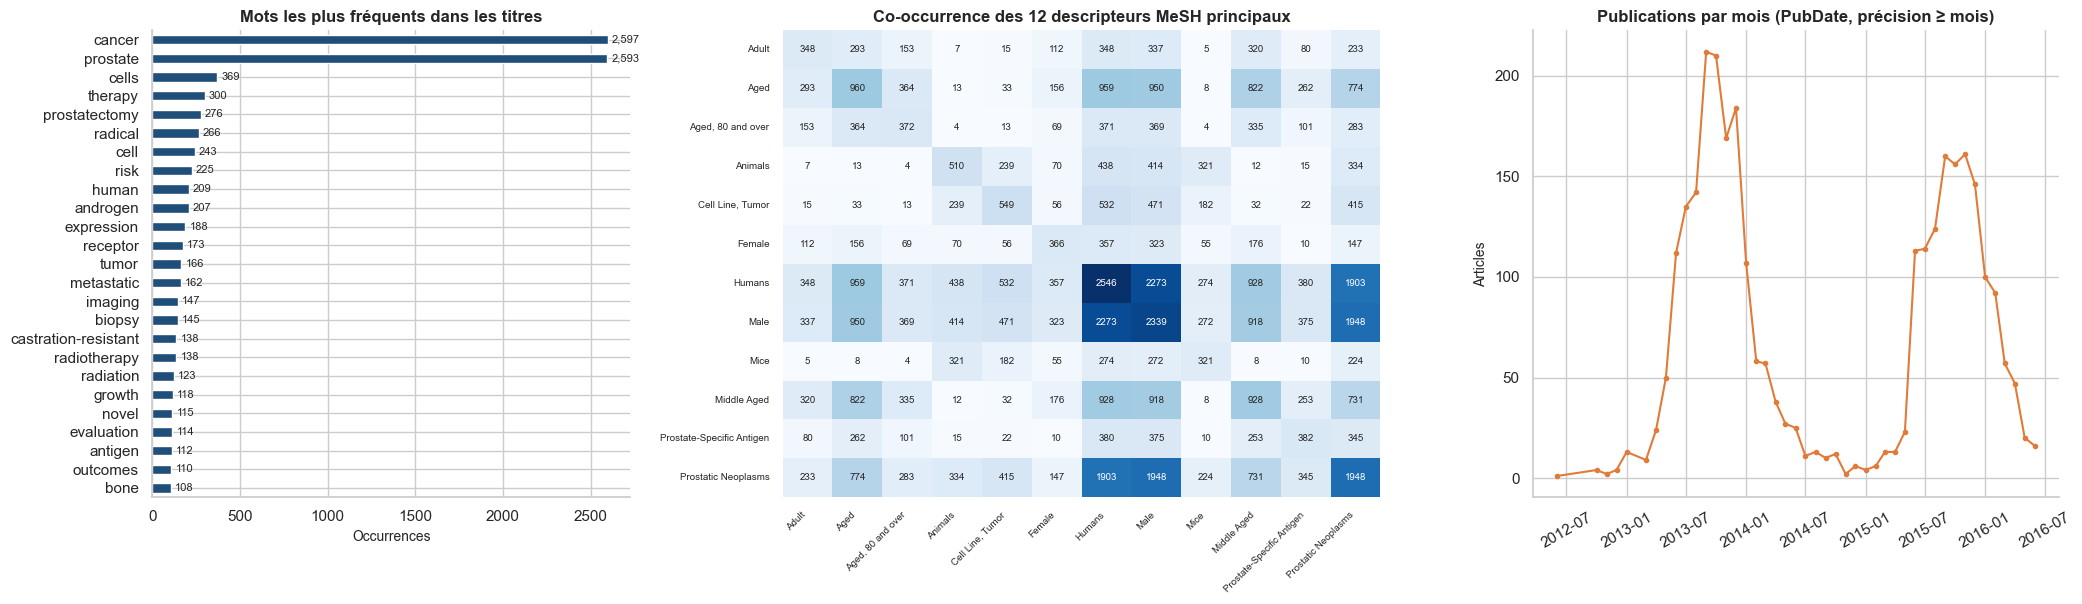

Mots dominants des titres : cancer, prostate, cells, therapy, prostatectomy, radical, cell, risk, human, androgen


In [55]:
STOP = set("with from that this their were have been into after between among which using during patients patient study studies based cancer analysis effect effects role treatment review case clinical results new versus than also over under high low".split()) - {"cancer"}
STOP |= set("with from that this their were have been into after between among which using during than also over under versus".split())
words = A_.titre.dropna().str.lower().str.findall(r"[a-z][a-z\-]{3,}").explode()
words = words[~words.isin(STOP)].value_counts().head(25)
top12 = K(mesh).groupby("descripteur").art_id.nunique().sort_values(ascending=False).head(12).index
Mx = pd.crosstab(K(mesh)[K(mesh).descripteur.isin(top12)].art_id, K(mesh)[K(mesh).descripteur.isin(top12)].descripteur); co = Mx.T.dot(Mx)
fig, ax = plt.subplots(1, 3, figsize=(21, 6.2), gridspec_kw={"width_ratios": [1, 1.25, 1.1]})
words.sort_values().plot.barh(color=C["main"], ax=ax[0]); show_bar_labels(ax[0], horizontal=True); ax[0].set(title="Mots les plus fréquents dans les titres", xlabel="Occurrences", ylabel="")
sns.heatmap(co, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 7}, ax=ax[1]); ax[1].set(title="Co-occurrence des 12 descripteurs MeSH principaux", xlabel="", ylabel="")
plt.setp(ax[1].get_xticklabels(), rotation=45, ha="right", fontsize=7); plt.setp(ax[1].get_yticklabels(), fontsize=7)
mm = A_[A_.pub_precision.isin(["Année+Mois", "Année+Mois+Jour"])].groupby(A_.pub_dt.dt.to_period("M")).size(); mm.index = mm.index.to_timestamp()
ax[2].plot(mm.index, mm.values, color=C["accent"], marker="o", ms=3); ax[2].set(title="Publications par mois (PubDate, précision ≥ mois)", xlabel="", ylabel="Articles"); plt.setp(ax[2].get_xticklabels(), rotation=30)
plt.tight_layout(); plt.show()
print("Mots dominants des titres :", ", ".join(words.head(10).index))

---
# PARTIE I — Synthèse et aide à la décision
## I1. Scorecard qualité (6 dimensions, 0–100)

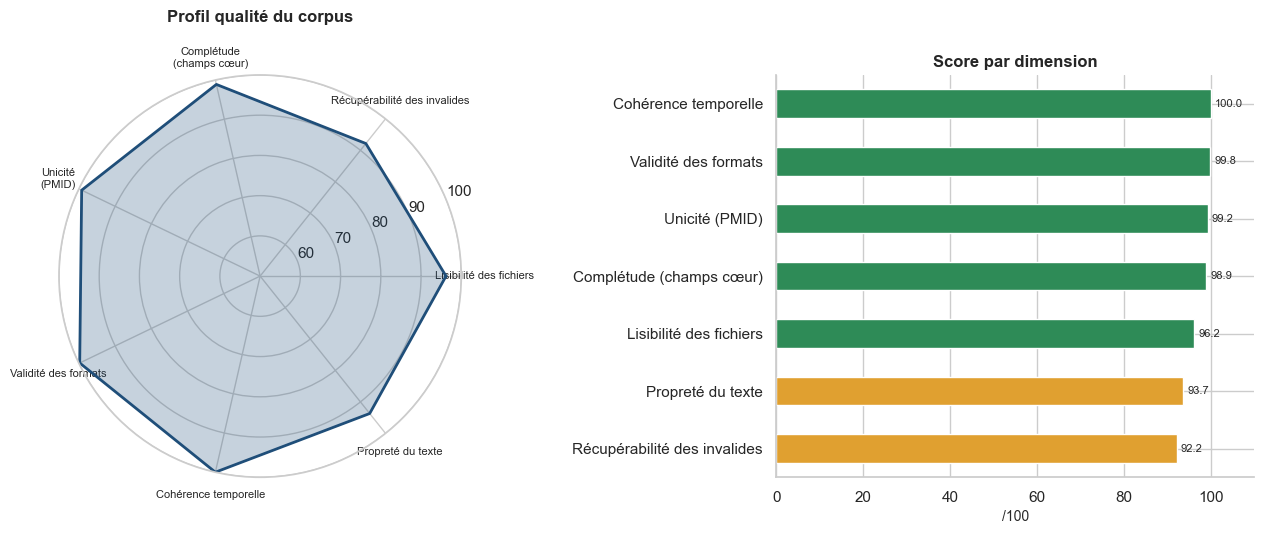

Score global moyen : 97.1 / 100


In [56]:
anyflag = np.mean([pd.concat([fn(v.dropna().astype(str)) for fn in FLAGS.values()], axis=1).any(axis=1).mean() for v in TEXT.values()])
score_dims = pd.Series({
    "Lisibilité des fichiers": 100 * (files.statut == "valide").mean(),
    "Récupérabilité des invalides": 100 * (inv.niveau != "L3 irrécupérable (XML)").mean(),
    "Complétude (champs cœur)": art_ok.score_completude.mean(),
    "Unicité (PMID)": 100 * (1 - (len(art) - len(art_dedup)) / len(art)),
    "Validité des formats": 100 * (1 - rules.violations.sum() / rules.contrôlés.sum()),
    "Cohérence temporelle": 100 * (1 - tr_rules[tr_rules.gravité == "majeure"].violations.sum() / max(tr_rules[tr_rules.gravité == "majeure"].contrôlés.sum(), 1)),
    "Propreté du texte": 100 * (1 - anyflag),
})
ang = np.linspace(0, 2 * np.pi, len(score_dims), endpoint=False).tolist(); vals = score_dims.tolist()
fig = plt.figure(figsize=(13, 5.5)); ax = fig.add_subplot(121, polar=True)
ax.plot(ang + ang[:1], vals + vals[:1], color=C["main"], lw=2); ax.fill(ang + ang[:1], vals + vals[:1], color=C["main"], alpha=.25)
ax.set_xticks(ang); ax.set_xticklabels([l.replace(" (", "\n(") for l in score_dims.index], fontsize=8); ax.set_ylim(50, 100); ax.set_title("Profil qualité du corpus", pad=18)
ax2 = fig.add_subplot(122); score_dims.sort_values().plot.barh(color=[C["ok"] if v >= 95 else C["warn"] if v >= 85 else C["bad"] for v in score_dims.sort_values()], ax=ax2); show_bar_labels(ax2, "{:.1f}", horizontal=True)
ax2.set(xlim=(0, 110), title="Score par dimension", xlabel="/100"); plt.tight_layout(); plt.show()
print(f"Score global moyen : {score_dims.mean():.1f} / 100")

## I2. Registre des anomalies (→ livrable L03 « Règles de nettoyage »)

In [57]:
anom = pd.DataFrame(ANOM)
extra = [
    ("Fichiers", "Fichiers XML invalides (parsing strict)", int((files.statut == "invalide").sum()), len(files), "critique", "Échelle de réparation L1→L3 ; journaliser dans etl_logs"),
    ("Fichiers", "Fichiers irrécupérables par XML", int((files.niveau == "L3 irrécupérable (XML)").sum()), len(files), "critique", "Écarter, tracer le PMID (regex) pour réconciliation"),
    ("Unicité", "PMID dupliqués (copies identiques)", len(art) - art.pmid.nunique() - int(art.pmid.isna().sum()), len(art), "majeure", "Dédoublonnage déterministe (règle F1)"),
    ("Complétude", "Notices réparées sans PMID lisible", int(art.pmid.isna().sum()), len(art), "majeure", "Rattachement titre/DOI ou mise à l'écart"),
    ("Texte", "Libellé MeSH altéré (même UI, texte différent : ex. « …Dise the American College… »)", int(fds.loc["MeSH UI → Descripteur", "violations"]), int(fds.loc["MeSH UI → Descripteur", "déterminants"]), "majeure", "Référentiel : garder le libellé le plus fréquent par UI"),
    ("Variantes", "Libellés de types de publication à casse différente (JOURNAL ARTICLE / Journal Article)", int(K(types_pub).type.str.lower().map(K(types_pub).groupby(K(types_pub).type.str.lower()).type.nunique()).gt(1).sum()), len(K(types_pub)), "majeure", "Normaliser par UI du type (D016428…)"),
    ("Structure", "Enregistrements <PubmedBookArticle> (hors modèle article)", int(len(livres)), len(art), "mineure", "Écarter ou table dédiée"),
]
anom = pd.concat([anom, pd.DataFrame([dict(domaine=a, anomalie=b, volume=c, base=d, pct=100 * c / max(d, 1), gravité=e, traitement_proposé=f) for a, b, c, d, e, f in extra])], ignore_index=True)
ordre = {"critique": 0, "majeure": 1, "mineure": 2}; anom = anom.sort_values(["gravité", "pct"], key=lambda s: s.map(ordre) if s.name == "gravité" else -s).reset_index(drop=True)
anom.index = [f"A{i+1:02d}" for i in range(len(anom))]; export(anom, "I_registre_anomalies")
print(f"{len(anom)} anomalies documentées : {anom.gravité.value_counts().to_dict()}")
(anom.style.format({"pct": "{:.2f}", "volume": "{:,}", "base": "{:,}"}).bar(subset=["pct"], color="#f5b7b1", vmin=0, vmax=30)
     .map(lambda v: {"critique": "background-color:#f5b7b1", "majeure": "background-color:#fad7a0", "mineure": "background-color:#e5e8e8"}.get(v, ""), subset=["gravité"]))

31 anomalies documentées : {'mineure': 17, 'majeure': 12, 'critique': 2}


,domaine,anomalie,volume,base,pct,gravité,traitement_proposé
A01,Fichiers,Fichiers XML invalides (parsing strict),153,"4,036",3.79,critique,Échelle de réparation L1→L3 ; journaliser dans etl_logs
A02,Fichiers,Fichiers irrécupérables par XML,12,"4,036",0.30,critique,"Écarter, tracer le PMID (regex) pour réconciliation"
A03,Variantes,Libellés de types de publication à casse différente (JOURNAL ARTICLE / Journal Article),"4,464","7,874",56.69,majeure,Normaliser par UI du type (D016428…)
A04,Variantes,Mots-clés à graphies multiples,730,"7,164",10.19,majeure,"Normaliser (trim, minuscule) avant création de Dim_MotCle"
A05,Format,Langue (3 lettres minuscules) au format invalide,194,"3,912",4.96,majeure,Mettre en minuscules + trim
A06,Complétude,Notices réparées sans PMID lisible,41,"4,039",1.02,majeure,Rattachement titre/DOI ou mise à l'écart
A07,Unicité,PMID dupliqués (copies identiques),31,"4,039",0.77,majeure,Dédoublonnage déterministe (règle F1)
A08,Texte,art.resume : entité HTML,6,"3,872",0.15,majeure,Décoder (html.unescape)
A09,Format,DOI (10.xxxx/…) au format invalide,4,"3,522",0.11,majeure,"Mettre à NULL, conserver la valeur brute en staging"
A10,Texte,affils.affiliation : entité HTML,7,"16,700",0.04,majeure,Décoder (html.unescape)


## I3. Faisabilité des axes d'analyse (calculée sur les données)
🟢 solide · 🟠 exploitable avec précautions · 🔴 insuffisant. Le verdict combine **couverture**, **cardinalité** et **fiabilité**.

In [58]:
nA = len(art_dedup); cov = lambda mask: 100 * mask.mean()
ax_rows = [
    ("Évolution temporelle", "PubDate (année/mois), DateCreated", cov(art_dedup.pub_annee_eff.notna()), f"{art_dedup.pub_annee_eff.nunique()} années, {art_dedup.pub_dt.dt.to_period('M').nunique()} mois", "Fenêtre courte et en « dents de scie » : exploiter le mois ; préciser le rôle de chaque date"),
    ("Revues", "NlmUniqueID, titre, ISSN, pays", cov(art_dedup.nlm_id.notna()), f"{art_dedup.nlm_id.nunique():,} revues", "Clé NlmUniqueID fiable ; pays = pays de l'éditeur ; 54 % des revues n'ont qu'1 article"),
    ("Thématiques MeSH", "MeshHeadingList + qualificatifs", cov(art_dedup.n_mesh > 0), f"{K(mesh).ui.nunique():,} descripteurs", "Vocabulaire contrôlé, UI propres ; absence structurelle liée au statut (non indexé)"),
    ("Mots-clés", "KeywordList", cov(art_dedup.n_mots_cles > 0), f"{K(mots_cles).mot_cle.str.lower().nunique():,} mots-clés", "Vocabulaire libre, très creux (≈ 80 % d'occurrences uniques) : analyse secondaire"),
    ("Types de publication", "PublicationTypeList", cov(art_dedup.n_types_pub > 0), f"{K(types_pub).type.nunique()} types", "Multivalué (N-N) ; « Journal Article » domine"),
    ("Auteurs", "AuthorList (nom, initiales)", cov(art_dedup.n_auteurs > 0), f"{K(auteurs).nom.nunique():,} noms", "Pas d'identifiant (ORCID < 1 %) : homonymes ; usage = volumétrie & nb d'auteurs/article, pas identification"),
    ("Collaborations / affiliations", "AffiliationInfo", cov(art_dedup.n_auteurs_avec_aff > 0), f"{K(affils).affiliation.map(aff_key).nunique():,} institutions (texte)", "Texte libre ; ~54 % des auteurs affiliés ; pays extractible à ~76 % (règles à documenter)"),
    ("Langues", "Language", cov(art_dedup.n_langues > 0), f"{K(langues).langue.str.lower().nunique()} langues", "Très déséquilibrée (anglais dominant) : peu discriminante"),
    ("Financements", "GrantList", cov(art_dedup.n_grants > 0), f"{K(grants).agence.nunique()} agences", "Couverture faible : axe optionnel"),
    ("Substances chimiques", "ChemicalList", cov(art_dedup.n_chimie > 0), f"{K(chimie).ui.nunique():,} substances", "Absence liée à l'indexation MeSH ; complément thématique"),
    ("Citations / références", "CommentsCorrections", cov(art_dedup.n_commentaires > 0), f"{len(K(commentaires)):,} liens", "Graphe de citations : hors périmètre minimal, très volumineux"),
]
feas = pd.DataFrame(ax_rows, columns=["axe", "source XML", "couverture_%", "cardinalité", "remarque"])
feas["verdict"] = np.where(feas["couverture_%"] >= 90, "🟢", np.where(feas["couverture_%"] >= 50, "🟠", "🔴"))
feas.loc[feas.axe.isin(["Auteurs", "Langues"]), "verdict"] = "🟠"; feas.loc[feas.axe == "Collaborations / affiliations", "verdict"] = "🟠"
export(feas.set_index("axe"), "I_faisabilite_axes")
feas.set_index("axe").style.bar(subset=["couverture_%"], color="#bfe3c9", vmin=0, vmax=100).format({"couverture_%": "{:.1f}"})

,source XML,couverture_%,cardinalité,remarque,verdict
axe,,,,,
Évolution temporelle,"PubDate (année/mois), DateCreated",99.0,"5 années, 46 mois",Fenêtre courte et en « dents de scie » : exploiter le mois ; préciser le rôle de chaque date,🟢
Revues,"NlmUniqueID, titre, ISSN, pays",99.0,"1,070 revues",Clé NlmUniqueID fiable ; pays = pays de l'éditeur ; 54 % des revues n'ont qu'1 article,🟢
Thématiques MeSH,MeshHeadingList + qualificatifs,65.6,"3,937 descripteurs","Vocabulaire contrôlé, UI propres ; absence structurelle liée au statut (non indexé)",🟠
Mots-clés,KeywordList,53.4,"6,560 mots-clés","Vocabulaire libre, très creux (≈ 80 % d'occurrences uniques) : analyse secondaire",🟠
Types de publication,PublicationTypeList,99.0,38 types,Multivalué (N-N) ; « Journal Article » domine,🟢
Auteurs,"AuthorList (nom, initiales)",98.8,"14,202 noms","Pas d'identifiant (ORCID < 1 %) : homonymes ; usage = volumétrie & nb d'auteurs/article, pas identification",🟠
Collaborations / affiliations,AffiliationInfo,96.4,"9,838 institutions (texte)",Texte libre ; ~54 % des auteurs affiliés ; pays extractible à ~76 % (règles à documenter),🟠
Langues,Language,99.0,15 langues,Très déséquilibrée (anglais dominant) : peu discriminante,🟠
Financements,GrantList,22.7,47 agences,Couverture faible : axe optionnel,🔴


## I4. Matrice de décision **colonne par colonne** (proposition provisoire — à valider ensemble)
Règles automatiques (constante → écarter ; > 80 % manquant → écarter/arbitrer) + affectation sémantique. **Rien n'est supprimé** : cette matrice prépare l'étape « choix des colonnes ».

In [59]:
DEST = {  # colonne -> (destination probable, décision)
    "pmid": ("Fait : clé métier", "Conserver"), "titre": ("Fait : attribut texte", "Conserver"), "resume": ("Fait : attribut texte (ou écarter si pas d'analyse texte)", "À arbitrer"),
    "revue": ("Dim_Revue", "Conserver"), "nlm_id": ("Dim_Revue : clé naturelle", "Conserver"), "issn": ("Dim_Revue", "Conserver"), "issn_liaison": ("Dim_Revue", "Conserver"),
    "pays_revue": ("Dim_Revue", "Conserver (imputer via NlmUniqueID)"), "medline_ta": ("Dim_Revue : abréviation", "Conserver"), "revue_abrev_iso": ("Dim_Revue", "À arbitrer"),
    "support": ("Dim_Revue/Fait", "À arbitrer"), "volume": ("Fait : attribut", "À arbitrer"), "numero": ("Fait : attribut", "À arbitrer"), "pagination": ("Fait : attribut", "À arbitrer"),
    "pub_annee_eff": ("Dim_Temps", "Conserver"), "pub_dt": ("Dim_Temps", "Conserver"), "pub_precision": ("Dim_Temps : niveau de précision", "Conserver"), "cree_dt": ("Dim_Temps (rôle : création notice)", "À arbitrer"),
    "complete_dt": ("Dim_Temps (rôle)", "À arbitrer"), "revise_dt": ("Dim_Temps (rôle)", "À arbitrer"), "art_dt": ("Dim_Temps (rôle : mise en ligne)", "À arbitrer"),
    "statut": ("Dim_Statut", "Conserver"), "pub_model": ("Dim_Statut / attribut", "À arbitrer"), "statut_pub": ("Attribut", "À arbitrer"), "sous_ensembles": ("Sous-dimension/attribut", "À arbitrer"),
    "doi": ("Fait : identifiant externe", "Conserver"), "pmc": ("Fait : identifiant externe", "À arbitrer"), "pii": ("Technique", "Écarter"), "mid": ("Technique", "Écarter"), "id_pubmed_article": ("Redondant avec PMID", "Écarter"),
    "n_auteurs": ("Fait : mesure dérivée", "Conserver"), "n_mesh": ("Fait : mesure dérivée", "À arbitrer"), "n_mots_cles": ("Fait : mesure dérivée", "À arbitrer"),
    "art_id": ("Technique : clé de jointure staging", "Technique"), "fichier": ("Technique : traçabilité", "Technique"), "niveau_parse": ("Technique : traçabilité", "Technique"), "hash_contenu": ("Technique : détection de changement", "Technique"),
}
mat = prof_art[["groupe", "type", "manquants_pct", "distincts"]].copy()
def decide(c, r):
    if c in DEST: return DEST[c]
    if r.distincts <= 1: return ("—", "Écarter (constante)")
    if r.manquants_pct >= 80: return ("—", "Écarter ou à arbitrer (très creuse)")
    if c.endswith(("_a", "_m", "_j")) or c in ("pub_annee", "pub_mois", "pub_jour", "pub_saison", "pub_medline_date"): return ("Brut : absorbé par Dim_Temps", "Technique (staging seulement)")
    if c.startswith("n_") or c.startswith("resume_") or c.startswith("longueur") or c.startswith("mots_"): return ("Mesure dérivée / indicateur de qualité", "À arbitrer")
    return ("—", "À arbitrer")
mat[["destination", "décision"]] = [decide(c, r) for c, r in mat.iterrows()]
export(mat, "I_matrice_decision_colonnes")
rec = mat["décision"].str.replace(r"\s*\(.*", "", regex=True).value_counts()
print("Répartition des décisions provisoires :", rec.to_dict())
(mat.sort_values(["décision", "groupe"]).style.format({"manquants_pct": "{:.1f}"}).bar(subset=["manquants_pct"], color="#f5b7b1", vmin=0, vmax=100))

Répartition des décisions provisoires : {'À arbitrer': 43, 'Technique': 16, 'Conserver': 14, 'Écarter': 9, 'Écarter ou à arbitrer': 4}


,groupe,type,manquants_pct,distincts,destination,décision
colonne,,,,,,
n_auteurs,Auteurs,numérique,0.0,47,Fait : mesure dérivée,Conserver
pub_annee_eff,Dates,numérique,0.0,5,Dim_Temps,Conserver
pub_dt,Dates,date,0.0,285,Dim_Temps,Conserver
pub_precision,Dates,texte,0.0,5,Dim_Temps : niveau de précision,Conserver
pmid,Identification,texte,0.0,3882,Fait : clé métier,Conserver
doi,Identification,texte,9.3,3521,Fait : identifiant externe,Conserver
revue,Revue,texte,0.0,1063,Dim_Revue,Conserver
issn,Revue,texte,0.2,1063,Dim_Revue,Conserver
issn_liaison,Revue,texte,2.3,1026,Dim_Revue,Conserver


### Tables enfants : destination proposée

In [60]:
tab_dest = pd.DataFrame([
    ("auteurs", "Sous-dimension Publication↔Auteur + Dim_Auteur", "Conserver (rang, nom, prénom, initiales ; ORCID optionnel)"), ("affils", "Sous-dimension Auteur↔Affiliation + Dim_Affiliation / Dim_Pays", "Conserver si axe « affiliations/pays » retenu"),
    ("investigateurs", "—", "Écarter (17 articles, consortiums)"), ("mesh", "Sous-dimension Publication↔MeSH + Dim_MeSH", "Conserver (axe thématique)"), ("mesh_qual", "Sous-dimension MeSH↔Qualificatif", "À arbitrer (qualificatifs)"),
    ("mots_cles", "Sous-dimension Publication↔MotCle + Dim_MotCle", "Conserver après normalisation"), ("chimie", "Sous-dimension Publication↔Substance", "À arbitrer"), ("types_pub", "Sous-dimension Publication↔Type + Dim_Type", "Conserver"),
    ("langues", "Sous-dimension Publication↔Langue + Dim_Langue", "Conserver (normaliser la casse)"), ("grants", "Sous-dimension Publication↔Financement", "À arbitrer (couverture 23 %)"), ("historique", "Dim_Temps (rôles) / délais", "À arbitrer"),
    ("ids_article", "—", "Écarter (redondant : DOI/PMC déjà dans la table article)"), ("elocation", "—", "Écarter (redondant)"), ("commentaires", "Sous-dimension Publication↔Citation", "À arbitrer (volumineux, hors périmètre minimal)"),
    ("banques", "—", "Écarter (60 articles seulement)"), ("livres", "—", "Écarter (3 enregistrements <PubmedBookArticle>)"),
], columns=["table", "destination probable", "décision provisoire"]).set_index("table")
tab_dest.join(pd.Series({k: len(v) for k, v in T_.items()}, name="lignes"))

,destination probable,décision provisoire,lignes
table,,,
auteurs,Sous-dimension Publication↔Auteur + Dim_Auteur,"Conserver (rang, nom, prénom, initiales ; ORCID optionnel)",29494
affils,Sous-dimension Auteur↔Affiliation + Dim_Affiliation / Dim_Pays,Conserver si axe « affiliations/pays » retenu,17469
investigateurs,—,"Écarter (17 articles, consortiums)",1351
mesh,Sous-dimension Publication↔MeSH + Dim_MeSH,Conserver (axe thématique),36105
mesh_qual,Sous-dimension MeSH↔Qualificatif,À arbitrer (qualificatifs),23422
mots_cles,Sous-dimension Publication↔MotCle + Dim_MotCle,Conserver après normalisation,12851
chimie,Sous-dimension Publication↔Substance,À arbitrer,8261
types_pub,Sous-dimension Publication↔Type + Dim_Type,Conserver,7923
langues,Sous-dimension Publication↔Langue + Dim_Langue,Conserver (normaliser la casse),4026


## I5. Export de la couche staging (entrée de l'étape 2)
Tables **dédoublonnées**, non nettoyées, compressées — reprise directe par l'étape « Transformation ».

In [61]:
STG = OUT / "staging"; STG.mkdir(exist_ok=True)
art_dedup.drop(columns=["hash_contenu"]).to_csv(STG / "art.csv.gz", index=False, encoding="utf-8")
for name_, df_ in T_.items():
    if "art_id" in df_.columns: only_keep(df_).to_csv(STG / f"{name_}.csv.gz", index=False, encoding="utf-8")
    else: df_.to_csv(STG / f"{name_}.csv.gz", index=False, encoding="utf-8")
pd.DataFrame([(p.name, round(p.stat().st_size / 1e3)) for p in sorted(OUT.rglob("*")) if p.is_file()], columns=["fichier exporté", "taille (Ko)"]).set_index("fichier exporté")

,taille (Ko)
fichier exporté,
A_inventaire_fichiers.csv,374
B_inventaire_attributs.csv,3
B_inventaire_chemins_xml.csv,24
D_profil_colonnes_article.csv,8
E_manquants_par_champ.csv,1
E_nature_des_manquants.csv,2
F_doublons_ecartes.csv,2
F_doublons_internes.csv,1
G_anomalies_texte.csv,1


---
#  Conclusions de l'étape 1
1. **Corpus** : un fichier = un article ; 3,8 % des fichiers sont corrompus, **concentrés dans une plage de numéros** (incident d'export) ; ils sont **réparables** presque tous : sur 156 articles récupérés, 30 sont des **copies d'articles déjà valides**, 41 n'ont **pas de PMID lisible** et 85 sont des **articles nouveaux**.
2. **Identifiant** : le PMID est fiable (présent, numérique, cohérent avec `ArticleId`) ; les 31 PMID dupliqués sont des **copies strictement identiques** → dédoublonnage sans perte.
3. **Colonnes solides** : revue (clé `NlmUniqueID`), dates de création/publication, types, langue, MeSH (UI propres). **Colonnes fragiles** : auteurs (pas d'identifiant), affiliations (texte libre), mots-clés (vocabulaire libre), pays de la revue (éditeur).
4. **Manquants** : en grande partie **structurels** (liés au statut d'indexation) → ils ne s'imputent pas ; quelques-uns sont **récupérables** par dépendance fonctionnelle (pays de la revue).
5. **Modèle** : les relations N-N multiplieraient la volumétrie par un facteur supérieur à 200 → grain = **1 publication**, avec **table de liaison** (relations N-N).
6. **Temps** : fenêtre de 5 ans, distribution irrégulière → privilégier le **mois**.

##  Décisions à prendre ensemble avant l'étape 2
| # | Question | Options | Ma recommandation |
|---|---|---|---|
| 1 | **Sujet d'analyse** | (a) Production scientifique & revues · (b) Thématiques MeSH & évolution · (c) Auteurs & collaborations · (d) les 3 premiers | (d) avec priorité (b) |
| 2 | **Fichiers corrompus** | Écarter tout · Réparer L1–L2 et dédoublonner | **Réparer + dédoublonner** (≈ +85 articles) |
| 3 | **Notices sans PMID** | Écarter · Rattacher par titre/DOI | Rattacher sinon écarter |
| 4 | **Date de la dimension Temps** | PubDate · DateCreated · multi-rôles | **PubDate (mois)** + rôle « création » en option |
| 5 | **Résumé & titre** | Garder dans le DW · Écarter | Garder le titre ; résumé hors DW (ou longueur seulement) |
| 6 | **Auteurs** | Dimension complète · mesures uniquement | Dim_Auteur (nom+initiales, limite documentée) |
| 7 | **Affiliations / pays** | Texte seul · pays extrait | Pays extrait (règles documentées) |
| 8 | **Tables secondaires** (grants, substances, références) | Écarter · Intégrer | Écarter références ; substances/grants optionnels |

 **Étape 2 (nettoyage & transformation)** démarre une fois ces choix validés ; elle reprendra la couche `exploration_out/staging/`.